# RainfallRisk India — Project 2
## State-wise and District-wise Rainfall Analysis

This notebook investigates state-level and district-level rainfall
patterns using IMD rainfall datasets.

The analysis includes:
1. Dataset inspection and quality assessment
2. Data cleaning and preprocessing
3. Exploratory data analysis
4. Rainfall departure and category analysis
5. Statistical comparisons
6. Spatial and temporal visualizations
7. Research findings and conclusions

Datasets:
- rainfall_statewise_daily_imd.csv
- rainfall_districtwise_daily_imd.csv

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Project paths
project_root = os.getcwd()

dataset_dir = os.path.join(project_root, "Dataset")
output_dir = os.path.join(project_root, "outputs_project2")

figure_dir = os.path.join(output_dir, "figures")
table_dir = os.path.join(output_dir, "tables")
processed_dir = os.path.join(output_dir, "processed_data")

for folder in [figure_dir, table_dir, processed_dir]:
    os.makedirs(folder, exist_ok=True)

# Dataset paths
state_file = os.path.join(
    dataset_dir, "rainfall_statewise_daily_imd.csv"
)

district_file = os.path.join(
    dataset_dir, "rainfall_districtwise_daily_imd.csv"
)

print("Python:", sys.version)
print("Project root:", project_root)
print("Dataset directory:", dataset_dir)

print("\nState-wise file exists:", os.path.exists(state_file))
print("District-wise file exists:", os.path.exists(district_file))
print("\nProject 2 environment initialized!")

Python: 3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]
Project root: d:\Downloads\BEST AI PROJECTS\RainfallRisk India
Dataset directory: d:\Downloads\BEST AI PROJECTS\RainfallRisk India\Dataset

State-wise file exists: True
District-wise file exists: True

Project 2 environment initialized!


In [2]:
# Load both datasets
state_df = pd.read_csv(state_file)
district_df = pd.read_csv(district_file)

datasets = {
    "State-wise": state_df,
    "District-wise": district_df
}

for name, df in datasets.items():

    print("\n" + "=" * 65)
    print(f"{name.upper()} DATASET")
    print("=" * 65)

    print("\nShape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    display(df.dtypes.to_frame("Data Type"))

    print("\nFirst 5 records:")
    display(df.head())

    print("\nMissing values:")
    display(df.isnull().sum().to_frame("Missing Count"))

    print("\nDuplicate rows:", df.duplicated().sum())

print("\nINITIAL DATASET AUDIT COMPLETE")


STATE-WISE DATASET

Shape: (3401, 21)

Column names:
['State', 'Date', 'Daily Actual', 'Daily Normal', 'Daily Departure Per', 'Daily Category', 'Week Date', 'Weekly Actual', 'Weekly \nNormal', 'Weekly Departure Per', 'Weekly Category', 'Cumulative Date', 'Cumulative \nActual', 'Cumulative Normal', 'Cumulative Departue Per', 'Cumulative Category', 'Monthly Date', 'Monthly Acutual', 'Monthly Normal', 'Monthly Departure Per', 'Monthly Category']

Data types:


,Data Type
State,str
Date,str
Daily Actual,float64
Daily Normal,float64
Daily Departure Per,str
Daily Category,str
Week Date,str
Weekly Actual,float64
Weekly \nNormal,float64
Weekly Departure Per,str



First 5 records:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly \nNormal,Weekly Departure Per,...,Cumulative Date,Cumulative \nActual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR (UT),2026-08-19,4.1,12.9,-68%,LD,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 19-08-2026,1062.7,1038.7,2%,N\r,From 01-08-2026 To 19-08-2026\r,238.1,234.1,2%,N\r
1,ANDAMAN & NICOBAR (UT),2026-08-20,23.5,11.9,97%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 20-08-2026,1086.2,1050.6,3%,N\r,From 01-08-2026 To 20-08-2026\r,261.6,246.0,6%,N\r
2,ANDAMAN & NICOBAR (UT),2026-08-21,30.7,12.4,148%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 21-08-2026,1116.9,1063.0,5%,N\r,From 01-08-2026 To 21-08-2026\r,292.3,258.4,13%,N\r
3,ANDAMAN & NICOBAR (UT),2026-08-22,46.8,11.6,303%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 22-08-2026,1163.7,1074.6,8%,N\r,From 01-08-2026 To 22-08-2026\r,339.1,270.0,26%,E\r
4,ANDAMAN & NICOBAR (UT),2026-08-23,9.8,15.1,-35%,D,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 23-08-2026,1173.5,1089.7,8%,N\r,From 01-08-2026 To 23-08-2026\r,348.9,285.1,22%,E\r



Missing values:


,Missing Count
State,0
Date,0
Daily Actual,0
Daily Normal,0
Daily Departure Per,255
Daily Category,340
Week Date,0
Weekly Actual,0
Weekly \nNormal,0
Weekly Departure Per,340


... (3 outputs left out)

,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly \nActual,Weekly Normal,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative \nCategory,Monthly Date,Monthly Acutual,Monthly Normal,Monthly \nDeparture Per,Monthly Category
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,-94%,LD,13-08-2026 To 19-08-2026,0.5,7.4,...,2026-06-01,431.7,686.9,-37%,D,From 01-08-2026 To 19-08-2026\r,186.1,141.5,31%,E
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,-94%,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,432.3,696.3,-38%,D,From 01-08-2026 To 20-08-2026\r,186.6,150.9,24%,E
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,-76%,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,431.7,686.9,-37%,D,From 01-08-2026 To 21-08-2026\r,189.0,160.8,18%,N
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,31%,E,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,444.0,713.3,-38%,D,From 01-08-2026 To 22-08-2026\r,198.3,167.9,18%,N
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,-83%,LD,13-08-2026 To 19-08-2026,1.3,7.9,...,2026-06-01,445.3,721.2,-38%,D,From 01-08-2026 To 23-08-2026\r,199.7,175.8,14%,N



Missing values:


,Missing Count
State,0
District,0
Date,0
Daily Actual,0
Daily Normal,0
Daily Departure Per,727
Daily Category,0
Week Date,0
Weekly \nActual,0
Weekly Normal,0



Duplicate rows: 0

INITIAL DATASET AUDIT COMPLETE


In [3]:
import pandas as pd
import numpy as np
import re

# Keep original datasets unchanged
state_clean = state_df.copy()
district_clean = district_df.copy()

# Standardize column names
def clean_column_names(df):
    df.columns = [
        re.sub(r"\s+", " ", str(col)).strip()
        for col in df.columns
    ]
    return df

state_clean = clean_column_names(state_clean)
district_clean = clean_column_names(district_clean)

# Remove leading/trailing whitespace from text columns
for df in [state_clean, district_clean]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

# Convert date columns
date_columns = [
    "Date", "Cumulative Date"
]

for df in [state_clean, district_clean]:
    for col in date_columns:
        if col in df.columns:
            df[col] = pd.to_datetime(
                df[col],
                errors="coerce"
            )

# Convert departure percentage columns
departure_columns = [
    "Daily Departure Per",
    "Weekly Departure Per",
    "Cumulative Departue Per",
    "Monthly Departure Per"
]

for df in [state_clean, district_clean]:
    for col in departure_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col]
                .astype(str)
                .str.replace("%", "", regex=False)
                .str.strip()
                .replace({"": np.nan, "nan": np.nan}),
                errors="coerce"
            )

print("STATE-WISE CLEANED DATA")
display(state_clean.head())

print("\nDISTRICT-WISE CLEANED DATA")
display(district_clean.head())

print("\nCleaned shapes:")
print("State-wise:", state_clean.shape)
print("District-wise:", district_clean.shape)

print("\nDate ranges:")
print("State-wise:", state_clean["Date"].min(),
      "to", state_clean["Date"].max())
print("District-wise:", district_clean["Date"].min(),
      "to", district_clean["Date"].max())

C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\2945858688.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\2945858688.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migr

STATE-WISE CLEANED DATA


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly Normal,Weekly Departure Per,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR (UT),2026-08-19,4.1,12.9,-68.0,LD,13-08-2026 To 19-08-2026,41.5,77.3,-46.0,...,NaT,1062.7,1038.7,2.0,N,From 01-08-2026 To 19-08-2026,238.1,234.1,2.0,N
1,ANDAMAN & NICOBAR (UT),2026-08-20,23.5,11.9,97.0,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46.0,...,NaT,1086.2,1050.6,3.0,N,From 01-08-2026 To 20-08-2026,261.6,246.0,6.0,N
2,ANDAMAN & NICOBAR (UT),2026-08-21,30.7,12.4,148.0,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46.0,...,NaT,1116.9,1063.0,5.0,N,From 01-08-2026 To 21-08-2026,292.3,258.4,13.0,N
3,ANDAMAN & NICOBAR (UT),2026-08-22,46.8,11.6,303.0,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46.0,...,NaT,1163.7,1074.6,8.0,N,From 01-08-2026 To 22-08-2026,339.1,270.0,26.0,E
4,ANDAMAN & NICOBAR (UT),2026-08-23,9.8,15.1,-35.0,D,13-08-2026 To 19-08-2026,41.5,77.3,-46.0,...,NaT,1173.5,1089.7,8.0,N,From 01-08-2026 To 23-08-2026,348.9,285.1,22.0,E



DISTRICT-WISE CLEANED DATA


,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly Normal,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,-94.0,LD,13-08-2026 To 19-08-2026,0.5,7.4,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 19-08-2026,186.1,141.5,31.0,E
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,-94.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,432.3,696.3,-38.0,D,From 01-08-2026 To 20-08-2026,186.6,150.9,24.0,E
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,-76.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 21-08-2026,189.0,160.8,18.0,N
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,31.0,E,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,444.0,713.3,-38.0,D,From 01-08-2026 To 22-08-2026,198.3,167.9,18.0,N
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,-83.0,LD,13-08-2026 To 19-08-2026,1.3,7.9,...,2026-06-01,445.3,721.2,-38.0,D,From 01-08-2026 To 23-08-2026,199.7,175.8,14.0,N



Cleaned shapes:
State-wise: (3401, 21)
District-wise: (61831, 22)

Date ranges:
State-wise: 2022-05-31 00:00:00 to 2026-11-12 00:00:00
District-wise: 2026-08-19 00:00:00 to 2026-11-12 00:00:00


In [4]:
# Preserve reporting-period columns as strings
period_columns = [
    "Week Date",
    "Cumulative Date",
    "Monthly Date"
]

for df in [state_clean, district_clean]:
    for col in period_columns:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()

# Dataset audit function
def dataset_coverage_audit(df, name, location_columns):

    print("\n" + "=" * 60)
    print(name.upper(), "COVERAGE AUDIT")
    print("=" * 60)

    print("Records:", len(df))
    print("Date range:", df["Date"].min(), "to", df["Date"].max())

    for col in location_columns:
        print(f"Unique {col}s:", df[col].nunique())

    print("\nDaily category distribution:")
    display(df["Daily Category"].value_counts(dropna=False))

    print("\nDaily rainfall summary:")
    display(
        df[["Daily Actual", "Daily Normal"]]
        .describe()
        .round(2)
    )

    print("\nMissing daily dates:", df["Date"].isna().sum())

    print("Duplicate location-date records:",
          df.duplicated(location_columns + ["Date"]).sum())

dataset_coverage_audit(
    state_clean,
    "State-wise",
    ["State"]
)

dataset_coverage_audit(
    district_clean,
    "District-wise",
    ["State", "District"]
)

print("\nDATE AND CATEGORY AUDIT COMPLETE")


STATE-WISE COVERAGE AUDIT
Records: 3401
Date range: 2022-05-31 00:00:00 to 2026-11-12 00:00:00
Unique States: 41

Daily category distribution:


Daily Category
LD     1050
NR      867
LE      401
D       388
NaN     340
N       238
E       117
Name: count, dtype: int64


Daily rainfall summary:


,Daily Actual,Daily Normal
count,3401.00,3401.00
mean,3.82,4.82
std,7.85,4.42
min,0.00,0.00
25%,0.00,0.90
50%,0.50,4.10
75%,4.40,7.40
max,99.20,28.80



Missing daily dates: 0
Duplicate location-date records: 0

DISTRICT-WISE COVERAGE AUDIT
Records: 61831
Date range: 2026-08-19 00:00:00 to 2026-11-12 00:00:00
Unique States: 39
Unique Districts: 728

Daily category distribution:


Daily Category
NR    35177
LD    10820
LE     7662
D      3725
N      2122
E      1598
ND      727
Name: count, dtype: int64


Daily rainfall summary:


,Daily Actual,Daily Normal
count,61831.00,61831.00
mean,3.81,4.61
std,10.89,4.57
min,0.00,0.00
25%,0.00,1.00
50%,0.00,3.60
75%,2.10,6.80
max,231.90,246.60



Missing daily dates: 0
Duplicate location-date records: 0

DATE AND CATEGORY AUDIT COMPLETE


In [5]:
# State-wise rainfall aggregation

state_summary = (
    state_clean
    .groupby("State")
    .agg(
        Observation_Count=("Daily Actual", "count"),
        Mean_Actual_Rainfall=("Daily Actual", "mean"),
        Median_Actual_Rainfall=("Daily Actual", "median"),
        Mean_Normal_Rainfall=("Daily Normal", "mean"),
        Maximum_Daily_Rainfall=("Daily Actual", "max"),
        Total_Observed_Daily_Rainfall=("Daily Actual", "sum"),
        Rainy_Days=("Daily Actual", lambda x: (x >= 2.5).sum()),
        Zero_Rainfall_Days=("Daily Actual", lambda x: (x == 0).sum())
    )
    .reset_index()
)

state_summary["Mean_Departure_Percent"] = (
    (state_summary["Mean_Actual_Rainfall"] -
     state_summary["Mean_Normal_Rainfall"])
    / state_summary["Mean_Normal_Rainfall"].replace(0, np.nan)
) * 100

state_summary = state_summary.sort_values(
    "Mean_Actual_Rainfall",
    ascending=False
)

display(state_summary.round(2))

# Save summary
state_summary.to_csv(
    os.path.join(table_dir, "statewise_rainfall_summary.csv"),
    index=False
)

print("\nSTATE-WISE RAINFALL AGGREGATION COMPLETE")
print("States/UTs:", len(state_summary))
print("Saved: statewise_rainfall_summary.csv")

,State,Observation_Count,Mean_Actual_Rainfall,Median_Actual_Rainfall,Mean_Normal_Rainfall,Maximum_Daily_Rainfall,Total_Observed_Daily_Rainfall,Rainy_Days,Zero_Rainfall_Days,Mean_Departure_Percent
0,ANDAMAN & NICOBAR (UT),85,13.73,7.5,11.56,59.1,1166.9,69,3,18.78
34,SIKKIM,85,8.66,2.5,7.86,99.2,736.4,43,27,10.22
25,MIZORAM,85,7.46,5.4,8.87,49.9,634.0,54,16,-15.88
27,ODISHA,85,7.43,1.8,5.92,68.2,631.2,36,12,25.36
18,KERALA,85,6.37,3.3,9.42,43.4,541.6,50,5,-32.36
6,CHHATTISGARH,85,6.03,0.9,4.88,67.1,512.2,33,27,23.57
16,JHARKHAND,85,5.69,1.1,4.85,38.3,483.9,38,28,17.45
39,UTTARAKHAND,85,5.59,1.0,4.17,69.7,474.8,35,26,33.97
40,WEST BENGAL,85,5.38,2.9,6.79,39.0,457.6,45,20,-20.71
28,PUDUCHERRY (UT),85,5.26,0.9,7.35,41.9,447.3,33,32,-28.40



STATE-WISE RAINFALL AGGREGATION COMPLETE
States/UTs: 41
Saved: statewise_rainfall_summary.csv


In [6]:
# State-wise observation coverage

state_coverage = (
    state_clean
    .groupby("State")
    .agg(
        Total_Records=("Date", "size"),
        Valid_Rainfall_Records=("Daily Actual", "count"),
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Unique_Dates=("Date", "nunique")
    )
    .reset_index()
)

state_coverage["Date_Span_Days"] = (
    state_coverage["End_Date"] - state_coverage["Start_Date"]
).dt.days + 1

state_coverage["Missing_Date_Count"] = (
    state_coverage["Date_Span_Days"] -
    state_coverage["Unique_Dates"]
)

state_coverage = state_coverage.sort_values(
    ["Valid_Rainfall_Records", "State"],
    ascending=[True, True]
)

display(state_coverage.to_string(index=False))

print("\nTOTAL LOCATION LABELS:", len(state_coverage))
print(
    "\nLocations with fewer than 85 valid rainfall records:",
    (state_coverage["Valid_Rainfall_Records"] < 85).sum()
)

print("\nCOVERAGE AUDIT COMPLETE")

'                                    State  Total_Records  Valid_Rainfall_Records Start_Date   End_Date  Unique_Dates  Date_Span_Days  Missing_Date_Count\n                         DAMAN & DIU (UT)              1                       1 2022-05-31 2022-05-31             1               1                   0\n                   ANDAMAN & NICOBAR (UT)             85                      85 2026-08-19 2026-11-12            85              86                   1\n                           ANDHRA PRADESH             85                      85 2026-08-19 2026-11-12            85              86                   1\n                        ARUNACHAL PRADESH             85                      85 2026-08-19 2026-11-12            85              86                   1\n                                    ASSAM             85                      85 2026-08-19 2026-11-12            85              86                   1\n                                    BIHAR             85                   


TOTAL LOCATION LABELS: 41

Locations with fewer than 85 valid rainfall records: 1

COVERAGE AUDIT COMPLETE


In [7]:
# Identify missing dates for each state/UT

aggregate_labels = [
    "COUNTRY : INDIA",
    "REGION : CENTRAL INDIA",
    "REGION : NORTH WEST INDIA",
    "REGION : SOUTH PENINSULA"
]

historical_labels = ["DAMAN & DIU (UT)"]

# Keep only state/UT records in the main reporting period
state_analysis = state_clean[
    ~state_clean["State"].isin(aggregate_labels + historical_labels)
].copy()

# Expected date range
expected_dates = pd.date_range(
    start=state_analysis["Date"].min(),
    end=state_analysis["Date"].max(),
    freq="D"
)

# Find missing dates for every state/UT
missing_date_records = []

for state in sorted(state_analysis["State"].unique()):

    observed_dates = pd.DatetimeIndex(
        state_analysis.loc[
            state_analysis["State"] == state, "Date"
        ].dropna().unique()
    )

    missing_dates = expected_dates.difference(observed_dates)

    for missing_date in missing_dates:
        missing_date_records.append({
            "State": state,
            "Missing_Date": missing_date
        })

missing_dates_df = pd.DataFrame(missing_date_records)

print("Original state-wise records:", len(state_clean))
print("Filtered state/UT records:", len(state_analysis))
print("State/UT labels:", state_analysis["State"].nunique())
print("Common date range:",
      state_analysis["Date"].min(),
      "to",
      state_analysis["Date"].max())

print("\nMissing date records:")
display(missing_dates_df)

print("\nNumber of distinct missing dates:",
      missing_dates_df["Missing_Date"].nunique())

print("\nRecords per state/UT:")
display(
    state_analysis.groupby("State")["Date"]
    .nunique()
    .value_counts()
    .rename_axis("Unique_Dates")
    .to_frame("Number_of_States")
)

# Save filtered dataset and missing-date audit
state_analysis.to_csv(
    os.path.join(processed_dir, "statewise_analysis_clean.csv"),
    index=False
)

missing_dates_df.to_csv(
    os.path.join(table_dir, "statewise_missing_dates.csv"),
    index=False
)

print("\nSTATE-WISE FILTERING AND DATE AUDIT COMPLETE")

Original state-wise records: 3401
Filtered state/UT records: 3060
State/UT labels: 36
Common date range: 2026-08-19 00:00:00 to 2026-11-12 00:00:00

Missing date records:


,State,Missing_Date
0,ANDAMAN & NICOBAR (UT),2026-10-31
1,ANDHRA PRADESH,2026-10-31
2,ARUNACHAL PRADESH,2026-10-31
3,ASSAM,2026-10-31
4,BIHAR,2026-10-31
5,CHANDIGARH (UT),2026-10-31
6,CHHATTISGARH,2026-10-31
7,DADRA & NAGAR HAVELI AND DAMAN & DIU (UT),2026-10-31
8,DELHI (UT),2026-10-31
9,GOA,2026-10-31



Number of distinct missing dates: 1

Records per state/UT:


,Number_of_States
Unique_Dates,
85,36



STATE-WISE FILTERING AND DATE AUDIT COMPLETE


In [8]:
# Verify that every state/UT has identical observation dates

date_sets = {
    state: set(
        state_analysis.loc[
            state_analysis["State"] == state, "Date"
        ].dropna()
    )
    for state in state_analysis["State"].unique()
}

reference_dates = next(iter(date_sets.values()))

balanced_panel = all(
    dates == reference_dates
    for dates in date_sets.values()
)

print("Balanced panel:", balanced_panel)
print("Number of states/UTs:", len(date_sets))
print("Observations per state/UT:", len(reference_dates))
print("Common observation dates:", len(reference_dates))

# Recalculate state-wise summary
state_summary_final = (
    state_analysis
    .groupby("State")
    .agg(
        Observation_Count=("Daily Actual", "count"),
        Mean_Actual_Rainfall=("Daily Actual", "mean"),
        Median_Actual_Rainfall=("Daily Actual", "median"),
        Mean_Normal_Rainfall=("Daily Normal", "mean"),
        Mean_Reported_Departure=("Daily Departure Per", "mean"),
        Maximum_Daily_Rainfall=("Daily Actual", "max"),
        Total_Observed_Rainfall=("Daily Actual", "sum"),
        Rainy_Days_2_5mm=("Daily Actual", lambda x: (x >= 2.5).sum()),
        Zero_Rainfall_Days=("Daily Actual", lambda x: (x == 0).sum())
    )
    .reset_index()
)

state_summary_final = state_summary_final.sort_values(
    "Mean_Actual_Rainfall",
    ascending=False
)

display(state_summary_final.round(2))

# Save final state-wise summary
state_summary_final.to_csv(
    os.path.join(table_dir, "statewise_rainfall_summary_final.csv"),
    index=False
)

print("\nFINAL STATE-WISE SUMMARY SAVED")

Balanced panel: True
Number of states/UTs: 36
Observations per state/UT: 85
Common observation dates: 85


,State,Observation_Count,Mean_Actual_Rainfall,Median_Actual_Rainfall,Mean_Normal_Rainfall,Mean_Reported_Departure,Maximum_Daily_Rainfall,Total_Observed_Rainfall,Rainy_Days_2_5mm,Zero_Rainfall_Days
0,ANDAMAN & NICOBAR (UT),85,13.73,7.5,11.56,27.41,59.1,1166.9,69,3
29,SIKKIM,85,8.66,2.5,7.86,0.11,99.2,736.4,43,27
23,MIZORAM,85,7.46,5.4,8.87,-16.56,49.9,634.0,54,16
25,ODISHA,85,7.43,1.8,5.92,106.87,68.2,631.2,36,12
16,KERALA,85,6.37,3.3,9.42,-31.88,43.4,541.6,50,5
6,CHHATTISGARH,85,6.03,0.9,4.88,98.53,67.1,512.2,33,27
14,JHARKHAND,85,5.69,1.1,4.85,83.19,38.3,483.9,38,28
34,UTTARAKHAND,85,5.59,1.0,4.17,100.04,69.7,474.8,35,26
35,WEST BENGAL,85,5.38,2.9,6.79,-7.36,39.0,457.6,45,20
26,PUDUCHERRY (UT),85,5.26,0.9,7.35,-26.36,41.9,447.3,33,32



FINAL STATE-WISE SUMMARY SAVED


In [9]:
# Investigate daily departure values

departure_check = state_analysis[
    [
        "State",
        "Date",
        "Daily Actual",
        "Daily Normal",
        "Daily Departure Per"
    ]
].copy()

# Calculate departure independently
departure_check["Calculated_Departure_Per"] = np.where(
    departure_check["Daily Normal"] > 0,
    (
        (departure_check["Daily Actual"] -
         departure_check["Daily Normal"])
        / departure_check["Daily Normal"]
    ) * 100,
    np.nan
)

departure_check["Departure_Difference"] = (
    departure_check["Daily Departure Per"] -
    departure_check["Calculated_Departure_Per"]
)

print("Reported departure summary:")
display(
    departure_check["Daily Departure Per"]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .to_frame()
)

print("\nLargest reported positive departures:")
display(
    departure_check.nlargest(15, "Daily Departure Per")
)

print("\nLargest reported negative departures:")
display(
    departure_check.nsmallest(15, "Daily Departure Per")
)

print("\nLargest differences between reported and calculated departure:")
display(
    departure_check.loc[
        departure_check["Departure_Difference"].abs().nlargest(15).index
    ]
)

print("\nDaily normal values equal to zero:",
      (departure_check["Daily Normal"] == 0).sum())

print("\nMissing reported departures:",
      departure_check["Daily Departure Per"].isna().sum())

print("\nDEPARTURE QUALITY CHECK COMPLETE")

Reported departure summary:


,Daily Departure Per
count,3060.000000
mean,100.475490
std,2216.184338
min,-100.000000
1%,-100.000000
5%,-100.000000
50%,-82.000000
95%,259.000000
99%,1863.640000
max,82735.000000



Largest reported positive departures:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference
1093,HARYANA,2026-10-30,8.3,0.0,82735.0,NaN,NaN
475,CHANDIGARH (UT),2026-10-08,6.2,0.0,62400.0,NaN,NaN
838,DELHI (UT),2026-10-30,45.8,0.0,45741.0,NaN,NaN
464,CHANDIGARH (UT),2026-09-27,1.8,0.0,18150.0,NaN,NaN
482,CHANDIGARH (UT),2026-10-15,1.8,0.0,17650.0,NaN,NaN
1088,HARYANA,2026-10-25,1.6,0.0,16378.0,NaN,NaN
2448,PUNJAB,2026-10-25,1.6,0.0,15531.0,NaN,NaN
1533,LADAKH (UT),2026-08-21,1.3,0.0,12865.0,NaN,NaN
2538,RAJASTHAN,2026-10-30,1.3,0.0,12618.0,NaN,NaN
466,CHANDIGARH (UT),2026-09-29,11.2,0.1,11125.0,11100.0,25.0



Largest reported negative departures:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference
45,ANDAMAN & NICOBAR (UT),2026-10-03,0.0,11.4,-100.0,-100.0,0.0
58,ANDAMAN & NICOBAR (UT),2026-10-16,0.0,8.8,-100.0,-100.0,0.0
59,ANDAMAN & NICOBAR (UT),2026-10-17,0.0,6.5,-100.0,-100.0,0.0
168,ANDHRA PRADESH,2026-11-11,0.0,2.2,-100.0,-100.0,0.0
169,ANDHRA PRADESH,2026-11-12,0.0,2.7,-100.0,-100.0,0.0
230,ARUNACHAL PRADESH,2026-10-18,0.0,4.3,-100.0,-100.0,0.0
231,ARUNACHAL PRADESH,2026-10-19,0.0,5.1,-100.0,-100.0,0.0
232,ARUNACHAL PRADESH,2026-10-20,0.0,4.3,-100.0,-100.0,0.0
233,ARUNACHAL PRADESH,2026-10-21,0.0,5.3,-100.0,-100.0,0.0
234,ARUNACHAL PRADESH,2026-10-22,0.0,6.6,-100.0,-100.0,0.0



Largest differences between reported and calculated departure:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference
1078,HARYANA,2026-10-15,5.7,0.1,5552.0,5600.0,-48.0
3306,UTTAR PRADESH,2026-11-03,0.0,0.1,-55.0,-100.0,45.0
588,CHHATTISGARH,2026-11-06,0.6,0.1,456.0,500.0,-44.0
1087,HARYANA,2026-10-24,0.2,0.1,139.0,100.0,39.0
1582,LADAKH (UT),2026-10-09,0.8,0.1,667.0,700.0,-33.0
1089,HARYANA,2026-10-26,0.0,0.1,-69.0,-100.0,31.0
497,CHANDIGARH (UT),2026-10-30,0.1,0.1,27.0,0.0,27.0
466,CHANDIGARH (UT),2026-09-29,11.2,0.1,11125.0,11100.0,25.0
479,CHANDIGARH (UT),2026-10-12,13.9,0.2,6825.0,6850.0,-25.0
1558,LADAKH (UT),2026-09-15,0.0,0.1,-75.0,-100.0,25.0



Daily normal values equal to zero: 120

Missing reported departures: 0

DEPARTURE QUALITY CHECK COMPLETE


## 9. Departure Reliability and Low-Normal Rainfall Assessment

This section investigates the reliability of daily rainfall departure
percentages.

We classify observations according to their displayed daily normal:

- Zero normal rainfall
- Very low normal rainfall (0 < normal <= 0.1 mm)
- Low normal rainfall (0.1 < normal <= 0.5 mm)
- Normal rainfall above 0.5 mm

We also identify extreme reported departure percentages.

The classifications are diagnostic flags, not automatic exclusions.

In [10]:
# Classify observations by daily normal rainfall

departure_check["Normal_Class"] = np.select(
    [
        departure_check["Daily Normal"] == 0,
        (departure_check["Daily Normal"] > 0) &
        (departure_check["Daily Normal"] <= 0.1),
        (departure_check["Daily Normal"] > 0.1) &
        (departure_check["Daily Normal"] <= 0.5),
        departure_check["Daily Normal"] > 0.5
    ],
    [
        "Zero normal",
        "Very low normal (<=0.1)",
        "Low normal (0.1-0.5)",
        "Normal above 0.5"
    ],
    default="Unclassified"
)

# Summary by normal rainfall class
normal_class_summary = (
    departure_check
    .groupby("Normal_Class", observed=False)
    .agg(
        Observations=("Date", "count"),
        Mean_Normal=("Daily Normal", "mean"),
        Mean_Actual=("Daily Actual", "mean"),
        Mean_Reported_Departure=("Daily Departure Per", "mean"),
        Median_Reported_Departure=("Daily Departure Per", "median"),
        Maximum_Reported_Departure=("Daily Departure Per", "max")
    )
    .reset_index()
)

display(normal_class_summary.round(2))

# Count extreme departures
print("\nExtreme departure observations:")
print(
    "Absolute departure > 500%:",
    (departure_check["Daily Departure Per"].abs() > 500).sum()
)

print(
    "Absolute departure > 1000%:",
    (departure_check["Daily Departure Per"].abs() > 1000).sum()
)

# Inspect extreme departures with positive normal rainfall
extreme_departures = departure_check[
    (departure_check["Daily Departure Per"].abs() > 500) &
    (departure_check["Daily Normal"] > 0)
].sort_values(
    "Daily Departure Per",
    key=lambda x: x.abs(),
    ascending=False
)

print("\nExtreme departures with positive displayed normal:")
display(extreme_departures.head(20))

# Save diagnostic results
normal_class_summary.to_csv(
    os.path.join(table_dir, "departure_reliability_summary.csv"),
    index=False
)

departure_check.to_csv(
    os.path.join(processed_dir, "statewise_departure_quality_flags.csv"),
    index=False
)

print("\nDEPARTURE RELIABILITY ASSESSMENT COMPLETE")

,Normal_Class,Observations,Mean_Normal,Mean_Actual,Mean_Reported_Departure,Median_Reported_Departure,Maximum_Reported_Departure
0,Low normal (0.1-0.5),228,0.33,0.72,121.51,-100.0,6825.0
1,Normal above 0.5,2612,6.11,4.76,-13.28,-75.0,6036.0
2,Very low normal (<=0.1),100,0.10,0.30,199.79,-100.0,11125.0
3,Zero normal,120,0.00,0.68,2453.83,-100.0,82735.0



Extreme departure observations:
Absolute departure > 500%: 69
Absolute departure > 1000%: 51

Extreme departures with positive displayed normal:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference,Normal_Class
466,CHANDIGARH (UT),2026-09-29,11.2,0.1,11125.0,11100.000000,25.000000,Very low normal (<=0.1)
3303,UTTAR PRADESH,2026-10-30,7.1,0.1,7017.0,7000.000000,17.000000,Very low normal (<=0.1)
479,CHANDIGARH (UT),2026-10-12,13.9,0.2,6825.0,6850.000000,-25.000000,Low normal (0.1-0.5)
820,DELHI (UT),2026-10-12,27.4,0.4,6758.0,6750.000000,8.000000,Low normal (0.1-0.5)
2282,ODISHA,2026-10-29,67.5,1.1,6036.0,6036.363636,-0.363636,Normal above 0.5
1078,HARYANA,2026-10-15,5.7,0.1,5552.0,5600.000000,-48.000000,Very low normal (<=0.1)
3218,UTTARAKHAND,2026-10-30,14.4,0.3,4691.0,4700.000000,-9.000000,Low normal (0.1-0.5)
1347,JHARKHAND,2026-10-29,17.8,0.4,4359.0,4350.000000,9.000000,Low normal (0.1-0.5)
1079,HARYANA,2026-10-16,8.9,0.2,4336.0,4350.000000,-14.000000,Low normal (0.1-0.5)
2435,PUNJAB,2026-10-12,12.8,0.3,4181.0,4166.666667,14.333333,Low normal (0.1-0.5)



DEPARTURE RELIABILITY ASSESSMENT COMPLETE


## 10. State-wise Rainfall Variability Analysis

This section examines the distribution and variability of daily
rainfall across 36 states and union territories.

We calculate:
- Mean and standard deviation
- Coefficient of variation
- Median and interquartile range
- Maximum daily rainfall
- Rainy-day frequency
- Absolute rainfall anomaly relative to normal rainfall

The coefficient of variation is calculated as:

CV = (Standard Deviation / Mean) × 100

These statistics describe the selected observation period only.

In [11]:
# State-wise rainfall variability

state_variability = (
    state_analysis
    .groupby("State")
    .agg(
        Mean_Rainfall=("Daily Actual", "mean"),
        Std_Rainfall=("Daily Actual", "std"),
        Median_Rainfall=("Daily Actual", "median"),
        Min_Rainfall=("Daily Actual", "min"),
        Max_Rainfall=("Daily Actual", "max"),
        Mean_Normal=("Daily Normal", "mean"),
        Rainy_Days=("Daily Actual", lambda x: (x >= 2.5).sum()),
        Zero_Rainfall_Days=("Daily Actual", lambda x: (x == 0).sum())
    )
    .reset_index()
)

# Coefficient of variation
state_variability["CV_Percent"] = (
    state_variability["Std_Rainfall"] /
    state_variability["Mean_Rainfall"].replace(0, np.nan)
) * 100

# Absolute mean rainfall anomaly in mm
state_variability["Mean_Anomaly_mm"] = (
    state_variability["Mean_Rainfall"] -
    state_variability["Mean_Normal"]
)

# Rainy-day percentage
state_variability["Rainy_Day_Percent"] = (
    state_variability["Rainy_Days"] / 85
) * 100

# Sort by coefficient of variation
state_variability = state_variability.sort_values(
    "CV_Percent",
    ascending=False
)

display(state_variability.round(2))

# Save results
state_variability.to_csv(
    os.path.join(table_dir, "statewise_rainfall_variability.csv"),
    index=False
)

print("\nSTATE-WISE VARIABILITY ANALYSIS COMPLETE")

,State,Mean_Rainfall,Std_Rainfall,Median_Rainfall,Min_Rainfall,Max_Rainfall,Mean_Normal,Rainy_Days,Zero_Rainfall_Days,CV_Percent,Mean_Anomaly_mm,Rainy_Day_Percent
17,LADAKH (UT),0.04,0.18,0.0,0.0,1.3,0.13,0,80,479.70,-0.09,0.00
10,GUJARAT,1.49,5.85,0.0,0.0,47.1,2.56,7,48,393.66,-1.08,8.24
5,CHANDIGARH (UT),3.26,10.94,0.0,0.0,59.0,2.89,10,66,335.97,0.36,11.76
8,DELHI (UT),2.82,8.55,0.0,0.0,51.9,2.22,15,58,302.64,0.61,17.65
7,DADRA & NAGAR HAVELI AND DAMAN & DIU (UT),3.94,11.01,0.0,0.0,93.3,7.05,28,49,279.79,-3.12,32.94
27,PUNJAB,1.00,2.28,0.1,0.0,12.8,1.59,10,41,228.51,-0.59,11.76
28,RAJASTHAN,0.95,2.05,0.0,0.0,11.9,1.54,11,45,215.33,-0.59,12.94
6,CHHATTISGARH,6.03,11.83,0.9,0.0,67.1,4.88,33,27,196.39,1.15,38.82
31,TELANGANA,2.24,4.39,0.5,0.0,27.5,4.18,21,10,195.87,-1.94,24.71
13,JAMMU & KASHMIR (UT),2.00,3.86,0.3,0.0,18.1,2.42,17,33,193.36,-0.42,20.00



STATE-WISE VARIABILITY ANALYSIS COMPLETE


## 11. Visualization of State-wise Rainfall Patterns

This section visualizes the differences in average rainfall, rainfall variability, and rainfall anomalies across Indian states and union territories during the available observation period.

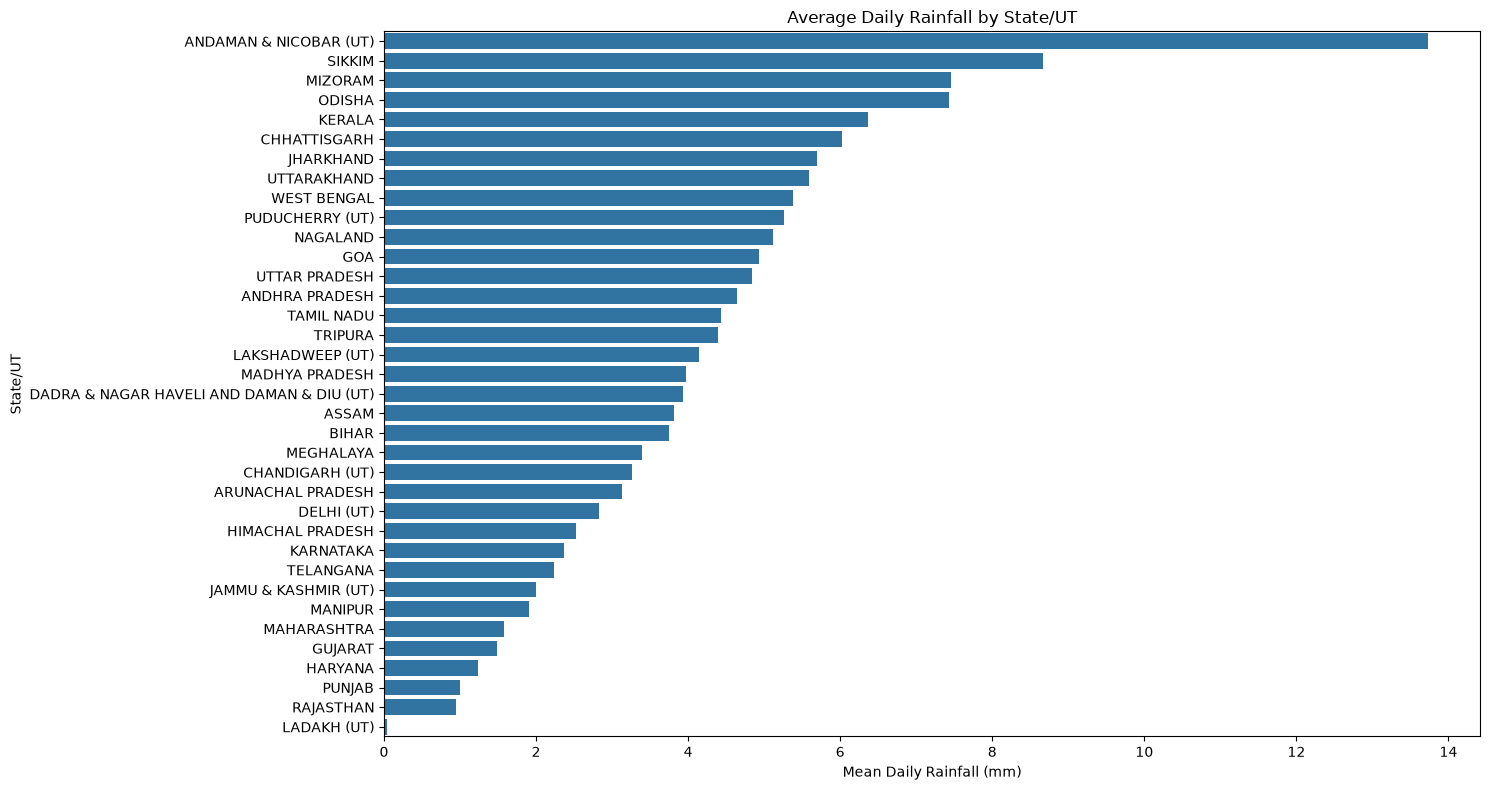

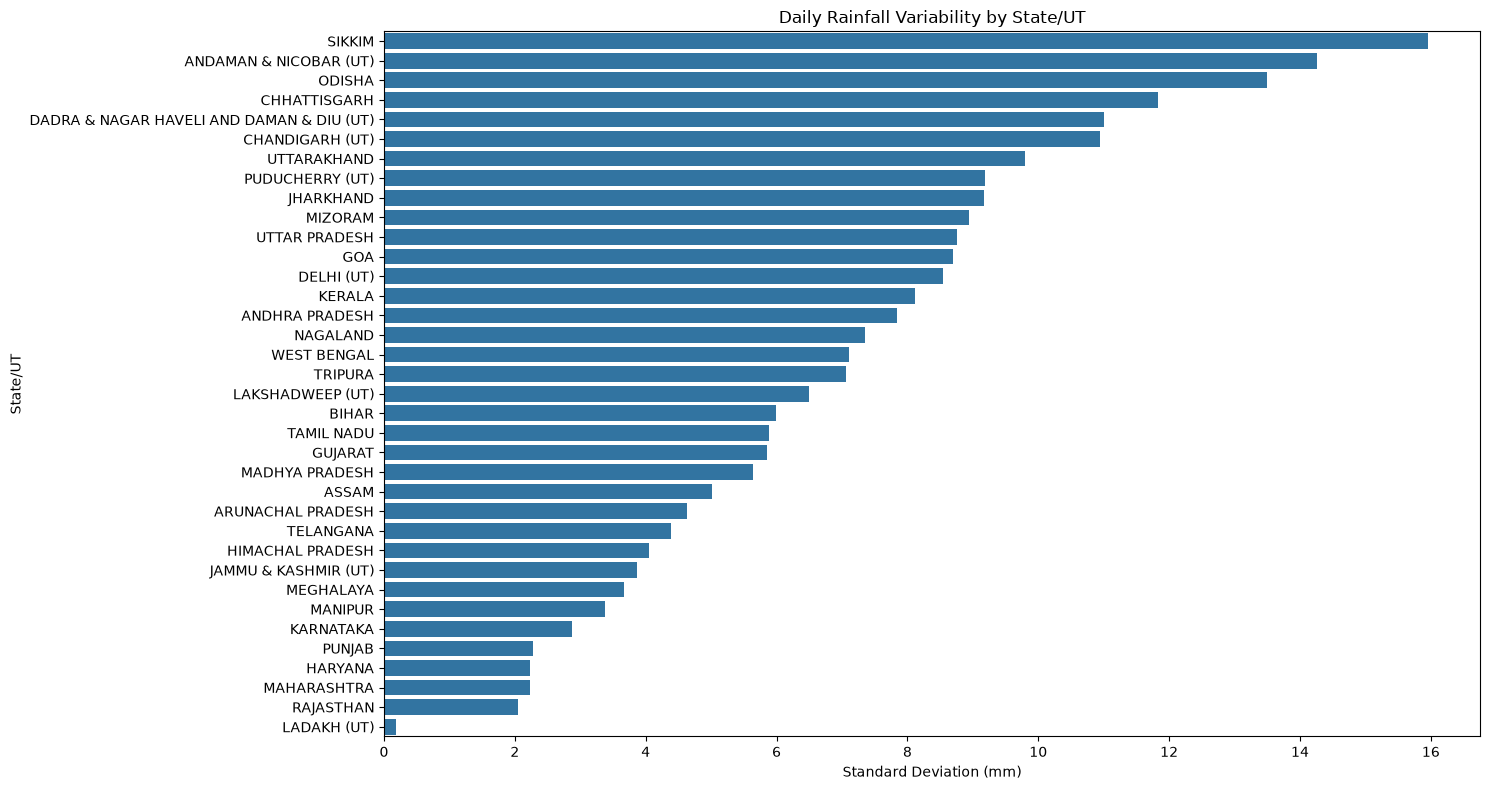

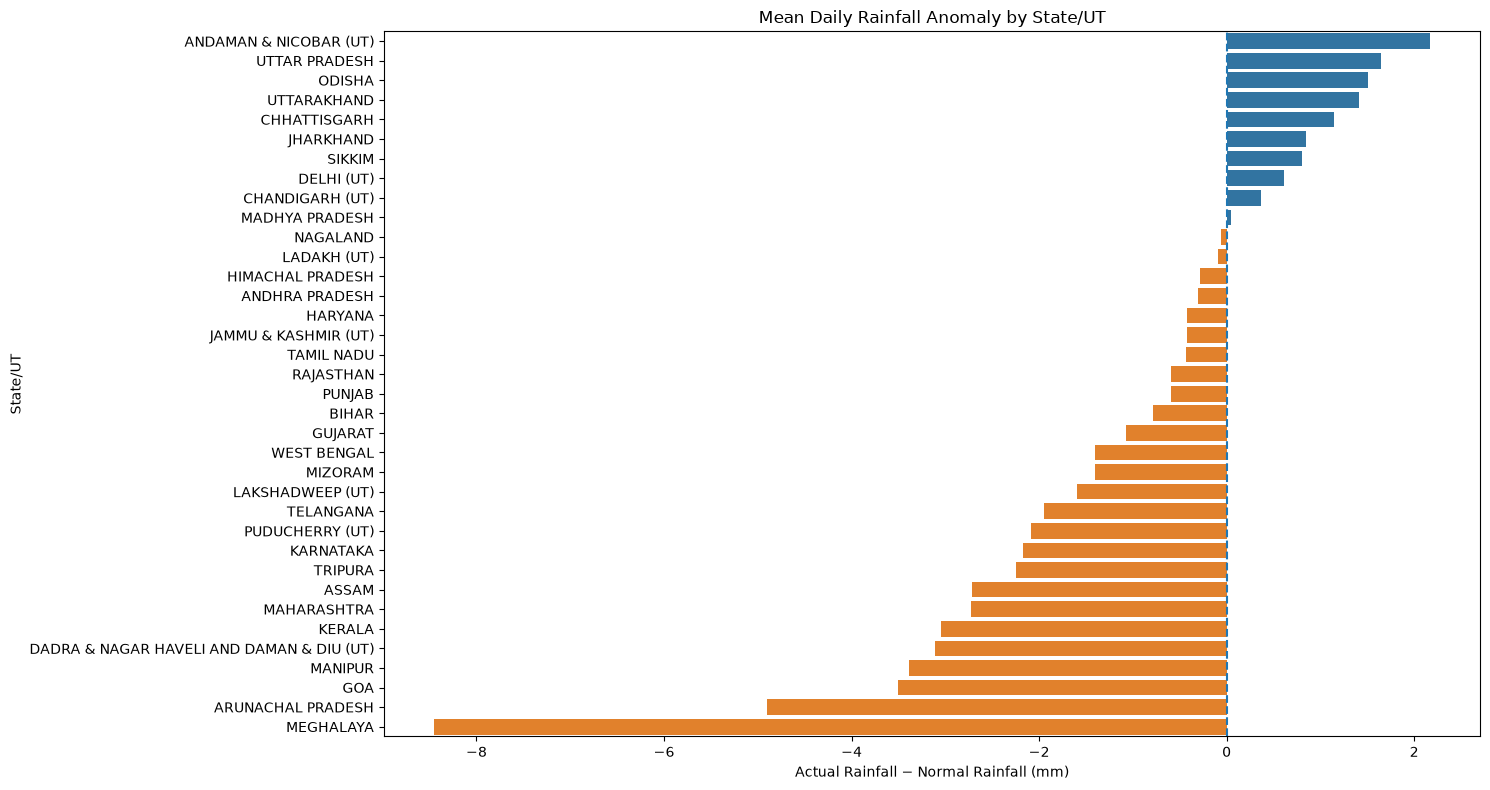

State-wise rainfall visualizations completed!


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mean actual rainfall
plot_data = state_variability.sort_values(
    "Mean_Rainfall", ascending=False
)

plt.figure(figsize=(15, 8))
sns.barplot(
    data=plot_data,
    x="Mean_Rainfall",
    y="State"
)
plt.title("Average Daily Rainfall by State/UT")
plt.xlabel("Mean Daily Rainfall (mm)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

# 2. Standard deviation
plot_data = state_variability.sort_values(
    "Std_Rainfall", ascending=False
)

plt.figure(figsize=(15, 8))
sns.barplot(
    data=plot_data,
    x="Std_Rainfall",
    y="State"
)
plt.title("Daily Rainfall Variability by State/UT")
plt.xlabel("Standard Deviation (mm)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

# 3. Mean rainfall anomaly
plot_data = state_variability.sort_values(
    "Mean_Anomaly_mm", ascending=False
)

plt.figure(figsize=(15, 8))
sns.barplot(
    data=plot_data,
    x="Mean_Anomaly_mm",
    y="State",
    hue=plot_data["Mean_Anomaly_mm"].apply(
        lambda x: "Above Normal" if x >= 0 else "Below Normal"
    ),
    legend=False
)
plt.axvline(0, linestyle="--")
plt.title("Mean Daily Rainfall Anomaly by State/UT")
plt.xlabel("Actual Rainfall − Normal Rainfall (mm)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

print("State-wise rainfall visualizations completed!")

### 11.1 Interactive Choropleth: India State-wise Actual Rainfall Distribution (2026)

This choropleth maps mean actual daily rainfall (mm/day) across Indian States and Union Territories from **19 August to 12 November 2026** (`85` reporting dates; `31 October 2026` missing) over official LGD State/UT boundaries (`public/data/india_states.geojson`). State and Union Territory names are normalized carefully prior to joining, unmatched geographical polygons remain explicitly excluded rather than filled with zero rainfall, and outputs are saved to `outputs_project2/figures/india_statewise_actual_rainfall_map.html` and `outputs_project2/figures/india_statewise_actual_rainfall_map.png`.

Reporting horizon: 2026-08-19 to 2026-11-12 (85 dates)
Geographical join audit: 36 / 36 GeoJSON States/UTs matched
Unmatched GeoJSON boundaries: []
Unmatched dataset States/UTs: []
Saved interactive choropleth HTML: outputs_project2\figures\india_statewise_actual_rainfall_map.html
Saved high-resolution static PNG: outputs_project2\figures\india_statewise_actual_rainfall_map.png


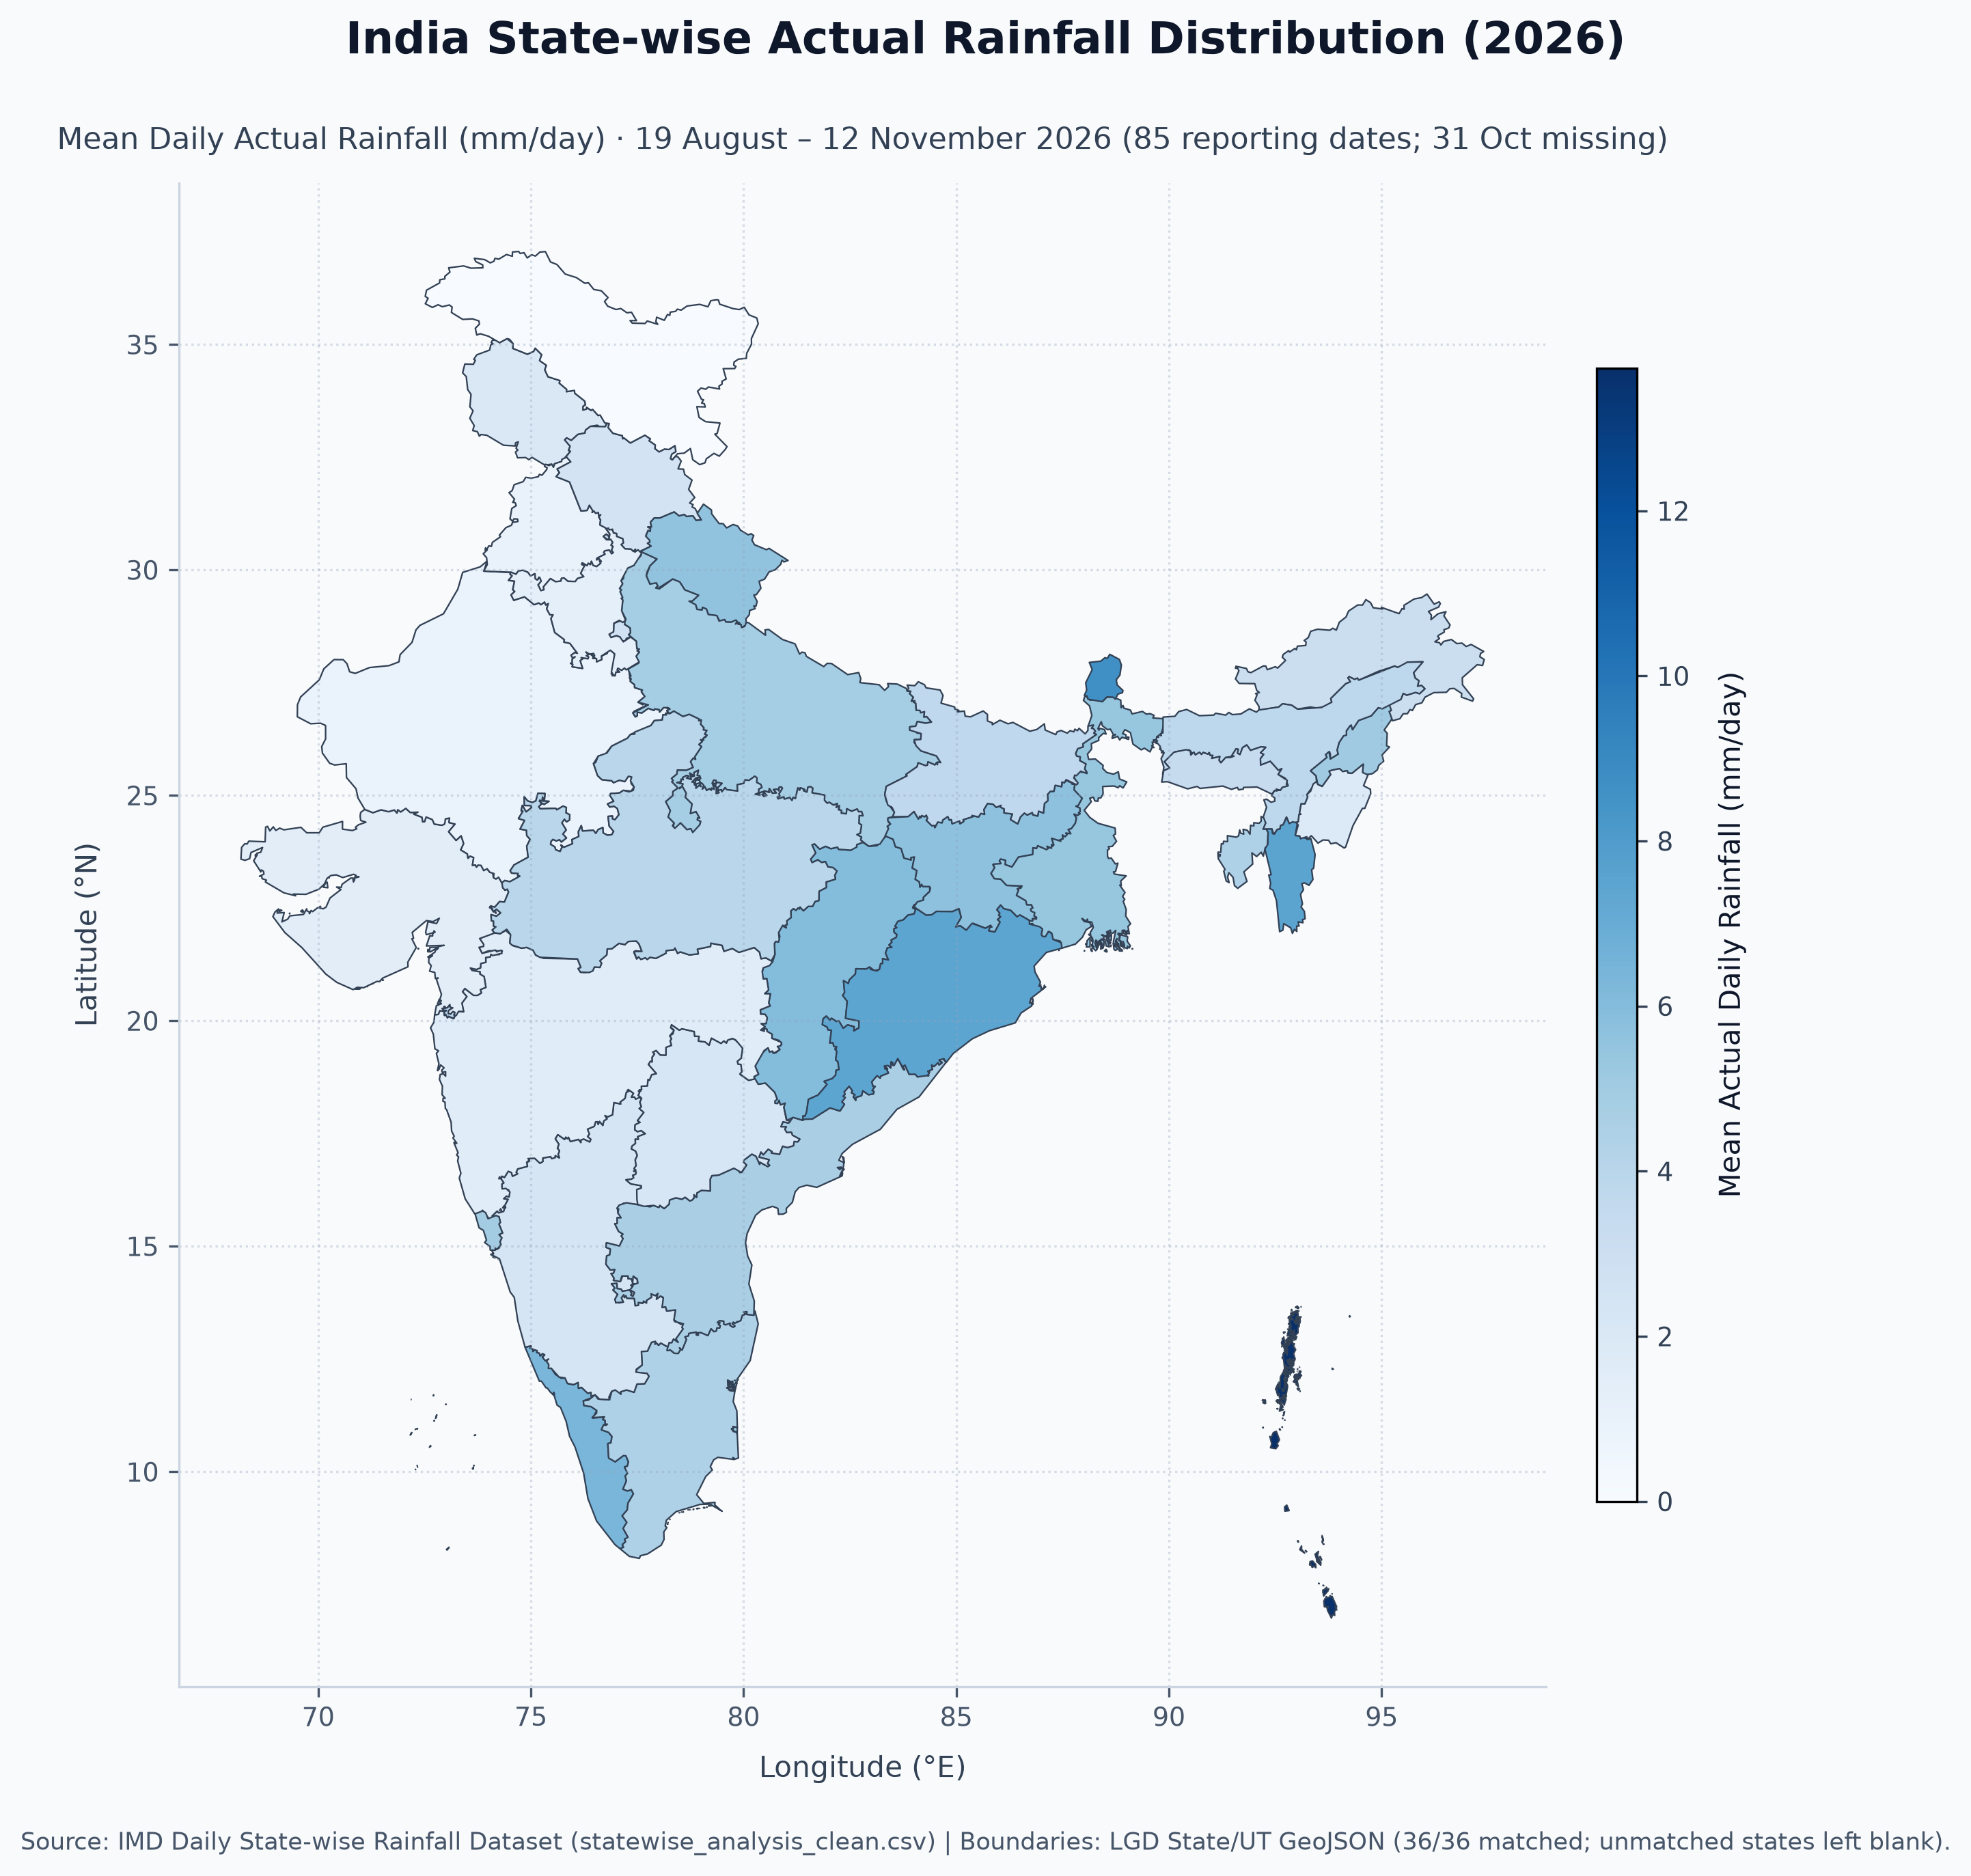

In [1]:
# ==============================================================================
# Interactive Choropleth: India State-wise Actual Rainfall Distribution (2026)
# ==============================================================================
import json
import os
import re
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path as MplPath
from shapely.geometry import shape

os.makedirs("outputs_project2/figures", exist_ok=True)

# 1. Reuse existing cleaned Project 2 daily state dataset (fallback to saved CSV if run standalone)
if "state_analysis" in globals():
    df_state_daily = state_analysis.copy()
elif "state_clean" in globals():
    df_state_daily = state_clean.copy()
else:
    df_state_daily = pd.read_csv(
        os.path.join("outputs_project2", "processed_data", "statewise_analysis_clean.csv")
    )

# 2. Compute State/UT mean actual rainfall, normal baseline, and anomaly (mm/day)
state_map_df = (
    df_state_daily
    .groupby("State", as_index=False)
    .agg(
        Observation_Count=("Daily Actual", "count"),
        Mean_Actual_Rainfall=("Daily Actual", "mean"),
        Mean_Normal_Rainfall=("Daily Normal", "mean"),
    )
)
state_map_df["Mean_Anomaly_mm"] = (
    state_map_df["Mean_Actual_Rainfall"] - state_map_df["Mean_Normal_Rainfall"]
)

# 3. Canonical name normalization handling UT suffixes and spelling variations
STATE_NAME_ALIASES = {
    "ANDAMANANDNICOBARISLANDS": "ANDAMANNICOBAR",
    "ANDAMANNICOBARISLANDS": "ANDAMANNICOBAR",
    "DADRAANDNAGARHAVELIANDDAMANANDDIU": "DADRANAGARHAVELIDAMANDIU",
    "THEDADRAANDNAGARHAVELIANDDAMANANDDIU": "DADRANAGARHAVELIDAMANDIU",
    "DADRANAGARHAVELIDAMANDIU": "DADRANAGARHAVELIDAMANDIU",
    "NCTOFDELHI": "DELHI",
    "ORISSA": "ODISHA",
    "PONDICHERRY": "PUDUCHERRY",
    "UTTARANCHAL": "UTTARAKHAND",
    "JAMMUANDKASHMIR": "JAMMUKASHMIR",
}

def normalize_state_key(name):
    s = str(name).upper().strip()
    s = re.sub(r"\(U\.?T\.?\)", "", s)
    s = re.sub(r"\bAND\b", "", s)
    s = re.sub(r"[^A-Z0-9]", "", s)
    return STATE_NAME_ALIASES.get(s, s)

state_map_df["join_key"] = state_map_df["State"].apply(normalize_state_key)

# 4. Load India State/UT GeoJSON boundaries cleanly
geojson_path = os.path.join("public", "data", "india_states.geojson")
with open(geojson_path, encoding="utf-8") as f:
    raw_geo = json.load(f)

geo_rows = []
clean_features = []
for feat in raw_geo["features"]:
    lgd_name = str(
        feat["properties"].get("lgd_name")
        or feat["properties"].get("State")
        or ""
    ).strip()
    geo_rows.append({"lgd_name": lgd_name, "join_key": normalize_state_key(lgd_name)})
    clean_features.append({
        "type": "Feature",
        "properties": {"lgd_name": lgd_name},
        "geometry": feat["geometry"],
    })

clean_geojson = {"type": "FeatureCollection", "features": clean_features}
geo_index_df = pd.DataFrame(geo_rows)

# Left-join onto boundaries so unmatched geometries remain NaN (never assigned zero)
merged_map_df = geo_index_df.merge(state_map_df, on="join_key", how="left")
matched_mask = merged_map_df["Mean_Actual_Rainfall"].notna()
matched_df = merged_map_df[matched_mask].copy()
unmatched_geo_df = merged_map_df[~matched_mask].copy()
unmatched_csv_df = state_map_df[
    ~state_map_df["join_key"].isin(set(geo_index_df["join_key"]))
].copy()

print(
    f"Reporting horizon: {df_state_daily['Date'].min()} to {df_state_daily['Date'].max()} "
    f"({df_state_daily['Date'].nunique()} dates)"
)
print(f"Geographical join audit: {len(matched_df)} / {len(geo_index_df)} GeoJSON States/UTs matched")
print("Unmatched GeoJSON boundaries:", unmatched_geo_df["lgd_name"].tolist())
print("Unmatched dataset States/UTs:", unmatched_csv_df["State"].tolist())

# 5. Interactive Plotly Choropleth Map
z_max = float(matched_df["Mean_Actual_Rainfall"].max())
fig = go.Figure()

fig.add_trace(
    go.Choropleth(
        geojson=clean_geojson,
        locations=matched_df["lgd_name"],
        featureidkey="properties.lgd_name",
        z=matched_df["Mean_Actual_Rainfall"],
        colorscale="Blues",
        zmin=0,
        zmax=z_max,
        marker_line_color="#334155",
        marker_line_width=0.75,
        colorbar=dict(
            title=dict(text="Mean Actual<br>(mm/day)", font=dict(size=12, color="#0f172a")),
            ticksuffix=" mm",
            len=0.68,
            thickness=16,
            x=0.86,
            bgcolor="rgba(255,255,255,0.85)",
            bordercolor="#cbd5e1",
            borderwidth=1,
        ),
        customdata=matched_df[
            ["State", "Mean_Normal_Rainfall", "Mean_Anomaly_mm", "Observation_Count"]
        ].to_numpy(),
        hovertemplate=(
            "<b>%{location}</b><br>"
            "<span style='color:#475569'>IMD Unit: %{customdata[0]}</span><br><br>"
            "Mean Actual Daily Rainfall: <b>%{z:.2f} mm/day</b><br>"
            "Mean Normal Rainfall: <b>%{customdata[1]:.2f} mm/day</b><br>"
            "Mean Rainfall Anomaly: <b>%{customdata[2]:+.2f} mm/day</b><br>"
            "Reporting Dates: %{customdata[3]:.0f}"
            "<extra></extra>"
        ),
        name="Mean Actual Rainfall",
    )
)

# Transparently render unmatched geometries in neutral grey rather than 0 mm/day
if len(unmatched_geo_df) > 0:
    fig.add_trace(
        go.Choropleth(
            geojson=clean_geojson,
            locations=unmatched_geo_df["lgd_name"],
            featureidkey="properties.lgd_name",
            z=[1] * len(unmatched_geo_df),
            colorscale=[[0, "#E2E8F0"], [1, "#E2E8F0"]],
            showscale=False,
            marker_line_color="#64748b",
            marker_line_width=0.75,
            hovertemplate=(
                "<b>%{location}</b><br>"
                "Status: <b>No matched data (missing)</b>"
                "<extra></extra>"
            ),
            name="No Data",
        )
    )

fig.update_geos(fitbounds="locations", visible=False, projection_type="mercator")
fig.update_layout(
    title=dict(
        text=(
            "India State-wise Actual Rainfall Distribution (2026)<br>"
            "<sup>Mean Daily Actual Rainfall (mm/day) · 19 August – 12 November 2026 "
            "(85 reporting dates; 31 October missing)</sup>"
        ),
        x=0.5,
        xanchor="center",
        font=dict(size=20, color="#0f172a"),
    ),
    paper_bgcolor="#f8fafc",
    geo_bgcolor="#f8fafc",
    height=760,
    margin=dict(l=20, r=20, t=90, b=70),
    annotations=[
        dict(
            text=(
                "Source: IMD Daily State-wise Rainfall Dataset (outputs_project2/processed_data/statewise_analysis_clean.csv) | "
                "Boundaries: LGD State/UT GeoJSON (missing matches excluded from colour scale, never assigned 0)."
            ),
            x=0.5,
            y=-0.04,
            xref="paper",
            yref="paper",
            showarrow=False,
            font=dict(size=11, color="#475569"),
        )
    ],
)

html_path = os.path.join("outputs_project2", "figures", "india_statewise_actual_rainfall_map.html")
fig.write_html(html_path, include_plotlyjs=True, full_html=True)
print(f"Saved interactive choropleth HTML: {html_path}")
fig.show()

# 6. High-Resolution Static PNG Export (300 DPI via Matplotlib + Shapely)
def polygon_to_mpl_path(poly):
    verts, codes = [], []
    for ring in [poly.exterior] + list(poly.interiors):
        coords = np.asarray(ring.coords)
        if len(coords) < 3:
            continue
        ring_codes = np.full(len(coords), MplPath.LINETO, dtype=np.uint8)
        ring_codes[0] = MplPath.MOVETO
        ring_codes[-1] = MplPath.CLOSEPOLY
        verts.append(coords)
        codes.append(ring_codes)
    if not verts:
        return None
    return MplPath(np.concatenate(verts), np.concatenate(codes))

val_lookup = dict(zip(merged_map_df["lgd_name"], merged_map_df["Mean_Actual_Rainfall"]))
matched_patches, matched_vals, missing_patches = [], [], []

for feat in clean_geojson["features"]:
    name = feat["properties"]["lgd_name"]
    val = val_lookup.get(name, np.nan)
    geom = shape(feat["geometry"])
    polys = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    for poly in polys:
        path = polygon_to_mpl_path(poly)
        if path is None:
            continue
        patch = PathPatch(path)
        if pd.isna(val):
            missing_patches.append(patch)
        else:
            matched_patches.append(patch)
            matched_vals.append(float(val))

fig_m, ax = plt.subplots(figsize=(10.5, 9.6), dpi=300)
fig_m.patch.set_facecolor("#f8fafc")
ax.set_facecolor("#f8fafc")

norm = mcolors.Normalize(vmin=0, vmax=z_max)
pc = PatchCollection(
    matched_patches,
    cmap=plt.get_cmap("Blues"),
    norm=norm,
    edgecolor="#334155",
    linewidth=0.55,
)
pc.set_array(np.array(matched_vals))
ax.add_collection(pc)

if missing_patches:
    pc_miss = PatchCollection(
        missing_patches,
        facecolor="#E2E8F0",
        edgecolor="#64748b",
        linewidth=0.55,
        hatch="///",
    )
    ax.add_collection(pc_miss)
    ax.legend(
        handles=[Patch(facecolor="#E2E8F0", edgecolor="#64748b", hatch="///", label="No Data (Unmatched)")],
        loc="lower left",
        frameon=True,
        fontsize=9,
    )

ax.autoscale_view()
ax.set_aspect(1.06)
ax.set_xlabel("Longitude (°E)", fontsize=10, color="#334155", labelpad=8)
ax.set_ylabel("Latitude (°N)", fontsize=10, color="#334155", labelpad=8)
ax.grid(True, linestyle=":", alpha=0.35, color="#94a3b8")
ax.tick_params(colors="#475569", labelsize=9)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#cbd5e1")

cbar = fig_m.colorbar(pc, ax=ax, shrink=0.72, pad=0.03, aspect=28)
cbar.set_label("Mean Actual Daily Rainfall (mm/day)", fontsize=10, color="#0f172a", labelpad=10)
cbar.ax.tick_params(labelsize=9, colors="#334155")

fig_m.subplots_adjust(top=0.89, bottom=0.09)
fig_m.suptitle(
    "India State-wise Actual Rainfall Distribution (2026)",
    fontsize=15.5,
    fontweight="bold",
    color="#0f172a",
    y=0.955,
)
ax.set_title(
    "Mean Daily Actual Rainfall (mm/day) · 19 August – 12 November 2026 (85 reporting dates; 31 Oct missing)",
    fontsize=10.5,
    color="#334155",
    pad=12,
)
fig_m.text(
    0.5,
    0.025,
    "Source: IMD Daily State-wise Rainfall Dataset (statewise_analysis_clean.csv) | "
    "Boundaries: LGD State/UT GeoJSON (36/36 matched; unmatched states left blank).",
    ha="center",
    fontsize=8.5,
    color="#475569",
)

png_path = os.path.join("outputs_project2", "figures", "india_statewise_actual_rainfall_map.png")
fig_m.savefig(png_path, dpi=300, bbox_inches="tight", facecolor=fig_m.get_facecolor())
print(f"Saved high-resolution static PNG: {png_path}")
plt.show()

#### Spatial Interpretation

- **Pronounced Maritime & Eastern Concentration:** Mean daily actual rainfall over the `85`-date observation window was highest in island, eastern-coastal, and northeastern monsoon zones, led by **Andaman & Nicobar Islands** (`13.73 mm/day`, anomaly `+2.17 mm/day`), **Sikkim** (`8.66 mm/day`, `+0.80 mm/day`), **Mizoram** (`7.46 mm/day`, `−1.41 mm/day`), **Odisha** (`7.43 mm/day`, `+1.50 mm/day`), and **Kerala** (`6.37 mm/day`, `−3.05 mm/day`).
- **Northwestern & Trans-Himalayan Dry Gradient:** Northwestern plains and arid trans-Himalayan zones recorded the lowest mean daily accumulations, notably **Ladakh** (`0.04 mm/day`), **Rajasthan** (`0.95 mm/day`), **Punjab** (`1.00 mm/day`), **Haryana** (`1.24 mm/day`), and **Gujarat** (`1.49 mm/day`).
- **Anomaly Divergence Across States:** Across all `36` matched States and Union Territories (state-level median mean rainfall `3.96 mm/day`), **26 units** averaged below their daily normal rainfall while **10 units** recorded positive mean anomalies (Andaman & Nicobar (+2.17 mm/day), Uttar Pradesh (+1.65 mm/day), Odisha (+1.50 mm/day), Uttarakhand (+1.42 mm/day), Chhattisgarh (+1.15 mm/day), Jharkhand (+0.85 mm/day), Sikkim (+0.80 mm/day), Delhi (+0.61 mm/day), Chandigarh (+0.36 mm/day), Madhya Pradesh (+0.05 mm/day)), underscoring geographically heterogeneous regional behaviour rather than a uniform surplus or deficit.

In [13]:
# Load district-wise rainfall dataset

district_analysis = district_clean.copy()

print("DISTRICT-WISE DATASET OVERVIEW")
print("=" * 60)

print("Dataset shape:", district_analysis.shape)
print("Number of states:", district_analysis["State"].nunique())
print("Number of districts:", district_analysis["District"].nunique())

print("\nDate range:")
print("Start:", district_analysis["Date"].min())
print("End:", district_analysis["Date"].max())

print("\nColumn names:")
print(district_analysis.columns.tolist())

print("\nFirst 5 records:")
display(district_analysis.head())

print("\nData types:")
display(district_analysis.dtypes)

print("\nMissing values:")
display(
    district_analysis.isnull().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nDistrict-wise dataset loaded successfully!")

DISTRICT-WISE DATASET OVERVIEW
Dataset shape: (61831, 22)
Number of states: 39
Number of districts: 728

Date range:
Start: 2026-08-19 00:00:00
End: 2026-11-12 00:00:00

Column names:
['State', 'District', 'Date', 'Daily Actual', 'Daily Normal', 'Daily Departure Per', 'Daily Category', 'Week Date', 'Weekly Actual', 'Weekly Normal', 'Weekly Departure Per', 'Weekly Category', 'Cumulative Date', 'Cumulative Actual', 'Cumulative Normal', 'Cumulative Departue Per', 'Cumulative Category', 'Monthly Date', 'Monthly Acutual', 'Monthly Normal', 'Monthly Departure Per', 'Monthly Category']

First 5 records:


,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly Normal,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,-94.0,LD,13-08-2026 To 19-08-2026,0.5,7.4,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 19-08-2026,186.1,141.5,31.0,E
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,-94.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,432.3,696.3,-38.0,D,From 01-08-2026 To 20-08-2026,186.6,150.9,24.0,E
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,-76.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 21-08-2026,189.0,160.8,18.0,N
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,31.0,E,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,444.0,713.3,-38.0,D,From 01-08-2026 To 22-08-2026,198.3,167.9,18.0,N
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,-83.0,LD,13-08-2026 To 19-08-2026,1.3,7.9,...,2026-06-01,445.3,721.2,-38.0,D,From 01-08-2026 To 23-08-2026,199.7,175.8,14.0,N



Data types:


State                                 str
District                              str
Date                       datetime64[us]
Daily Actual                      float64
Daily Normal                      float64
Daily Departure Per               float64
Daily Category                        str
Week Date                          string
Weekly Actual                     float64
Weekly Normal                     float64
Weekly Departure Per              float64
Weekly Category                       str
Cumulative Date                    string
Cumulative Actual                 float64
Cumulative Normal                 float64
Cumulative Departue Per           float64
Cumulative Category                   str
Monthly Date                       string
Monthly Acutual                   float64
Monthly Normal                    float64
Monthly Departure Per             float64
Monthly Category                      str
dtype: object


Missing values:


,Missing_Count
Daily Departure Per,727
Weekly Departure Per,556
Cumulative Departue Per,381
Monthly Departure Per,417



District-wise dataset loaded successfully!


In [14]:
# District-level data quality and coverage audit

print("DISTRICT DATA QUALITY AUDIT")
print("=" * 65)

# 1. Unique state-district combinations
district_pairs = district_analysis[
    ["State", "District"]
].drop_duplicates()

print("Unique state-district combinations:", len(district_pairs))
print("Unique state labels:", district_analysis["State"].nunique())
print("Unique district names:", district_analysis["District"].nunique())

# 2. Duplicate observations
duplicate_count = district_analysis.duplicated(
    subset=["State", "District", "Date"]
).sum()

print("\nDuplicate state-district-date records:", duplicate_count)

# 3. Records per district
records_per_district = (
    district_analysis
    .groupby(["State", "District"])
    .agg(
        Observation_Count=("Date", "count"),
        Unique_Dates=("Date", "nunique"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max")
    )
    .reset_index()
)

print("\nObservation count distribution:")
display(records_per_district["Observation_Count"].describe())

print("\nDistricts with the fewest observations:")
display(
    records_per_district
    .sort_values("Observation_Count")
    .head(15)
)

print("\nDistricts with the most observations:")
display(
    records_per_district
    .sort_values("Observation_Count", ascending=False)
    .head(15)
)

# 4. Daily rainfall category distribution
print("\nDaily rainfall category distribution:")
display(
    district_analysis["Daily Category"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

# 5. Check missing values in rainfall measurements
print("\nMissing rainfall measurement values:")
display(
    district_analysis[
        ["Daily Actual", "Daily Normal"]
    ].isnull().sum().to_frame("Missing_Count")
)

print("\nDistrict-level quality audit completed!")

DISTRICT DATA QUALITY AUDIT
Unique state-district combinations: 728
Unique state labels: 39
Unique district names: 728

Duplicate state-district-date records: 0

Observation count distribution:


count    728.000000
mean      84.932692
std        1.816061
min       36.000000
25%       85.000000
50%       85.000000
75%       85.000000
max       85.000000
Name: Observation_Count, dtype: float64


Districts with the fewest observations:


,State,District,Observation_Count,Unique_Dates,First_Date,Last_Date
555,TAMIL NADU,NAGAPATTINAM,36,36,2026-08-22,2026-11-12
719,WEST BENGAL,KOLKATA,85,85,2026-08-19,2026-11-12
718,WEST BENGAL,KALIMPONG,85,85,2026-08-19,2026-11-12
717,WEST BENGAL,JHARGRAM,85,85,2026-08-19,2026-11-12
716,WEST BENGAL,JALPAIGURI,85,85,2026-08-19,2026-11-12
715,WEST BENGAL,HUGLI,85,85,2026-08-19,2026-11-12
714,WEST BENGAL,HAORA,85,85,2026-08-19,2026-11-12
713,WEST BENGAL,EASTMEDNIPUR,85,85,2026-08-19,2026-11-12
712,WEST BENGAL,DARJEELING,85,85,2026-08-19,2026-11-12
711,WEST BENGAL,DAKSHIN DINAJPUR,85,85,2026-08-19,2026-11-12



Districts with the most observations:


,State,District,Observation_Count,Unique_Dates,First_Date,Last_Date
727,WEST BENGAL,UTTAR_DINAJPUR,85,85,2026-08-19,2026-11-12
0,ANDAMAN & NICOBAR,NICOBAR,85,85,2026-08-19,2026-11-12
1,ANDAMAN & NICOBAR,NORTH & MIDDLE ANDAMAN,85,85,2026-08-19,2026-11-12
2,ANDAMAN & NICOBAR,SOUTH ANDAMAN,85,85,2026-08-19,2026-11-12
3,ANDHRA PRADESH,ANAKAPALLI,85,85,2026-08-19,2026-11-12
4,ANDHRA PRADESH,ANANTAPURAMU,85,85,2026-08-19,2026-11-12
5,ANDHRA PRADESH,ANNAMAYYA DISTRICT,85,85,2026-08-19,2026-11-12
6,ANDHRA PRADESH,BAPATLA,85,85,2026-08-19,2026-11-12
711,WEST BENGAL,DAKSHIN DINAJPUR,85,85,2026-08-19,2026-11-12
710,WEST BENGAL,BIRBHUM,85,85,2026-08-19,2026-11-12



Daily rainfall category distribution:


,Record_Count
Daily Category,
NR,35177
LD,10820
LE,7662
D,3725
N,2122
E,1598
ND,727



Missing rainfall measurement values:


,Missing_Count
Daily Actual,0
Daily Normal,0



District-level quality audit completed!


In [15]:
# District-wise date coverage analysis

expected_dates = pd.date_range(
    start=district_analysis["Date"].min(),
    end=district_analysis["Date"].max(),
    freq="D"
)

coverage_rows = []

for (state, district), group in district_analysis.groupby(
    ["State", "District"]
):
    observed_dates = pd.DatetimeIndex(
        group["Date"].dropna().unique()
    )

    missing_dates = expected_dates.difference(observed_dates)

    coverage_rows.append({
        "State": state,
        "District": district,
        "Observation_Count": len(observed_dates),
        "Missing_Date_Count": len(missing_dates),
        "First_Date": observed_dates.min(),
        "Last_Date": observed_dates.max(),
        "Missing_Dates": ", ".join(
            date.strftime("%Y-%m-%d")
            for date in missing_dates
        )
    })

district_coverage = pd.DataFrame(coverage_rows)

print("DISTRICT-WISE COVERAGE SUMMARY")
print("=" * 60)

print("Expected reporting dates:", len(expected_dates))
print("Total districts:", len(district_coverage))
print(
    "Districts with complete coverage:",
    (district_coverage["Missing_Date_Count"] == 0).sum()
)
print(
    "Districts with missing dates:",
    (district_coverage["Missing_Date_Count"] > 0).sum()
)

print("\nDistricts with missing dates:")
display(
    district_coverage[
        district_coverage["Missing_Date_Count"] > 0
    ].sort_values("Missing_Date_Count", ascending=False)
)

# Save coverage audit
district_coverage.to_csv(
    os.path.join(table_dir, "districtwise_date_coverage.csv"),
    index=False
)

print("\nCoverage audit saved successfully!")

DISTRICT-WISE COVERAGE SUMMARY
Expected reporting dates: 86
Total districts: 728
Districts with complete coverage: 0
Districts with missing dates: 728

Districts with missing dates:


,State,District,Observation_Count,Missing_Date_Count,First_Date,Last_Date,Missing_Dates
555,TAMIL NADU,NAGAPATTINAM,36,50,2026-08-22,2026-11-12,"2026-08-19, 2026-08-20, 2026-08-21, 2026-08-23..."
711,WEST BENGAL,DAKSHIN DINAJPUR,85,1,2026-08-19,2026-11-12,2026-10-31
8,ANDHRA PRADESH,DR B R AMBEDKAR KONASEEMA,85,1,2026-08-19,2026-11-12,2026-10-31
727,WEST BENGAL,UTTAR_DINAJPUR,85,1,2026-08-19,2026-11-12,2026-10-31
0,ANDAMAN & NICOBAR,NICOBAR,85,1,2026-08-19,2026-11-12,2026-10-31
...,...,...,...,...,...,...,...
723,WEST BENGAL,NORTH 24 PRAGANA,85,1,2026-08-19,2026-11-12,2026-10-31
724,WEST BENGAL,PASHCHIM MEDINIPUR,85,1,2026-08-19,2026-11-12,2026-10-31
725,WEST BENGAL,PURULIYA,85,1,2026-08-19,2026-11-12,2026-10-31
726,WEST BENGAL,SOUTH 24 PARGANAS,85,1,2026-08-19,2026-11-12,2026-10-31



Coverage audit saved successfully!


In [16]:
# Missing-date pattern investigation

print("MISSING-DATE PATTERN ANALYSIS")
print("=" * 65)

# 1. Frequency of missing-date counts
print("\nDistribution of missing-date counts:")
display(
    district_coverage["Missing_Date_Count"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Districts")
)

# 2. Identify districts with exactly 85 observations
regular_districts = district_coverage[
    district_coverage["Observation_Count"] == 85
]

print("\nDistricts with 85 observations:", len(regular_districts))

print("\nMissing dates among these districts:")
display(
    regular_districts["Missing_Dates"]
    .value_counts()
    .to_frame("Number_of_Districts")
)

# 3. Inspect Nagapattinam
print("\nNagapattinam detailed coverage:")
display(
    district_coverage[
        district_coverage["District"] == "NAGAPATTINAM"
    ].to_string(index=False)
)

# 4. Inspect its actual available dates
nagapattinam_data = district_analysis[
    district_analysis["District"] == "NAGAPATTINAM"
].sort_values("Date")

print("\nNagapattinam available observations:")
display(nagapattinam_data[["Date", "Daily Actual", "Daily Normal"]])

# 5. Verify common missing date across regular districts
common_missing_dates = (
    regular_districts["Missing_Dates"]
    .value_counts()
)

print("\nMost common missing-date pattern:")
print(common_missing_dates.head(10))

print("\nMissing-date investigation completed!")

MISSING-DATE PATTERN ANALYSIS

Distribution of missing-date counts:


,Number_of_Districts
Missing_Date_Count,
1,727
50,1



Districts with 85 observations: 727

Missing dates among these districts:


,Number_of_Districts
Missing_Dates,
2026-10-31,727



Nagapattinam detailed coverage:


'     State     District  Observation_Count  Missing_Date_Count First_Date  Last_Date                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          Missing_Dates\nTAMIL NADU NAGAPATTINAM                 36                  50 2026-08-22 2026-11-12 2026-08-19, 2026-08-20, 2026-08-21, 2026-08-23, 2026-08-24, 2026-08-25, 2026-08-27, 2026-08-29, 2026-08-31, 2026-09-01, 2026-09-02, 2026-09-03, 2026-09-05, 2026-09-06, 2026-09-07, 2026-09-12, 2026-09-14, 2026-09-17, 2026-09-20, 2


Nagapattinam available observations:


,Date,Daily Actual,Daily Normal
47175,2026-08-22,0.0,4.3
47176,2026-08-26,0.0,2.7
47177,2026-08-28,0.0,2.1
47178,2026-08-30,0.0,2.2
47179,2026-09-04,0.0,2.1
47180,2026-09-08,2.7,3.3
47181,2026-09-09,0.0,3.7
47182,2026-09-10,0.1,4.0
47183,2026-09-11,0.0,4.1
47184,2026-09-13,0.0,2.3



Most common missing-date pattern:
Missing_Dates
2026-10-31    727
Name: count, dtype: int64

Missing-date investigation completed!


In [17]:
# Construct balanced district-wise analysis dataset

# Identify districts with exactly 85 observations
valid_districts = district_coverage.loc[
    district_coverage["Observation_Count"] == 85,
    ["State", "District"]
]

# Separate regular districts and Nagapattinam
district_balanced = district_analysis.merge(
    valid_districts,
    on=["State", "District"],
    how="inner"
).copy()

district_incomplete = district_analysis.merge(
    valid_districts,
    on=["State", "District"],
    how="left",
    indicator=True
).query("_merge == 'left_only'").drop(
    columns="_merge"
).copy()

# Verify balanced panel
district_counts = (
    district_balanced
    .groupby(["State", "District"])["Date"]
    .nunique()
)

print("BALANCED DISTRICT PANEL")
print("=" * 60)

print("Number of districts:", district_counts.size)
print("Total observations:", len(district_balanced))
print("Observations per district:", district_counts.unique())
print("Number of unique dates:", district_balanced["Date"].nunique())
print("Date range:",
      district_balanced["Date"].min(),
      "to",
      district_balanced["Date"].max())

print("\nBalanced panel verified:",
      district_counts.eq(85).all()
      and len(district_balanced) == 727 * 85)

print("\nIncomplete district records:")
print("Districts:", district_incomplete["District"].nunique())
print("Observations:", len(district_incomplete))

# Save both datasets
district_balanced.to_csv(
    os.path.join(processed_dir, "districtwise_balanced_analysis.csv"),
    index=False
)

district_incomplete.to_csv(
    os.path.join(processed_dir, "districtwise_incomplete_records.csv"),
    index=False
)

print("\nBalanced and incomplete datasets saved successfully!")

BALANCED DISTRICT PANEL
Number of districts: 727
Total observations: 61795
Observations per district: [85]
Number of unique dates: 85
Date range: 2026-08-19 00:00:00 to 2026-11-12 00:00:00

Balanced panel verified: True

Incomplete district records:
Districts: 1
Observations: 36

Balanced and incomplete datasets saved successfully!


In [18]:
# District-wise rainfall summary statistics

district_summary = (
    district_balanced
    .groupby(["State", "District"])
    .agg(
        Observation_Count=("Date", "count"),
        Mean_Actual_Rainfall=("Daily Actual", "mean"),
        Median_Actual_Rainfall=("Daily Actual", "median"),
        Std_Actual_Rainfall=("Daily Actual", "std"),
        Min_Daily_Rainfall=("Daily Actual", "min"),
        Max_Daily_Rainfall=("Daily Actual", "max"),
        Mean_Normal_Rainfall=("Daily Normal", "mean"),
        Total_Observed_Rainfall=("Daily Actual", "sum"),
        Rainy_Days_2_5mm=("Daily Actual", lambda x: (x >= 2.5).sum()),
        Zero_Rainfall_Days=("Daily Actual", lambda x: (x == 0).sum())
    )
    .reset_index()
)

district_summary["CV_Percent"] = (
    district_summary["Std_Actual_Rainfall"] /
    district_summary["Mean_Actual_Rainfall"].replace(0, np.nan)
) * 100

district_summary["Mean_Anomaly_mm"] = (
    district_summary["Mean_Actual_Rainfall"] -
    district_summary["Mean_Normal_Rainfall"]
)

district_summary["Rainy_Day_Percent"] = (
    district_summary["Rainy_Days_2_5mm"] / 85
) * 100

# Save summary
district_summary.to_csv(
    os.path.join(table_dir, "districtwise_rainfall_summary.csv"),
    index=False
)

print("DISTRICT-WISE SUMMARY GENERATED")
print("=" * 60)

print("Total districts:", len(district_summary))

print("\nTop 15 districts by mean actual rainfall:")
display(
    district_summary.sort_values(
        "Mean_Actual_Rainfall", ascending=False
    ).head(15).round(2)
)

print("\nBottom 15 districts by mean actual rainfall:")
display(
    district_summary.sort_values(
        "Mean_Actual_Rainfall"
    ).head(15).round(2)
)

print("\nSummary saved successfully!")

DISTRICT-WISE SUMMARY GENERATED
Total districts: 727

Top 15 districts by mean actual rainfall:


,State,District,Observation_Count,Mean_Actual_Rainfall,Median_Actual_Rainfall,Std_Actual_Rainfall,Min_Daily_Rainfall,Max_Daily_Rainfall,Mean_Normal_Rainfall,Total_Observed_Rainfall,Rainy_Days_2_5mm,Zero_Rainfall_Days,CV_Percent,Mean_Anomaly_mm,Rainy_Day_Percent
1,ANDAMAN & NICOBAR,NORTH & MIDDLE ANDAMAN,85,19.78,8.5,26.31,0.0,106.8,12.22,1681.1,61,13,133.02,7.56,71.76
8,ANDHRA PRADESH,DR B R AMBEDKAR KONASEEMA,85,12.08,0.0,32.49,0.0,203.2,7.14,1026.4,21,56,269.04,4.94,24.71
469,ODISHA,KORAPUT,85,11.63,1.3,28.40,0.0,203.7,6.30,988.3,39,28,244.22,5.33,45.88
2,ANDAMAN & NICOBAR,SOUTH ANDAMAN,85,11.24,7.4,13.64,0.0,71.4,11.78,955.7,59,11,121.29,-0.54,69.41
483,PUDUCHERRY,YANAM,85,11.24,0.0,25.30,0.0,140.6,7.73,955.2,28,57,225.12,3.51,32.94
472,ODISHA,NABARANGAPUR,85,10.98,0.4,30.61,0.0,231.9,6.43,933.5,31,39,278.74,4.55,36.47
23,ANDHRA PRADESH,SRIKAKULAM,85,10.76,0.8,27.90,0.0,155.7,6.38,914.4,34,29,259.37,4.38,40.00
423,MIZORAM,KOLASIB,85,10.75,0.8,17.00,0.0,61.7,9.43,913.6,38,34,158.16,1.31,44.71
632,UTTAR PRADESH,BANDA,85,10.56,0.0,26.07,0.0,153.1,3.22,897.9,24,51,246.80,7.34,28.24
27,ANDHRA PRADESH,WEST GODAVARI,85,10.13,0.4,26.51,0.0,170.4,5.84,861.3,29,34,261.59,4.30,34.12



Bottom 15 districts by mean actual rainfall:


,State,District,Observation_Count,Mean_Actual_Rainfall,Median_Actual_Rainfall,Std_Actual_Rainfall,Min_Daily_Rainfall,Max_Daily_Rainfall,Mean_Normal_Rainfall,Total_Observed_Rainfall,Rainy_Days_2_5mm,Zero_Rainfall_Days,CV_Percent,Mean_Anomaly_mm,Rainy_Day_Percent
36,ARUNACHAL PRADESH,LOWER DIBANG VALLEY,85,0.00,0.0,0.00,0.0,0.0,10.73,0.0,0,85,NaN,-10.73,0.00
443,NCT of DELHI,NORTH DELHI,85,0.00,0.0,0.00,0.0,0.0,2.20,0.0,0,85,NaN,-2.20,0.00
310,LADAKH,KARGIL,85,0.00,0.0,0.00,0.0,0.0,0.10,0.0,0,85,NaN,-0.10,0.00
31,ARUNACHAL PRADESH,DIBANG VALLEY,85,0.00,0.0,0.00,0.0,0.0,6.87,0.0,0,85,NaN,-6.87,0.00
311,LADAKH,LEH AND LADAKH,85,0.05,0.0,0.22,0.0,1.7,0.14,4.0,0,79,478.08,-0.09,0.00
523,RAJASTHAN,JAISELMER,85,0.07,0.0,0.50,0.0,4.4,0.60,6.0,1,82,707.26,-0.53,1.18
527,RAJASTHAN,JODHPUR,85,0.08,0.0,0.37,0.0,2.8,1.00,6.7,1,79,470.27,-0.92,1.18
188,HARYANA,BHIWANI,85,0.11,0.0,0.52,0.0,4.3,1.10,9.2,1,78,479.70,-0.99,1.18
510,RAJASTHAN,BARMER,85,0.15,0.0,0.93,0.0,8.0,0.96,12.5,2,81,630.31,-0.81,2.35
494,PUNJAB,KAPURTHALA,85,0.17,0.0,0.97,0.0,8.6,1.75,14.4,1,78,572.30,-1.58,1.18



Summary saved successfully!


In [19]:
# District-wise variability analysis

print("DISTRICT-WISE VARIABILITY ANALYSIS")
print("=" * 65)

# Overall distribution of district variability
display(
    district_summary[
        [
            "Mean_Actual_Rainfall",
            "Std_Actual_Rainfall",
            "CV_Percent",
            "Mean_Anomaly_mm",
            "Rainy_Day_Percent"
        ]
    ].describe().round(2)
)

# Highest absolute variability
print("\nTop 15 districts by standard deviation:")

display(
    district_summary
    .sort_values("Std_Actual_Rainfall", ascending=False)
    [[
        "State",
        "District",
        "Mean_Actual_Rainfall",
        "Std_Actual_Rainfall",
        "Max_Daily_Rainfall",
        "CV_Percent"
    ]]
    .head(15)
    .round(2)
)

# Highest relative variability
print("\nTop 15 districts by coefficient of variation:")

display(
    district_summary
    .dropna(subset=["CV_Percent"])
    .sort_values("CV_Percent", ascending=False)
    [[
        "State",
        "District",
        "Mean_Actual_Rainfall",
        "Std_Actual_Rainfall",
        "CV_Percent"
    ]]
    .head(15)
    .round(2)
)

# Highest positive and negative anomalies
print("\nTop 15 positive rainfall anomalies:")

display(
    district_summary
    .sort_values("Mean_Anomaly_mm", ascending=False)
    [[
        "State",
        "District",
        "Mean_Actual_Rainfall",
        "Mean_Normal_Rainfall",
        "Mean_Anomaly_mm"
    ]]
    .head(15)
    .round(2)
)

print("\nTop 15 negative rainfall anomalies:")

display(
    district_summary
    .sort_values("Mean_Anomaly_mm")
    [[
        "State",
        "District",
        "Mean_Actual_Rainfall",
        "Mean_Normal_Rainfall",
        "Mean_Anomaly_mm"
    ]]
    .head(15)
    .round(2)
)

print("\nDistrict-wise variability analysis completed!")

DISTRICT-WISE VARIABILITY ANALYSIS


,Mean_Actual_Rainfall,Std_Actual_Rainfall,CV_Percent,Mean_Anomaly_mm,Rainy_Day_Percent
count,727.00,727.00,723.00,727.00,727.00
mean,3.81,9.14,271.25,-0.80,23.76
std,2.47,5.50,93.85,2.50,11.69
min,0.00,0.00,111.85,-16.87,0.00
25%,1.75,5.19,207.02,-2.09,14.12
50%,3.49,8.44,248.08,-0.79,24.71
75%,5.26,11.82,307.44,0.50,31.76
max,19.78,34.81,921.95,7.56,71.76



Top 15 districts by standard deviation:


,State,District,Mean_Actual_Rainfall,Std_Actual_Rainfall,Max_Daily_Rainfall,CV_Percent
25,ANDHRA PRADESH,VISHAKHAPATNAM,9.70,34.81,226.0,358.90
8,ANDHRA PRADESH,DR B R AMBEDKAR KONASEEMA,12.08,32.49,203.2,269.04
472,ODISHA,NABARANGAPUR,10.98,30.61,231.9,278.74
469,ODISHA,KORAPUT,11.63,28.40,203.7,244.22
23,ANDHRA PRADESH,SRIKAKULAM,10.76,27.90,155.7,259.37
26,ANDHRA PRADESH,VIZIANAGARAM,8.94,27.39,215.7,306.37
27,ANDHRA PRADESH,WEST GODAVARI,10.13,26.51,170.4,261.59
3,ANDHRA PRADESH,ANAKAPALLI,8.25,26.40,213.8,320.18
460,ODISHA,GANJAM,9.97,26.34,196.0,264.29
1,ANDAMAN & NICOBAR,NORTH & MIDDLE ANDAMAN,19.78,26.31,106.8,133.02



Top 15 districts by coefficient of variation:


,State,District,Mean_Actual_Rainfall,Std_Actual_Rainfall,CV_Percent
261,JHARKHAND,SAHEBGANJ,0.23,2.08,921.95
497,PUNJAB,MOGA,0.37,2.65,708.92
523,RAJASTHAN,JAISELMER,0.07,0.50,707.26
432,NAGALAND,LONGLENG,0.24,1.62,680.43
170,GUJARAT,KACHCHH,1.49,10.11,676.51
510,RAJASTHAN,BARMER,0.15,0.93,630.31
168,GUJARAT,JAMNAGAR,1.26,7.27,575.39
494,PUNJAB,KAPURTHALA,0.17,0.97,572.30
496,PUNJAB,MANSA,0.42,2.40,572.10
161,GUJARAT,BOTAD,1.57,8.51,542.50



Top 15 positive rainfall anomalies:


,State,District,Mean_Actual_Rainfall,Mean_Normal_Rainfall,Mean_Anomaly_mm
1,ANDAMAN & NICOBAR,NORTH & MIDDLE ANDAMAN,19.78,12.22,7.56
632,UTTAR PRADESH,BANDA,10.56,3.22,7.34
352,MADHYA PRADESH,SATNA,9.76,3.86,5.89
669,UTTAR PRADESH,MAHOBA,8.30,2.53,5.77
345,MADHYA PRADESH,NIWARI,9.08,3.54,5.54
652,UTTAR PRADESH,HAMIRPUR,8.55,3.10,5.46
469,ODISHA,KORAPUT,11.63,6.30,5.33
119,CHHATISGARH,BALRAMPUR,9.90,4.62,5.28
630,UTTAR PRADESH,BALARAMPUR,9.90,4.62,5.28
695,UTTARAKHAND,BAGESHWAR,7.88,2.76,5.13



Top 15 negative rainfall anomalies:


,State,District,Mean_Actual_Rainfall,Mean_Normal_Rainfall,Mean_Anomaly_mm
419,MEGHALAYA,WEST JAINTIA HILLS,3.78,20.65,-16.87
411,MEGHALAYA,EAST JAINTIA HILLS,3.83,20.65,-16.81
407,MANIPUR,TAMENGLONG,3.46,16.45,-12.98
412,MEGHALAYA,EAST KHASI HILLS,4.50,16.16,-11.66
36,ARUNACHAL PRADESH,LOWER DIBANG VALLEY,0.00,10.73,-10.73
33,ARUNACHAL PRADESH,EAST SIANG,4.74,13.31,-8.57
44,ARUNACHAL PRADESH,WEST SIANG,1.50,9.27,-7.76
416,MEGHALAYA,SOUTH WEST GARO HILLS,0.80,8.49,-7.69
481,PUDUCHERRY,MAHE,1.31,8.38,-7.07
31,ARUNACHAL PRADESH,DIBANG VALLEY,0.00,6.87,-6.87



District-wise variability analysis completed!


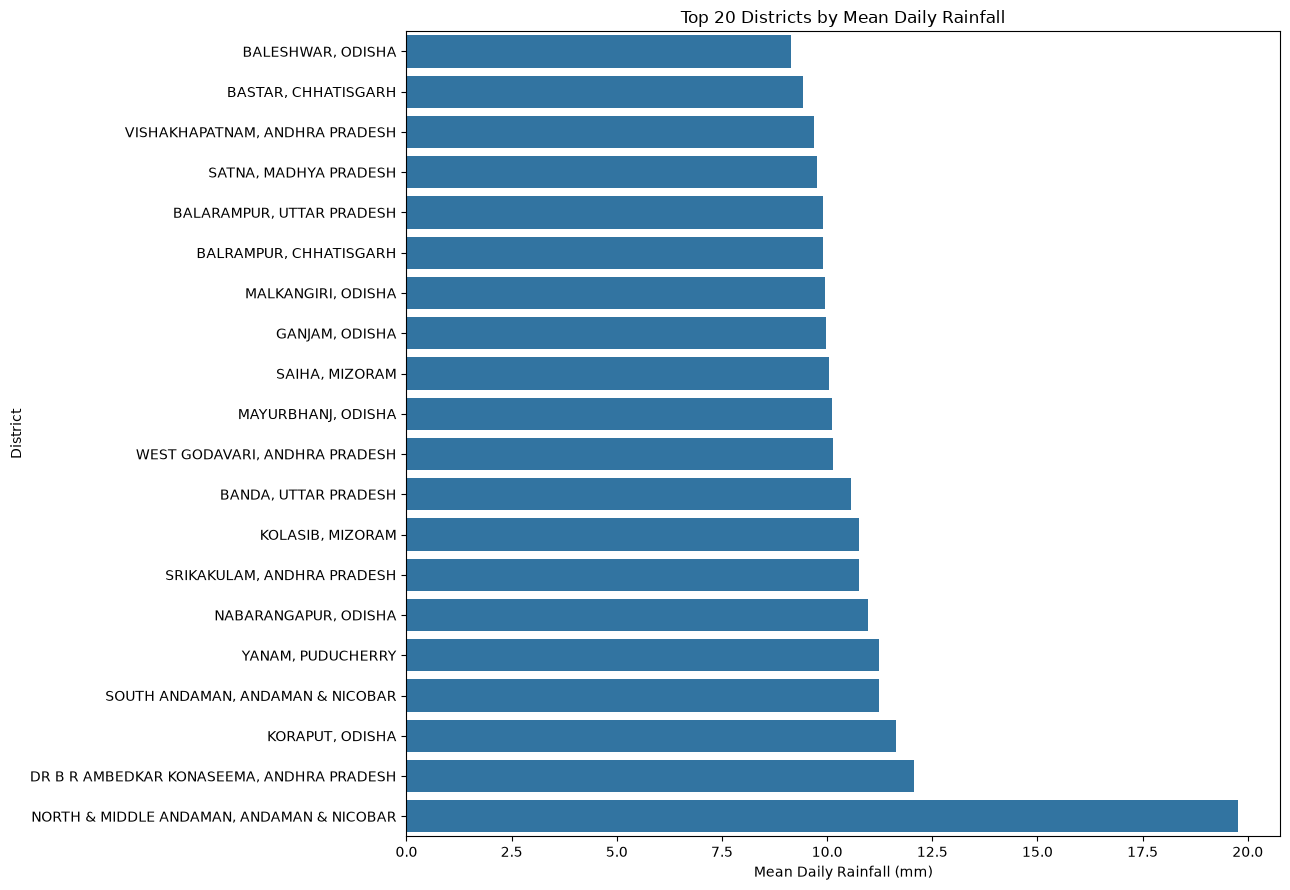

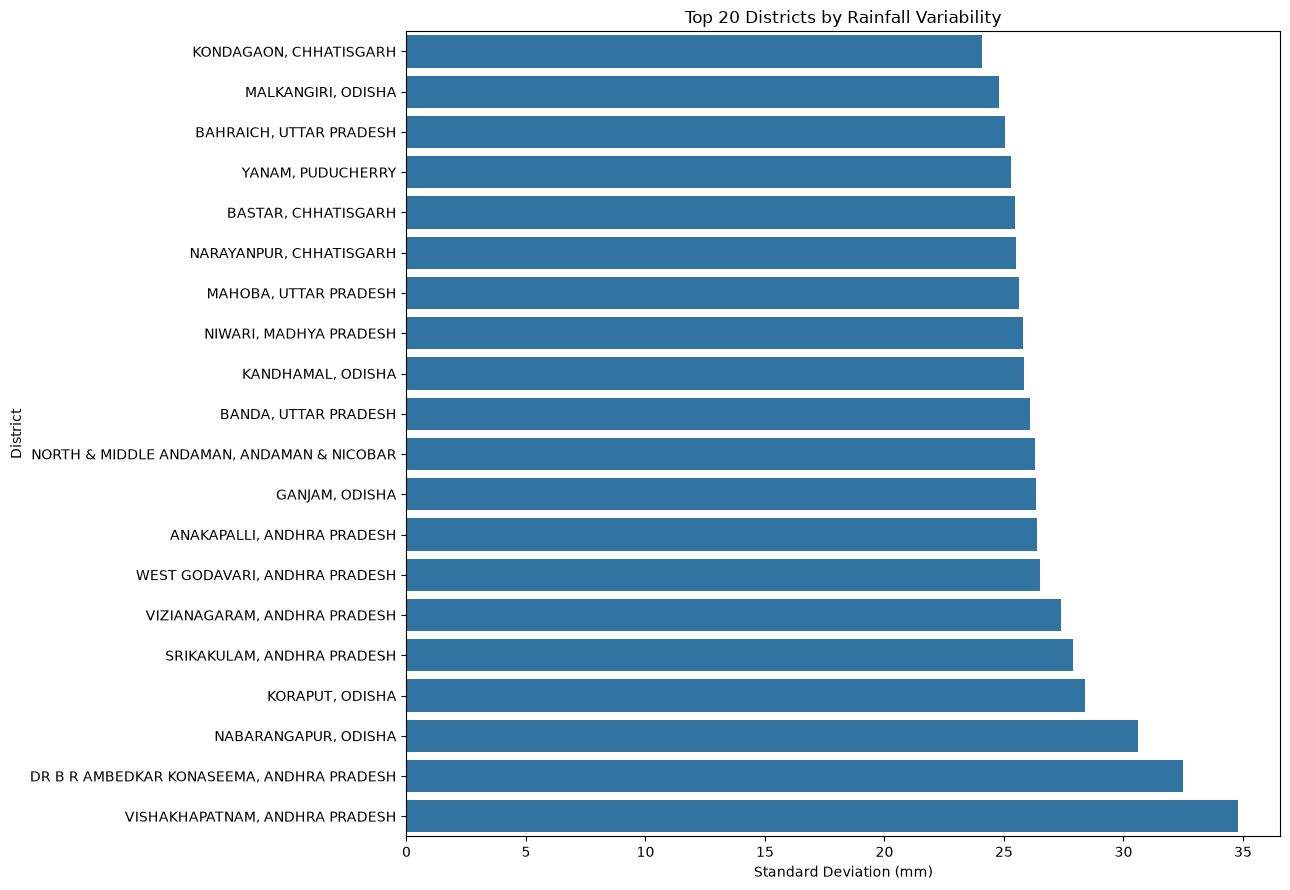

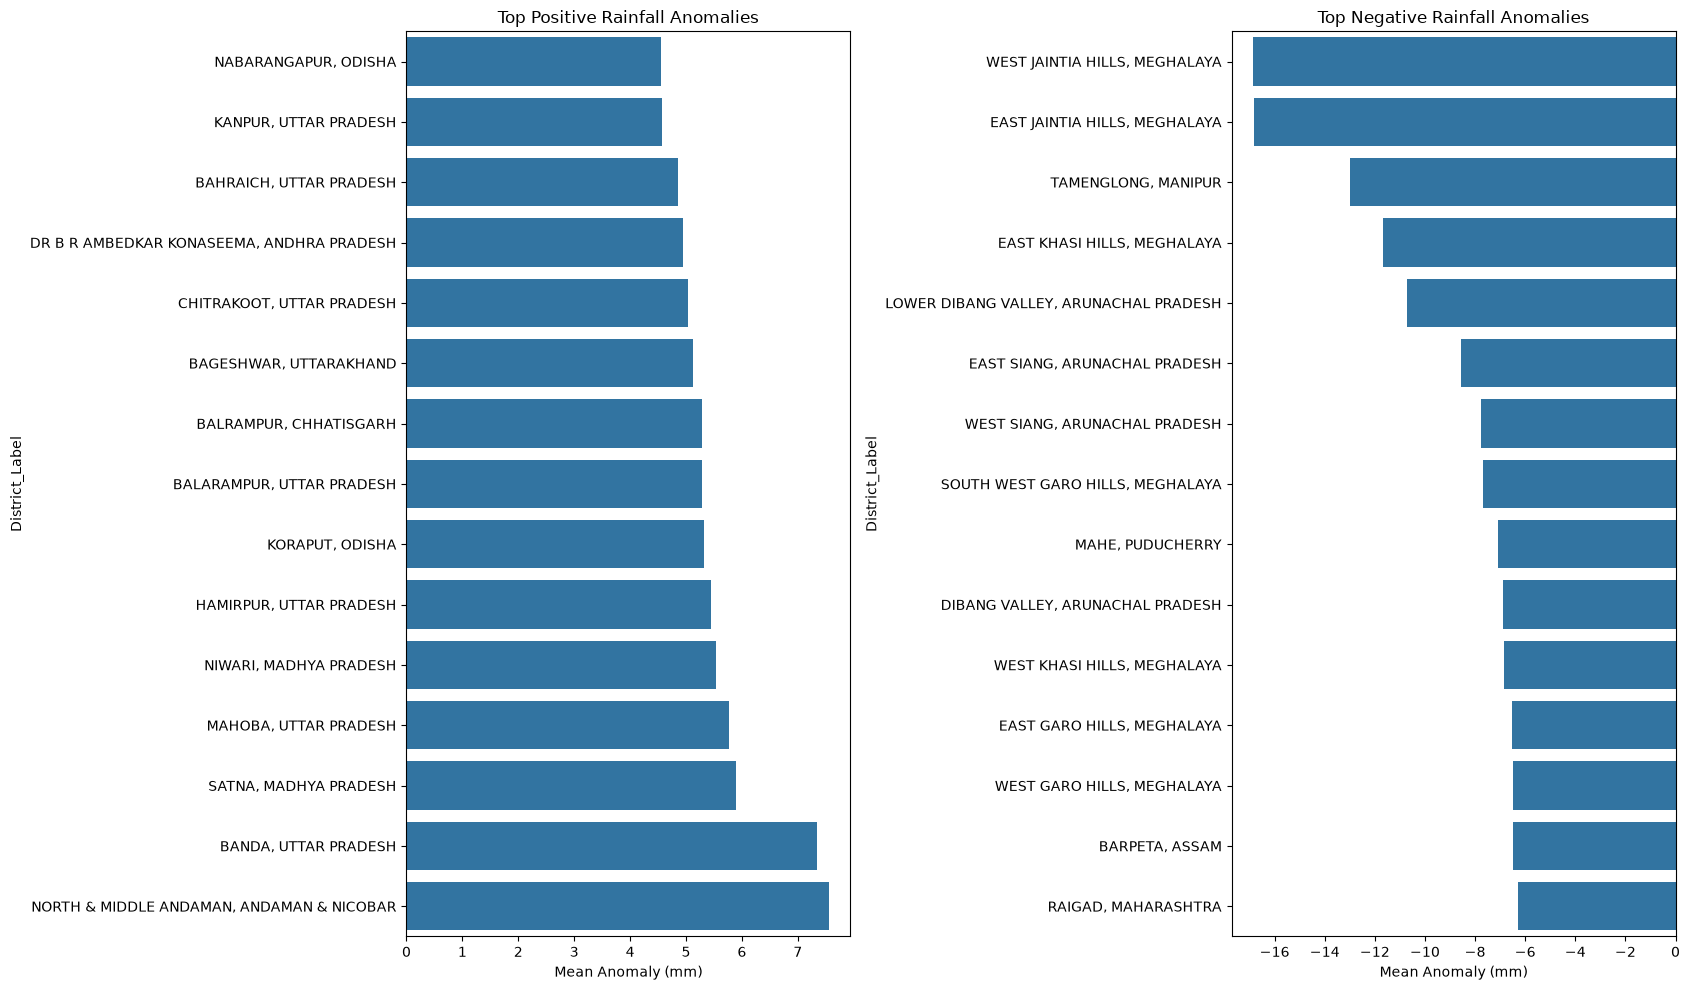

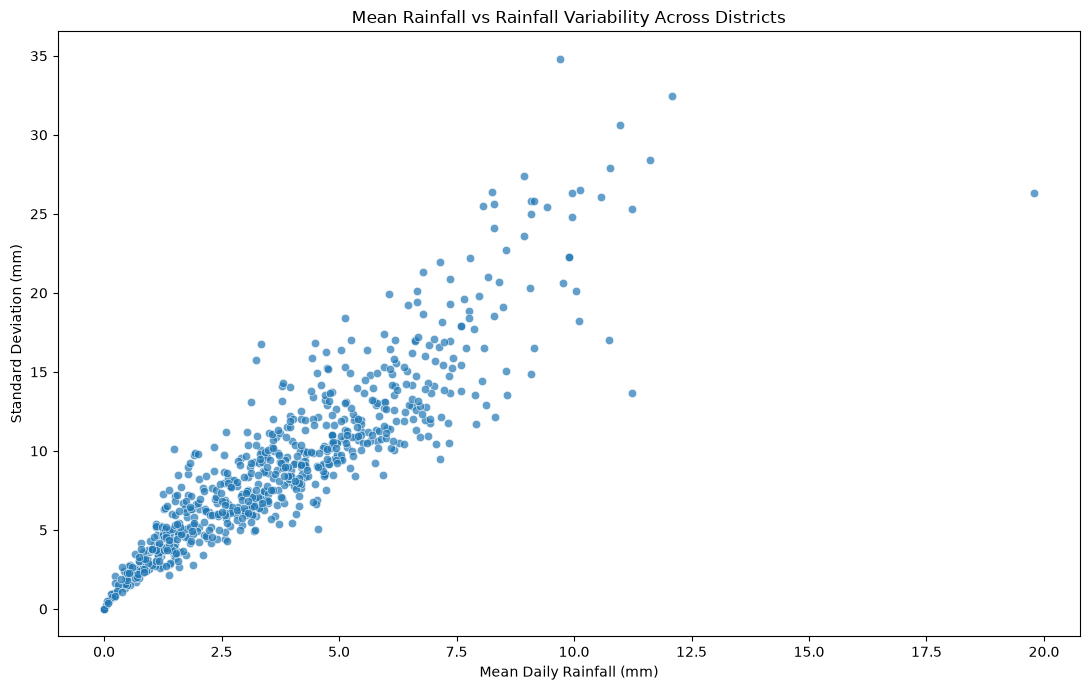

District-wise visualizations completed!


In [20]:
# District-wise rainfall visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# Create a unique district label
district_summary["District_Label"] = (
    district_summary["District"] + ", " +
    district_summary["State"]
)

# 1. Top 20 districts by mean rainfall
plot_data = district_summary.nlargest(
    20, "Mean_Actual_Rainfall"
).sort_values("Mean_Actual_Rainfall")

plt.figure(figsize=(13, 9))
sns.barplot(
    data=plot_data,
    x="Mean_Actual_Rainfall",
    y="District_Label"
)
plt.title("Top 20 Districts by Mean Daily Rainfall")
plt.xlabel("Mean Daily Rainfall (mm)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

# 2. Top 20 districts by standard deviation
plot_data = district_summary.nlargest(
    20, "Std_Actual_Rainfall"
).sort_values("Std_Actual_Rainfall")

plt.figure(figsize=(13, 9))
sns.barplot(
    data=plot_data,
    x="Std_Actual_Rainfall",
    y="District_Label"
)
plt.title("Top 20 Districts by Rainfall Variability")
plt.xlabel("Standard Deviation (mm)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

# 3. Positive and negative anomalies
positive = district_summary.nlargest(
    15, "Mean_Anomaly_mm"
).sort_values("Mean_Anomaly_mm")

negative = district_summary.nsmallest(
    15, "Mean_Anomaly_mm"
).sort_values("Mean_Anomaly_mm")

fig, axes = plt.subplots(1, 2, figsize=(17, 10))

sns.barplot(
    data=positive,
    x="Mean_Anomaly_mm",
    y="District_Label",
    ax=axes[0]
)
axes[0].set_title("Top Positive Rainfall Anomalies")
axes[0].set_xlabel("Mean Anomaly (mm)")

sns.barplot(
    data=negative,
    x="Mean_Anomaly_mm",
    y="District_Label",
    ax=axes[1]
)
axes[1].set_title("Top Negative Rainfall Anomalies")
axes[1].set_xlabel("Mean Anomaly (mm)")

plt.tight_layout()
plt.show()

# 4. Mean rainfall vs standard deviation
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=district_summary,
    x="Mean_Actual_Rainfall",
    y="Std_Actual_Rainfall",
    alpha=0.7
)

plt.title("Mean Rainfall vs Rainfall Variability Across Districts")
plt.xlabel("Mean Daily Rainfall (mm)")
plt.ylabel("Standard Deviation (mm)")
plt.tight_layout()
plt.show()

print("District-wise visualizations completed!")

In [21]:
# Investigation of districts with zero rainfall

zero_districts = (
    district_summary[
        district_summary["Mean_Actual_Rainfall"] == 0
    ][["State", "District", "Mean_Actual_Rainfall",
       "Mean_Normal_Rainfall", "Zero_Rainfall_Days",
       "Observation_Count", "Mean_Anomaly_mm"]]
    .copy()
)

print("DISTRICTS WITH ZERO OBSERVED RAINFALL")
print("=" * 70)

display(zero_districts)

# Inspect their daily records
zero_records = district_balanced.merge(
    zero_districts[["State", "District"]],
    on=["State", "District"],
    how="inner"
)

print("\nDAILY RECORDS FOR ZERO-RAINFALL DISTRICTS")
display(
    zero_records[
        ["State", "District", "Date", "Daily Actual",
         "Daily Normal", "Daily Category"]
    ].sort_values(["State", "District", "Date"])
)

# Check category distribution
print("\nDAILY CATEGORY DISTRIBUTION")
display(
    zero_records.groupby(
        ["State", "District", "Daily Category"]
    ).size().reset_index(name="Record_Count")
)

# Check whether normal rainfall is positive
print("\nNORMAL RAINFALL SUMMARY")
display(
    zero_records.groupby(
        ["State", "District"]
    ).agg(
        Actual_Min=("Daily Actual", "min"),
        Actual_Max=("Daily Actual", "max"),
        Normal_Mean=("Daily Normal", "mean"),
        Normal_Min=("Daily Normal", "min"),
        Normal_Max=("Daily Normal", "max"),
        Zero_Actual_Count=("Daily Actual", lambda x: (x == 0).sum())
    ).round(2)
)

print("\nZero-rainfall district investigation completed!")

DISTRICTS WITH ZERO OBSERVED RAINFALL


,State,District,Mean_Actual_Rainfall,Mean_Normal_Rainfall,Zero_Rainfall_Days,Observation_Count,Mean_Anomaly_mm
31,ARUNACHAL PRADESH,DIBANG VALLEY,0.0,6.870588,85,85,-6.870588
36,ARUNACHAL PRADESH,LOWER DIBANG VALLEY,0.0,10.732941,85,85,-10.732941
310,LADAKH,KARGIL,0.0,0.097647,85,85,-0.097647
443,NCT of DELHI,NORTH DELHI,0.0,2.200000,85,85,-2.200000



DAILY RECORDS FOR ZERO-RAINFALL DISTRICTS


,State,District,Date,Daily Actual,Daily Normal,Daily Category
0,ARUNACHAL PRADESH,DIBANG VALLEY,2026-08-19,0.0,2.5,ND
1,ARUNACHAL PRADESH,DIBANG VALLEY,2026-08-20,0.0,6.2,ND
2,ARUNACHAL PRADESH,DIBANG VALLEY,2026-08-21,0.0,2.7,ND
3,ARUNACHAL PRADESH,DIBANG VALLEY,2026-08-22,0.0,3.6,ND
4,ARUNACHAL PRADESH,DIBANG VALLEY,2026-08-23,0.0,4.0,ND
...,...,...,...,...,...,...
335,NCT of DELHI,NORTH DELHI,2026-11-08,0.0,1.3,ND
336,NCT of DELHI,NORTH DELHI,2026-11-09,0.0,0.0,ND
337,NCT of DELHI,NORTH DELHI,2026-11-10,0.0,0.0,ND
338,NCT of DELHI,NORTH DELHI,2026-11-11,0.0,0.0,ND



DAILY CATEGORY DISTRIBUTION


,State,District,Daily Category,Record_Count
0,ARUNACHAL PRADESH,DIBANG VALLEY,ND,85
1,ARUNACHAL PRADESH,LOWER DIBANG VALLEY,ND,85
2,LADAKH,KARGIL,ND,7
3,LADAKH,KARGIL,NR,78
4,NCT of DELHI,NORTH DELHI,ND,85



NORMAL RAINFALL SUMMARY


Actual_Min  Actual_Max  Normal_Mean  \
State             District                                                   
ARUNACHAL PRADESH DIBANG VALLEY               0.0         0.0         6.87   
                  LOWER DIBANG VALLEY         0.0         0.0        10.73   
LADAKH            KARGIL                      0.0         0.0         0.10   
NCT of DELHI      NORTH DELHI                 0.0         0.0         2.20   

                                       Normal_Min  Normal_Max  \
State             District                                      
ARUNACHAL PRADESH DIBANG VALLEY               0.0        19.9   
                  LOWER DIBANG VALLEY         0.5        29.7   
LADAKH            KARGIL                      0.0         1.7   
NCT of DELHI      NORTH DELHI                 0.0        12.4   

                                       Zero_Actual_Count  
State             District                                
ARUNACHAL PRADESH DIBANG VALLEY                       85  
                  LOWER DIBANG VALLEY                 85  
LADAKH            KARGIL                              85  
NCT of DELHI      NORTH DELHI                         85


Zero-rainfall district investigation completed!


## 21. District-wise Rainfall Departure Reliability Analysis

This section evaluates the consistency of reported daily rainfall departure percentages.

The reported departure percentage is compared with a recalculated departure based on available daily actual and normal rainfall:

Departure (%) = ((Actual Rainfall - Normal Rainfall) / Normal Rainfall) × 100

Observations with zero normal rainfall are excluded from recalculation because the percentage is undefined. Very small normal rainfall values are also flagged because they can produce unusually large departure percentages.

In [22]:
# District-wise departure reliability analysis

departure_check_district = district_balanced[
    [
        "State",
        "District",
        "Date",
        "Daily Actual",
        "Daily Normal",
        "Daily Departure Per"
    ]
].copy()

# Recalculate departure only when normal rainfall is positive
departure_check_district["Calculated_Departure_Per"] = np.where(
    departure_check_district["Daily Normal"] > 0,
    (
        (departure_check_district["Daily Actual"] -
         departure_check_district["Daily Normal"])
        / departure_check_district["Daily Normal"]
    ) * 100,
    np.nan
)

# Difference between reported and calculated departure
departure_check_district["Departure_Difference"] = (
    departure_check_district["Daily Departure Per"]
    - departure_check_district["Calculated_Departure_Per"]
)

# Flag zero and very small normal rainfall
departure_check_district["Normal_Rainfall_Flag"] = np.select(
    [
        departure_check_district["Daily Normal"] == 0,
        departure_check_district["Daily Normal"].between(0, 0.5, inclusive="right")
    ],
    [
        "Zero normal",
        "Very low normal (0-0.5 mm)"
    ],
    default="Normal above 0.5 mm"
)

print("DISTRICT-WISE DEPARTURE RELIABILITY")
print("=" * 70)

print("\nReported departure summary:")
display(
    departure_check_district["Daily Departure Per"].describe().round(2)
)

print("\nRecalculated departure summary:")
display(
    departure_check_district["Calculated_Departure_Per"].describe().round(2)
)

print("\nNormal rainfall flag counts:")
display(
    departure_check_district["Normal_Rainfall_Flag"].value_counts()
)

print("\nExtreme reported departures (absolute value > 500%):")

extreme_departures_district = (
    departure_check_district[
        departure_check_district["Daily Departure Per"].abs() > 500
    ]
    .sort_values(
        "Daily Departure Per",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(extreme_departures_district.head(20))

print("\nObservations with zero normal rainfall:")
display(
    departure_check_district[
        departure_check_district["Daily Normal"] == 0
    ].head(20)
)

print("\nDeparture reliability analysis completed!")

DISTRICT-WISE DEPARTURE RELIABILITY

Reported departure summary:


count    61068.00
mean       157.16
std       2627.83
min       -100.00
25%       -100.00
50%       -100.00
75%        -60.75
max      98300.00
Name: Daily Departure Per, dtype: float64


Recalculated departure summary:


count    57567.00
mean        41.31
std       1083.00
min       -100.00
25%       -100.00
50%       -100.00
75%        -55.56
max      61500.00
Name: Calculated_Departure_Per, dtype: float64


Normal rainfall flag counts:


Normal_Rainfall_Flag
Normal above 0.5 mm           50309
Very low normal (0-0.5 mm)     7258
Zero normal                    4228
Name: count, dtype: int64


Extreme reported departures (absolute value > 500%):


,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference,Normal_Rainfall_Flag
9167,BIHAR,SAHARSA,2026-10-30,9.8,0.0,98300.0,NaN,NaN,Zero normal
6787,BIHAR,ARWAL,2026-10-30,9.7,0.0,97233.0,NaN,NaN,Zero normal
16222,HARYANA,FARIDABAD,2026-10-30,9.6,0.0,95614.0,NaN,NaN,Zero normal
41462,PUNJAB,FARIDKOT,2026-10-25,9.6,0.0,95400.0,NaN,NaN,Zero normal
10017,CHHATISGARH,BALOD,2026-10-30,9.3,0.0,93186.0,NaN,NaN,Zero normal
41367,PUNJAB,BATHINDA,2026-10-15,9.1,0.0,90733.0,NaN,NaN,Zero normal
41448,PUNJAB,FARIDKOT,2026-10-11,9.0,0.0,89900.0,NaN,NaN,Zero normal
56682,UTTAR PRADESH,HAPUR,2026-10-30,9.0,0.0,89900.0,NaN,NaN,Zero normal
18926,JAMMU AND KASHMIR,BADGAM,2026-10-14,9.0,0.0,89650.0,NaN,NaN,Zero normal
44938,RAJASTHAN,KARAULI,2026-10-16,8.8,0.0,88233.0,NaN,NaN,Zero normal



Observations with zero normal rainfall:


,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Calculated_Departure_Per,Departure_Difference,Normal_Rainfall_Flag
2708,ARUNACHAL PRADESH,DIBANG VALLEY,2026-11-01,0.0,0.0,NaN,NaN,NaN,Zero normal
2800,ARUNACHAL PRADESH,EAST KAMENG,2026-11-08,0.0,0.0,-100.0,NaN,NaN,Zero normal
2879,ARUNACHAL PRADESH,EAST SIANG,2026-11-02,0.0,0.0,-100.0,NaN,NaN,Zero normal
3303,ARUNACHAL PRADESH,PAPUM-PARE,2026-11-01,1.8,0.0,17400.0,NaN,NaN,Zero normal
3395,ARUNACHAL PRADESH,TAWANG,2026-11-08,0.0,0.0,-100.0,NaN,NaN,Zero normal
3399,ARUNACHAL PRADESH,TAWANG,2026-11-12,0.0,0.0,-100.0,NaN,NaN,Zero normal
3735,ARUNACHAL PRADESH,WEST KAMENG,2026-11-08,0.0,0.0,-100.0,NaN,NaN,Zero normal
3814,ARUNACHAL PRADESH,WEST SIANG,2026-11-02,1.0,0.0,9900.0,NaN,NaN,Zero normal
3906,ASSAM,BAJALI,2026-11-09,0.0,0.0,-100.0,NaN,NaN,Zero normal
3994,ASSAM,BAKSA,2026-11-12,1.0,0.0,9900.0,NaN,NaN,Zero normal



Departure reliability analysis completed!


In [24]:
# Departure reliability by normal rainfall range

departure_analysis = departure_check_district.copy()

departure_analysis["Normal_Rainfall_Range"] = pd.cut(
    departure_analysis["Daily Normal"],
    bins=[-0.001, 0, 0.5, 2, 5, 10, np.inf],
    labels=[
        "Zero",
        "0-0.5 mm",
        "0.5-2 mm",
        "2-5 mm",
        "5-10 mm",
        "Above 10 mm"
    ]
)

# Absolute departure for identifying extreme values
departure_analysis["Absolute_Reported_Departure"] = (
    departure_analysis["Daily Departure Per"].abs()
)

departure_range_summary = (
    departure_analysis.groupby(
        "Normal_Rainfall_Range",
        observed=False
    )
    .agg(
        Observation_Count=("Daily Normal", "size"),
        Reported_Departure_Count=("Daily Departure Per", "count"),
        Mean_Reported_Departure=(
            "Daily Departure Per", "mean"
        ),
        Median_Reported_Departure=(
            "Daily Departure Per", "median"
        ),
        Extreme_Above_500=(
            "Absolute_Reported_Departure",
            lambda x: (x > 500).sum()
        ),
        Extreme_Above_1000=(
            "Absolute_Reported_Departure",
            lambda x: (x > 1000).sum()
        )
    )
    .reset_index()
)

print("DEPARTURE RELIABILITY BY NORMAL RAINFALL RANGE")
display(departure_range_summary.round(2))

# Overall extreme departure counts
print("\nOVERALL EXTREME DEPARTURE COUNTS")

for threshold in [100, 500, 1000, 5000]:
    count = (
        departure_analysis["Absolute_Reported_Departure"] > threshold
    ).sum()

    print(f"Absolute departure > {threshold}%: {count}")

import os

departure_range_summary.to_csv(
    os.path.join(
        table_dir,
        "district_departure_reliability_by_normal_range.csv"
    ),
    index=False
)

print("Departure reliability range analysis completed!")
print("File saved successfully!")

DEPARTURE RELIABILITY BY NORMAL RAINFALL RANGE


,Normal_Rainfall_Range,Observation_Count,Reported_Departure_Count,Mean_Reported_Departure,Median_Reported_Departure,Extreme_Above_500,Extreme_Above_1000
0,Zero,4228,4154,1721.89,-100.0,295,289
1,0-0.5 mm,7258,7215,354.69,-100.0,497,396
2,0.5-2 mm,10536,10457,41.46,-100.0,505,329
3,2-5 mm,16285,16133,-7.60,-100.0,610,261
4,5-10 mm,16894,16650,-10.86,-87.0,440,91
5,Above 10 mm,6594,6459,-37.86,-81.0,42,5



OVERALL EXTREME DEPARTURE COUNTS
Absolute departure > 100%: 6462
Absolute departure > 500%: 2389
Absolute departure > 1000%: 1371
Absolute departure > 5000%: 488
Departure reliability range analysis completed!
File saved successfully!


In [25]:
# District-wise daily temporal rainfall analysis

daily_district_stats = (
    district_balanced.groupby("Date")
    .agg(
        Mean_Rainfall=("Daily Actual", "mean"),
        Median_Rainfall=("Daily Actual", "median"),
        Maximum_Rainfall=("Daily Actual", "max"),
        Minimum_Rainfall=("Daily Actual", "min"),
        Rainfall_Std=("Daily Actual", "std"),
        Mean_Normal=("Daily Normal", "mean"),
        Total_District_Rainfall=("Daily Actual", "sum"),
        Rainy_Districts=(
            "Daily Actual",
            lambda x: (x >= 2.5).sum()
        ),
        Zero_Rainfall_Districts=(
            "Daily Actual",
            lambda x: (x == 0).sum()
        ),
        District_Count=("District", "count")
    )
    .reset_index()
)

daily_district_stats["Rainy_District_Percent"] = (
    daily_district_stats["Rainy_Districts"]
    / daily_district_stats["District_Count"]
) * 100

print("DAILY DISTRICT-WISE RAINFALL SUMMARY")
display(daily_district_stats.describe().round(2))

print("\nTOP 10 DATES BY MEAN DAILY RAINFALL")
display(
    daily_district_stats.nlargest(
        10, "Mean_Rainfall"
    ).round(2)
)

print("\nTOP 10 DATES BY MAXIMUM DISTRICT RAINFALL")
display(
    daily_district_stats.nlargest(
        10, "Maximum_Rainfall"
    ).round(2)
)

print("\nTOP 10 DATES BY NUMBER OF RAINY DISTRICTS")
display(
    daily_district_stats.nlargest(
        10, "Rainy_Districts"
    ).round(2)
)

# Save daily statistics
daily_district_stats.to_csv(
    os.path.join(
        processed_dir,
        "districtwise_daily_temporal_statistics.csv"
    ),
    index=False
)

print("\nDaily temporal statistics saved successfully!")

DAILY DISTRICT-WISE RAINFALL SUMMARY


,Date,Mean_Rainfall,Median_Rainfall,Maximum_Rainfall,Minimum_Rainfall,Rainfall_Std,Mean_Normal,Total_District_Rainfall,Rainy_Districts,Zero_Rainfall_Districts,District_Count,Rainy_District_Percent
count,85,85.00,85.00,85.00,85.0,85.00,85.00,85.00,85.00,85.00,85.0,85.00
mean,2026-09-30 03:23:17.647058,3.81,0.47,88.13,0.0,8.96,4.61,2766.81,172.71,433.05,727.0,23.76
min,2026-08-19 00:00:00,0.20,0.00,19.50,0.0,1.73,0.96,147.60,11.00,156.00,727.0,1.51
25%,2026-09-09 00:00:00,1.46,0.00,50.10,0.0,5.05,2.23,1061.30,73.00,284.00,727.0,10.04
50%,2026-09-30 00:00:00,2.81,0.00,78.40,0.0,8.10,4.14,2045.50,156.00,447.00,727.0,21.46
75%,2026-10-21 00:00:00,5.75,0.60,111.60,0.0,11.75,6.91,4177.70,272.00,584.00,727.0,37.41
max,2026-11-12 00:00:00,13.83,3.90,231.90,0.0,27.86,8.68,10057.90,413.00,674.00,727.0,56.81
std,NaN,3.11,0.80,47.39,0.0,5.39,2.48,2262.90,112.49,165.17,0.0,15.47



TOP 10 DATES BY MEAN DAILY RAINFALL


C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\3267547109.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,Date,Mean_Rainfall,Median_Rainfall,Maximum_Rainfall,Minimum_Rainfall,Rainfall_Std,Mean_Normal,Total_District_Rainfall,Rainy_Districts,Zero_Rainfall_Districts,District_Count,Rainy_District_Percent
38,2026-09-26,13.83,0.6,193.1,0.0,27.86,5.51,10057.9,311,313,727,42.78
37,2026-09-25,13.68,0.6,231.9,0.0,26.22,5.95,9941.9,310,308,727,42.64
36,2026-09-24,11.42,1.5,211.0,0.0,21.89,6.07,8303.0,333,284,727,45.80
6,2026-08-25,9.85,3.9,123.9,0.0,15.81,7.87,7163.6,413,160,727,56.81
5,2026-08-24,9.30,3.9,132.3,0.0,13.97,8.50,6763.6,413,156,727,56.81
13,2026-09-01,9.05,0.4,122.0,0.0,16.01,7.41,6576.0,307,308,727,42.23
14,2026-09-02,8.77,1.4,129.3,0.0,15.41,7.38,6374.5,323,213,727,44.43
0,2026-08-19,8.45,2.1,122.5,0.0,15.87,8.68,6142.5,354,195,727,48.69
39,2026-09-27,8.45,0.0,137.6,0.0,21.26,4.69,6142.0,221,394,727,30.40
12,2026-08-31,7.41,1.0,112.5,0.0,13.22,7.21,5389.2,295,279,727,40.58



TOP 10 DATES BY MAXIMUM DISTRICT RAINFALL


... (2 outputs left out)


TOP 10 DATES BY NUMBER OF RAINY DISTRICTS


C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\3267547109.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,Date,Mean_Rainfall,Median_Rainfall,Maximum_Rainfall,Minimum_Rainfall,Rainfall_Std,Mean_Normal,Total_District_Rainfall,Rainy_Districts,Zero_Rainfall_Districts,District_Count,Rainy_District_Percent
5,2026-08-24,9.30,3.9,132.3,0.0,13.97,8.50,6763.6,413,156,727,56.81
6,2026-08-25,9.85,3.9,123.9,0.0,15.81,7.87,7163.6,413,160,727,56.81
24,2026-09-12,7.04,2.4,116.6,0.0,11.78,6.91,5115.3,360,224,727,49.52
0,2026-08-19,8.45,2.1,122.5,0.0,15.87,8.68,6142.5,354,195,727,48.69
4,2026-08-23,6.89,2.2,107.9,0.0,12.46,8.37,5007.3,350,196,727,48.14
36,2026-09-24,11.42,1.5,211.0,0.0,21.89,6.07,8303.0,333,284,727,45.80
7,2026-08-26,6.24,1.9,110.2,0.0,11.75,7.68,4534.9,331,175,727,45.53
14,2026-09-02,8.77,1.4,129.3,0.0,15.41,7.38,6374.5,323,213,727,44.43
38,2026-09-26,13.83,0.6,193.1,0.0,27.86,5.51,10057.9,311,313,727,42.78
37,2026-09-25,13.68,0.6,231.9,0.0,26.22,5.95,9941.9,310,308,727,42.64



Daily temporal statistics saved successfully!


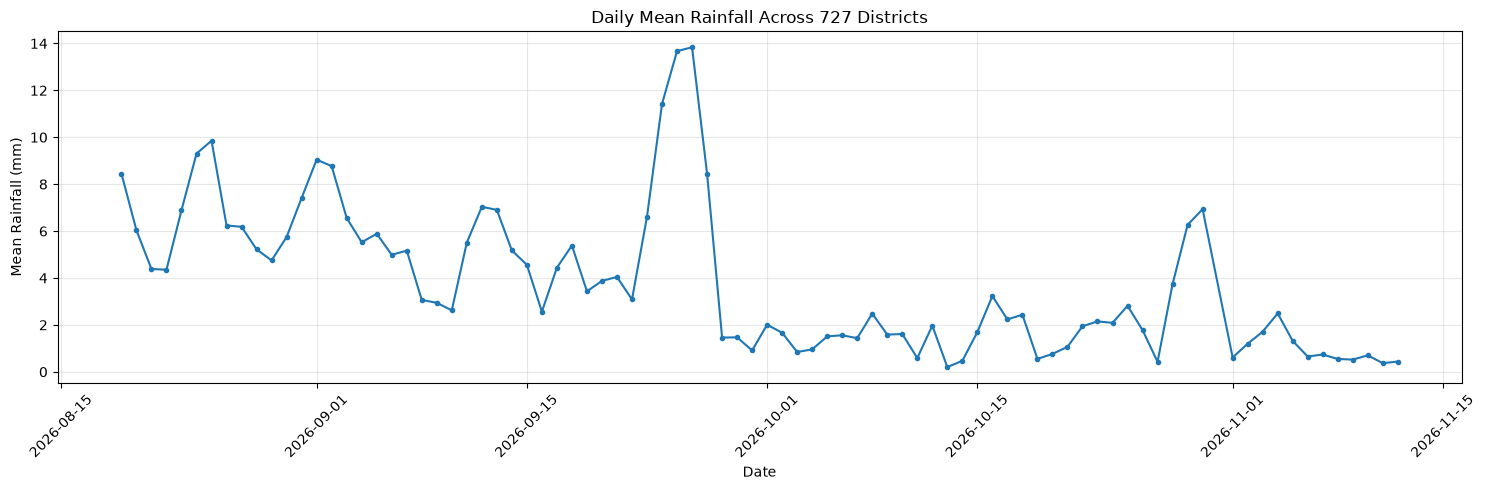

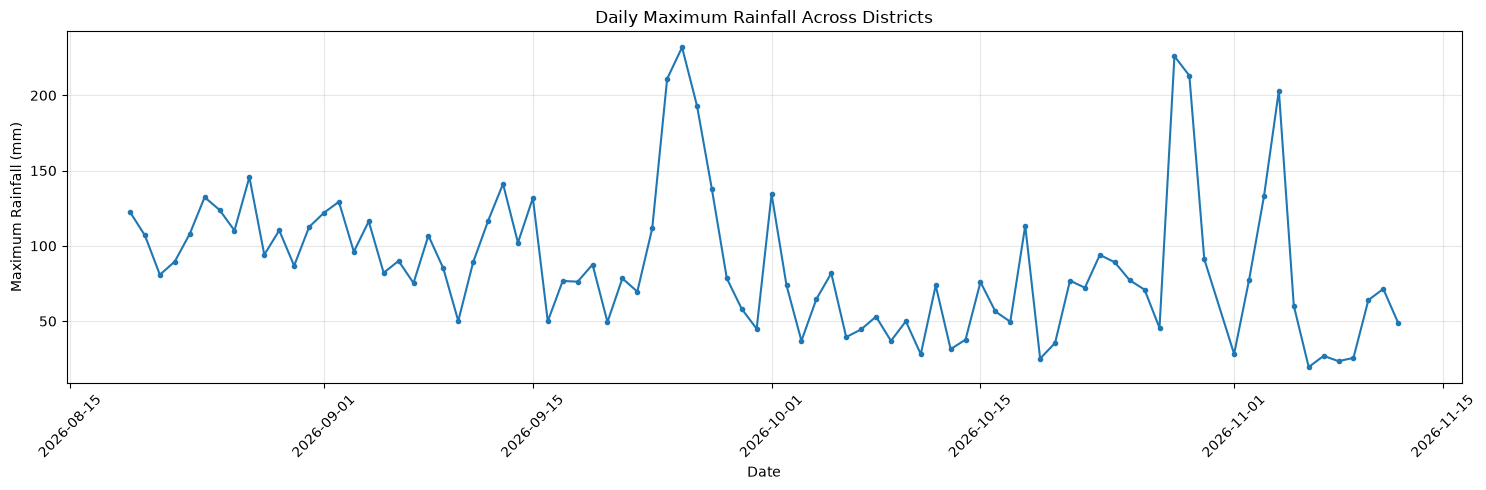

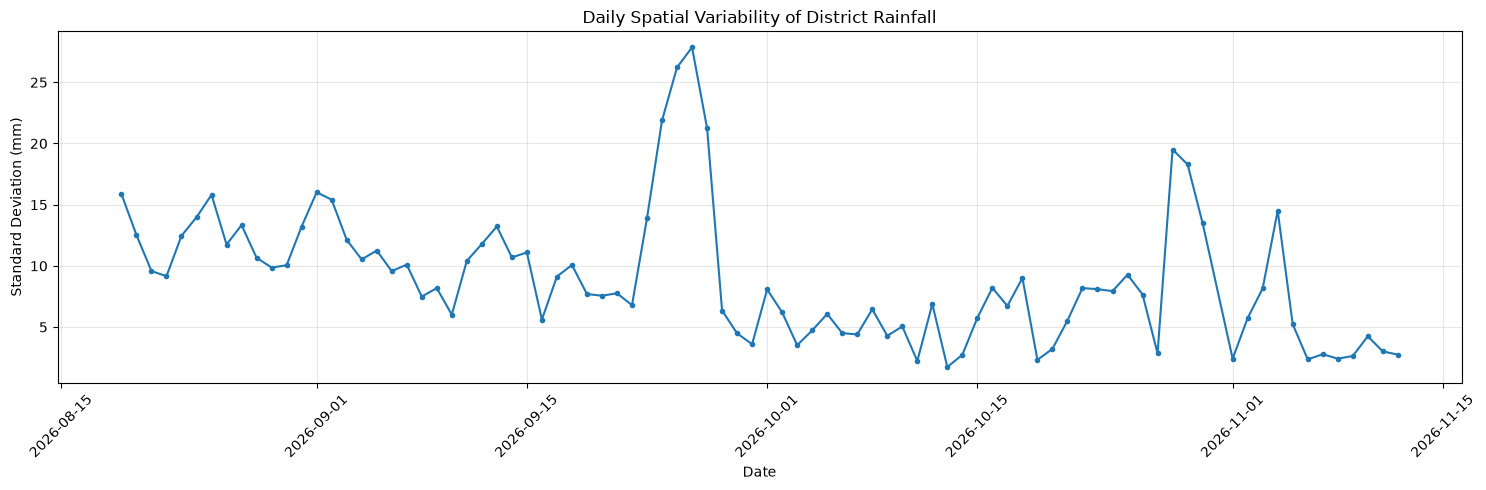

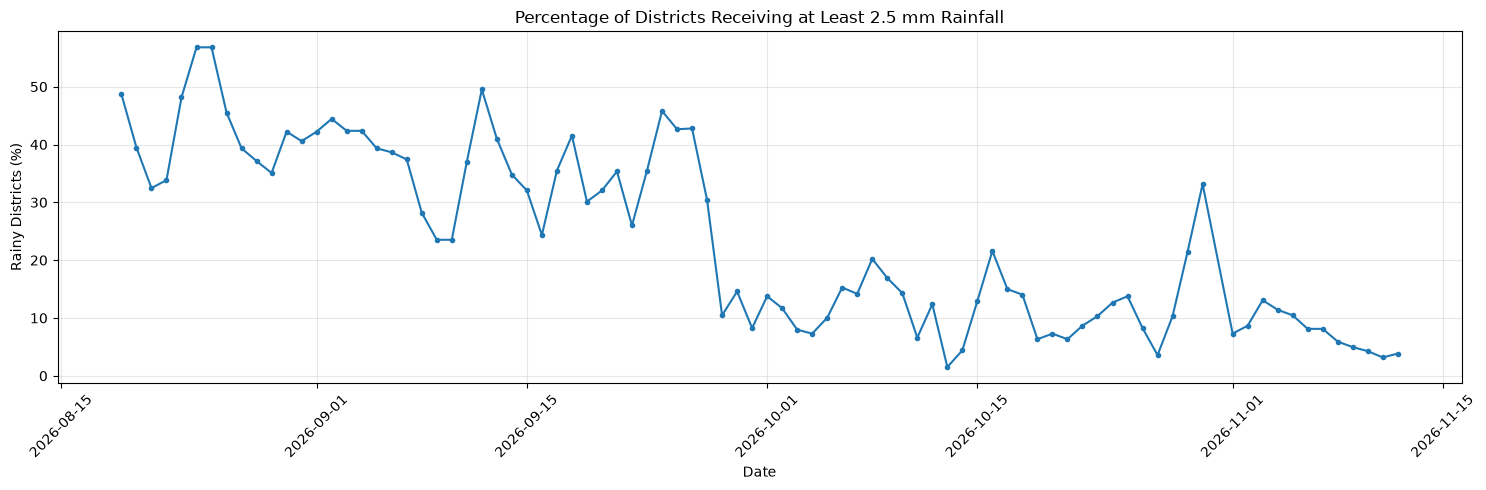

Daily rainfall visualizations completed!


In [26]:
# Daily district-wise temporal visualizations

import matplotlib.pyplot as plt
import seaborn as sns

daily_plot = daily_district_stats.sort_values("Date").copy()

# 1. Daily mean rainfall
plt.figure(figsize=(15, 5))
plt.plot(
    daily_plot["Date"],
    daily_plot["Mean_Rainfall"],
    marker="o",
    markersize=3
)
plt.title("Daily Mean Rainfall Across 727 Districts")
plt.xlabel("Date")
plt.ylabel("Mean Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Daily maximum rainfall
plt.figure(figsize=(15, 5))
plt.plot(
    daily_plot["Date"],
    daily_plot["Maximum_Rainfall"],
    marker="o",
    markersize=3
)
plt.title("Daily Maximum Rainfall Across Districts")
plt.xlabel("Date")
plt.ylabel("Maximum Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Daily rainfall standard deviation
plt.figure(figsize=(15, 5))
plt.plot(
    daily_plot["Date"],
    daily_plot["Rainfall_Std"],
    marker="o",
    markersize=3
)
plt.title("Daily Spatial Variability of District Rainfall")
plt.xlabel("Date")
plt.ylabel("Standard Deviation (mm)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Percentage of rainy districts
plt.figure(figsize=(15, 5))
plt.plot(
    daily_plot["Date"],
    daily_plot["Rainy_District_Percent"],
    marker="o",
    markersize=3
)
plt.title("Percentage of Districts Receiving at Least 2.5 mm Rainfall")
plt.xlabel("Date")
plt.ylabel("Rainy Districts (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Daily rainfall visualizations completed!")

## 25. Identification of Extreme District-level Rainfall Events

This section identifies the highest daily rainfall observations across districts during the available reporting period.

The analysis ranks district-level daily rainfall values and identifies the corresponding dates, districts, and states. These observations will subsequently undergo data-quality validation before being interpreted as extreme precipitation events.

In [27]:
# Identify the top 20 district-level daily rainfall observations

extreme_rainfall_events = (
    district_balanced[
        [
            "State",
            "District",
            "Date",
            "Daily Actual",
            "Daily Normal",
            "Daily Category"
        ]
    ]
    .sort_values("Daily Actual", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

extreme_rainfall_events.index += 1
extreme_rainfall_events.index.name = "Rank"

print("TOP 20 DISTRICT-LEVEL DAILY RAINFALL EVENTS")
print("=" * 80)

display(extreme_rainfall_events)

# Save results
extreme_rainfall_events.to_csv(
    os.path.join(
        table_dir,
        "top_20_extreme_district_rainfall_events.csv"
    )
)

print("\nTop 20 extreme rainfall observations saved successfully!")

TOP 20 DISTRICT-LEVEL DAILY RAINFALL EVENTS


,State,District,Date,Daily Actual,Daily Normal,Daily Category
Rank,,,,,,
1,ODISHA,NABARANGAPUR,2026-09-25,231.9,4.2,LE
2,ANDHRA PRADESH,VISHAKHAPATNAM,2026-10-28,226.0,5.3,LE
3,ANDHRA PRADESH,VIZIANAGARAM,2026-10-28,215.7,2.3,LE
4,ANDHRA PRADESH,ANAKAPALLI,2026-10-28,213.8,4.1,LE
5,ODISHA,KANDHAMAL,2026-10-29,213.1,1.0,LE
6,ANDHRA PRADESH,VISHAKHAPATNAM,2026-09-24,211.0,5.7,LE
7,ODISHA,KORAPUT,2026-09-25,203.7,4.7,LE
8,ANDHRA PRADESH,DR B R AMBEDKAR KONASEEMA,2026-11-04,203.2,9.8,LE
9,ODISHA,GANJAM,2026-10-29,196.0,1.7,LE



Top 20 extreme rainfall observations saved successfully!


## 22. Extreme Rainfall Event Concentration Analysis

This section examines the spatial and temporal concentration of extreme
district-level rainfall events.

We identify district-day observations with rainfall of at least 100 mm,
150 mm, and 200 mm. The analysis determines whether extreme rainfall
events are concentrated in particular states or dates.

These thresholds are used for exploratory analysis and do not represent
official IMD rainfall classifications.

In [29]:
from pathlib import Path

table_dir = Path(table_dir)
processed_dir = Path(processed_dir)

print("Table directory:", table_dir)
print("Processed directory:", processed_dir)

Table directory: d:\Downloads\BEST AI PROJECTS\RainfallRisk India\outputs_project2\tables
Processed directory: d:\Downloads\BEST AI PROJECTS\RainfallRisk India\outputs_project2\processed_data


In [30]:
# Extreme rainfall event concentration analysis

# Define analytical thresholds
thresholds = [100, 150, 200]

print("EXTREME RAINFALL EVENT COUNTS")
print("=" * 60)

for threshold in thresholds:
    count = (district_balanced["Daily Actual"] >= threshold).sum()
    print(f"District-day observations >= {threshold} mm: {count}")

# Create extreme event dataset (>= 100 mm)
extreme_events = district_balanced[
    district_balanced["Daily Actual"] >= 100
].copy()

# 1. Events by state
state_extreme_summary = (
    extreme_events.groupby("State")
    .agg(
        Extreme_Event_Count=("Daily Actual", "count"),
        Maximum_Rainfall=("Daily Actual", "max"),
        Mean_Extreme_Rainfall=("Daily Actual", "mean"),
        District_Count=("District", "nunique")
    )
    .sort_values("Extreme_Event_Count", ascending=False)
    .reset_index()
)

# 2. Events by date
date_extreme_summary = (
    extreme_events.groupby("Date")
    .agg(
        Extreme_Event_Count=("Daily Actual", "count"),
        Maximum_Rainfall=("Daily Actual", "max"),
        Affected_States=("State", "nunique"),
        Affected_Districts=("District", "nunique")
    )
    .sort_values("Extreme_Event_Count", ascending=False)
    .reset_index()
)

print("\nTOP STATES BY EXTREME RAINFALL EVENTS")
display(state_extreme_summary.head(15))

print("\nTOP DATES BY EXTREME RAINFALL EVENTS")
display(date_extreme_summary.head(15))

# Save results
state_extreme_summary.to_csv(
    table_dir / "extreme_rainfall_by_state.csv", index=False
)

date_extreme_summary.to_csv(
    table_dir / "extreme_rainfall_by_date.csv", index=False
)

extreme_events.to_csv(
    processed_dir / "district_extreme_rainfall_events.csv", index=False
)

print("\nExtreme rainfall concentration analysis completed!")

EXTREME RAINFALL EVENT COUNTS
District-day observations >= 100 mm: 99
District-day observations >= 150 mm: 19
District-day observations >= 200 mm: 8

TOP STATES BY EXTREME RAINFALL EVENTS


,State,Extreme_Event_Count,Maximum_Rainfall,Mean_Extreme_Rainfall,District_Count
0,UTTAR PRADESH,25,193.1,131.680000,21
1,ANDHRA PRADESH,20,226.0,149.030000,14
2,CHHATISGARH,17,191.7,125.629412,11
3,ODISHA,10,231.9,153.010000,7
4,MADHYA PRADESH,7,145.7,112.171429,5
5,JHARKHAND,3,129.3,117.433333,3
6,UTTARAKHAND,3,120.0,111.933333,2
7,PUDUCHERRY,2,140.6,126.900000,1
8,ASSAM,1,112.5,112.500000,1
9,ANDAMAN & NICOBAR,1,106.8,106.800000,1



TOP DATES BY EXTREME RAINFALL EVENTS


,Date,Extreme_Event_Count,Maximum_Rainfall,Affected_States,Affected_Districts
0,2026-09-26,22,193.1,3,22
1,2026-09-25,11,231.9,2,11
2,2026-09-27,11,137.6,2,11
3,2026-10-28,8,226.0,2,8
4,2026-09-24,6,211.0,2,6
5,2026-11-04,6,203.2,2,6
6,2026-08-19,4,122.5,4,4
7,2026-08-27,4,145.7,2,4
8,2026-09-02,3,129.3,3,3
9,2026-10-29,3,213.1,2,3



Extreme rainfall concentration analysis completed!


In [31]:
# Validate extreme rainfall observations

extreme_validation = extreme_events.copy()

# Sort by date and rainfall
extreme_validation = extreme_validation.sort_values(
    ["Date", "Daily Actual"],
    ascending=[True, False]
)

# Calculate actual-to-normal ratio where normal is positive
extreme_validation["Actual_Normal_Ratio"] = np.where(
    extreme_validation["Daily Normal"] > 0,
    extreme_validation["Daily Actual"] /
    extreme_validation["Daily Normal"],
    np.nan
)

# Summary by rainfall threshold
print("EXTREME OBSERVATION VALIDATION")
print("=" * 70)

print("\nRainfall distribution:")
display(
    extreme_validation["Daily Actual"].describe().round(2)
)

print("\nCategory distribution:")
display(
    extreme_validation["Daily Category"].value_counts(dropna=False)
)

print("\nTop 20 extreme observations with normal comparison:")
display(
    extreme_validation[
        [
            "State", "District", "Date",
            "Daily Actual", "Daily Normal",
            "Actual_Normal_Ratio", "Daily Category"
        ]
    ].head(20).round(2)
)

print("\nObservations with actual rainfall >= 200 mm:")
display(
    extreme_validation[
        extreme_validation["Daily Actual"] >= 200
    ][
        [
            "State", "District", "Date",
            "Daily Actual", "Daily Normal", "Daily Category"
        ]
    ]
)

# Save validation table
extreme_validation.to_csv(
    os.path.join(
        table_dir,
        "extreme_rainfall_validation.csv"
    ),
    index=False
)

print("\nExtreme rainfall validation completed!")

EXTREME OBSERVATION VALIDATION

Rainfall distribution:


count     99.00
mean     131.84
std       32.21
min      100.60
25%      110.25
50%      122.00
75%      137.20
max      231.90
Name: Daily Actual, dtype: float64


Category distribution:


Daily Category
LE    99
Name: count, dtype: int64


Top 20 extreme observations with normal comparison:


C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\914593767.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(20).round(2)


,State,District,Date,Daily Actual,Daily Normal,Actual_Normal_Ratio,Daily Category
10115,CHHATISGARH,BALRAMPUR,2026-08-19,122.5,11.8,10.38,LE
54655,UTTAR PRADESH,BALARAMPUR,2026-08-19,122.5,11.8,10.38,LE
41735,PUNJAB,GURDASPUR,2026-08-19,103.4,5.6,18.46,LE
21675,JHARKHAND,LATEHAR,2026-08-19,101.0,14.1,7.16,LE
29751,MADHYA PRADESH,REWA,2026-08-20,106.9,12.1,8.83,LE
40124,ODISHA,NABARANGAPUR,2026-08-23,107.9,10.0,10.79,LE
11905,CHHATISGARH,NARAYANPUR,2026-08-24,132.3,10.2,12.97,LE
60016,UTTAR PRADESH,VARANASI,2026-08-25,123.9,5.8,21.36,LE
37406,NCT of DELHI,CENTRAL DELHI,2026-08-25,102.2,2.4,42.58,LE
57977,UTTAR PRADESH,MAHOBA,2026-08-26,110.2,9.0,12.24,LE



Observations with actual rainfall >= 200 mm:


,State,District,Date,Daily Actual,Daily Normal,Daily Category
2161,ANDHRA PRADESH,VISHAKHAPATNAM,2026-09-24,211.0,5.7,LE
40157,ODISHA,NABARANGAPUR,2026-09-25,231.9,4.2,LE
39902,ODISHA,KORAPUT,2026-09-25,203.7,4.7,LE
2195,ANDHRA PRADESH,VISHAKHAPATNAM,2026-10-28,226.0,5.3,LE
2280,ANDHRA PRADESH,VIZIANAGARAM,2026-10-28,215.7,2.3,LE
325,ANDHRA PRADESH,ANAKAPALLI,2026-10-28,213.8,4.1,LE
39596,ODISHA,KANDHAMAL,2026-10-29,213.1,1.0,LE
756,ANDHRA PRADESH,DR B R AMBEDKAR KONASEEMA,2026-11-04,203.2,9.8,LE



Extreme rainfall validation completed!


In [32]:
# ============================================================
# GEOGRAPHICAL CONCENTRATION OF EXTREME RAINFALL
# ============================================================

import os
import pandas as pd

# Use the validated extreme observations
geo_extreme = extreme_events.copy()

# Ensure date is in datetime format
geo_extreme["Date"] = pd.to_datetime(geo_extreme["Date"])

# ------------------------------------------------------------
# 1. STATE-WISE EXTREME RAINFALL SUMMARY
# ------------------------------------------------------------

state_extreme_summary = (
    geo_extreme.groupby("State")
    .agg(
        Extreme_Observations=("Daily Actual", "count"),
        Unique_Districts=("District", "nunique"),
        Mean_Extreme_Rainfall=("Daily Actual", "mean"),
        Maximum_Rainfall=("Daily Actual", "max"),
        Minimum_Rainfall=("Daily Actual", "min")
    )
    .sort_values("Extreme_Observations", ascending=False)
    .reset_index()
)

state_extreme_summary["Percentage_of_Extremes"] = (
    state_extreme_summary["Extreme_Observations"]
    / len(geo_extreme) * 100
)

# ------------------------------------------------------------
# 2. DISTRICT-WISE EXTREME RAINFALL SUMMARY
# ------------------------------------------------------------

district_extreme_summary = (
    geo_extreme.groupby(["State", "District"])
    .agg(
        Extreme_Observations=("Daily Actual", "count"),
        Mean_Extreme_Rainfall=("Daily Actual", "mean"),
        Maximum_Rainfall=("Daily Actual", "max"),
        First_Extreme_Date=("Date", "min"),
        Last_Extreme_Date=("Date", "max")
    )
    .sort_values(
        ["Extreme_Observations", "Maximum_Rainfall"],
        ascending=False
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. PRINT RESULTS
# ------------------------------------------------------------

print("=" * 85)
print("STATE-WISE GEOGRAPHICAL CONCENTRATION")
print("=" * 85)

print(state_extreme_summary.round(2).to_string(index=False))

print("\n" + "=" * 85)
print("TOP 20 DISTRICTS WITH EXTREME RAINFALL")
print("=" * 85)

print(district_extreme_summary.head(20).round(2).to_string(index=False))

# ------------------------------------------------------------
# 4. SAVE RESULTS
# ------------------------------------------------------------

state_extreme_summary.to_csv(
    os.path.join(table_dir, "extreme_rainfall_geographical_state_summary.csv"),
    index=False
)

district_extreme_summary.to_csv(
    os.path.join(table_dir, "extreme_rainfall_geographical_district_summary.csv"),
    index=False
)

print("\nGeographical concentration analysis completed!")
print("State and district summaries saved successfully.")

STATE-WISE GEOGRAPHICAL CONCENTRATION
               State  Extreme_Observations  Unique_Districts  Mean_Extreme_Rainfall  Maximum_Rainfall  Minimum_Rainfall  Percentage_of_Extremes
       UTTAR PRADESH                    25                21                 131.68             193.1             103.0                   25.25
      ANDHRA PRADESH                    20                14                 149.03             226.0             100.6                   20.20
         CHHATISGARH                    17                11                 125.63             191.7             102.2                   17.17
              ODISHA                    10                 7                 153.01             231.9             101.4                   10.10
      MADHYA PRADESH                     7                 5                 112.17             145.7             101.3                    7.07
           JHARKHAND                     3                 3                 117.43             12

C:\Users\Jay\AppData\Local\Temp\ipykernel_18576\320953824.py:70: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(district_extreme_summary.head(20).round(2).to_string(index=False))


## Geographical Concentration of Extreme Rainfall

This analysis examines the geographical distribution of extreme rainfall observations (>=100 mm/day) across Indian states and districts.

The objectives are:
1. Identify states with the highest number of extreme rainfall observations.
2. Identify districts with repeated extreme rainfall observations.
3. Compare the maximum and average rainfall intensity across states.
4. Examine whether extreme rainfall observations are concentrated in a small number of geographical regions.

Note: These are district-day observations, not necessarily independent meteorological events.

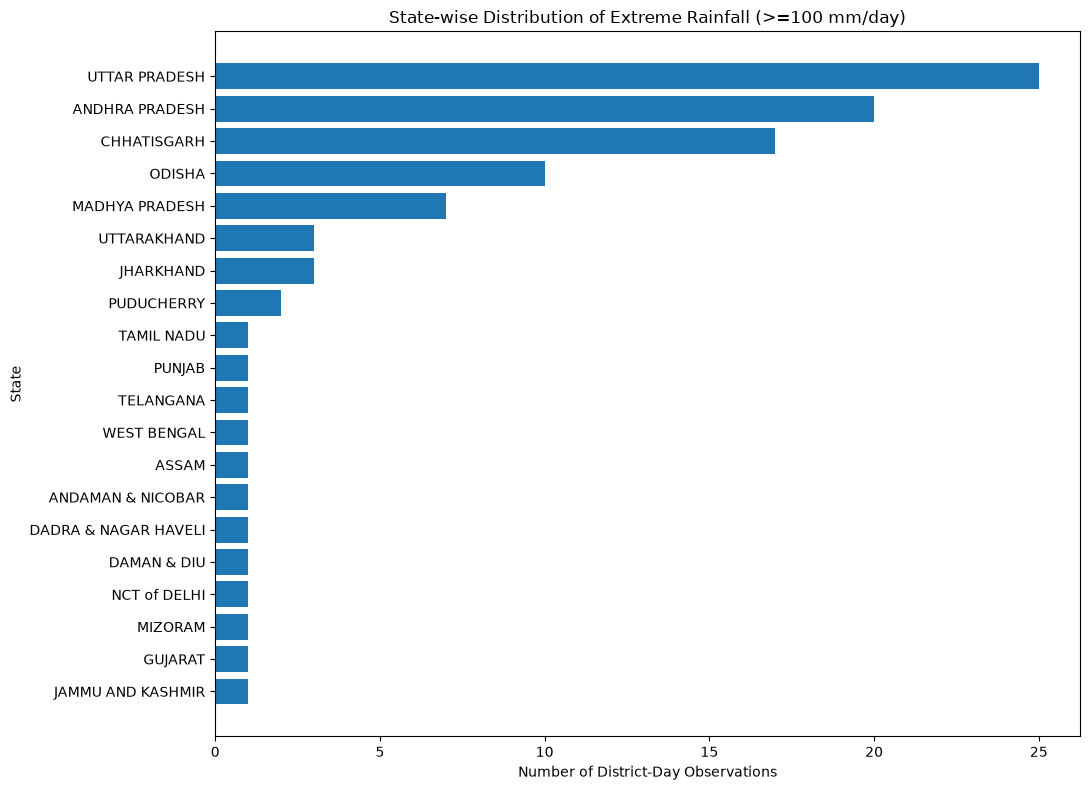

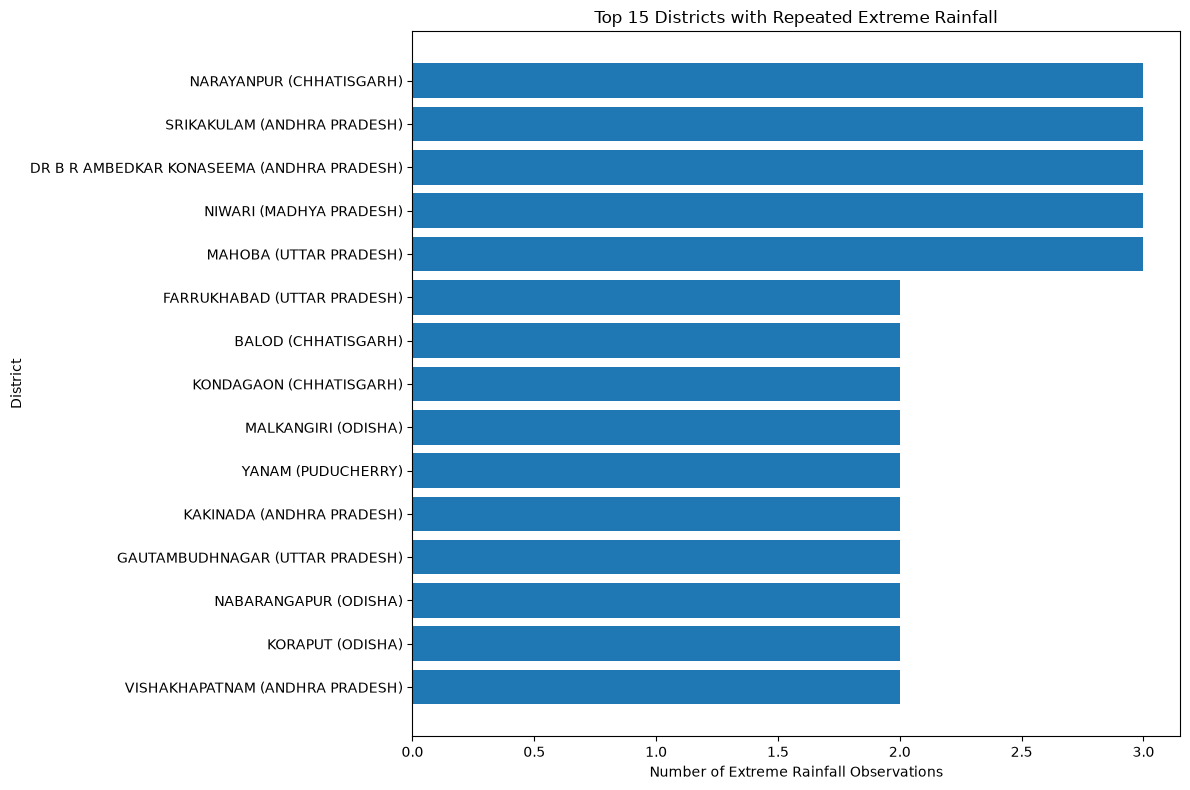

Both geographical concentration charts saved successfully!


In [34]:
import matplotlib.pyplot as plt

# 1. State-wise extreme observations
state_plot = state_extreme_summary.sort_values(
    "Extreme_Observations", ascending=True
)

plt.figure(figsize=(11, 8))
plt.barh(
    state_plot["State"],
    state_plot["Extreme_Observations"]
)
plt.xlabel("Number of District-Day Observations")
plt.ylabel("State")
plt.title("State-wise Distribution of Extreme Rainfall (>=100 mm/day)")
plt.tight_layout()
plt.savefig(
    os.path.join(figure_dir, "statewise_extreme_rainfall.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Top 15 districts by extreme observations
district_plot = district_extreme_summary.head(15).copy()
district_plot["District_Label"] = (
    district_plot["District"] + " (" + district_plot["State"] + ")"
)

district_plot = district_plot.sort_values(
    "Extreme_Observations", ascending=True
)

plt.figure(figsize=(12, 8))
plt.barh(
    district_plot["District_Label"],
    district_plot["Extreme_Observations"]
)
plt.xlabel("Number of Extreme Rainfall Observations")
plt.ylabel("District")
plt.title("Top 15 Districts with Repeated Extreme Rainfall")
plt.tight_layout()
plt.savefig(
    os.path.join(figure_dir, "top15_district_extreme_rainfall.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Both geographical concentration charts saved successfully!")

## Statistical Hypothesis Testing: Assumption Checking

### Objective
Before conducting statistical hypothesis tests, we examine whether the data satisfies the assumptions required for parametric statistical methods.

### Unit of Analysis
Each district is represented by its average daily rainfall over the 85-day observation period.

The incomplete district (Nagapattinam) is excluded because it does not have complete observations for the study period.

### Assumptions to Examine

1. Independence of observations: Districts are treated as the initial comparison units, while recognizing possible spatial dependence.
2. Normality: Examine the distribution of residuals from the state-wise comparison model.
3. Homogeneity of variance: Examine whether rainfall variability is comparable across states using Levene's test.

The results will guide the choice between one-way ANOVA and non-parametric alternatives.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Create one average rainfall value per district
district_state_test = (
    district_balanced
    .groupby(["State", "District"])
    .agg(
        Mean_Daily_Rainfall=("Daily Actual", "mean"),
        Observation_Count=("Daily Actual", "count")
    )
    .reset_index()
)

# Keep only districts with all 85 observations
district_state_test = district_state_test[
    district_state_test["Observation_Count"] == 85
].copy()

# Basic verification
print("=" * 70)
print("DISTRICT-LEVEL DATA FOR STATISTICAL TESTING")
print("=" * 70)

print("Total district observations:", len(district_state_test))
print("Number of states:", district_state_test["State"].nunique())
print("Minimum observations per district:",
      district_state_test["Observation_Count"].min())
print("Maximum observations per district:",
      district_state_test["Observation_Count"].max())

print("\nDistricts per state:")
print(
    district_state_test.groupby("State")["District"]
    .count()
    .sort_values(ascending=False)
    .to_string()
)

print("\nOverall district mean rainfall summary:")
print(district_state_test["Mean_Daily_Rainfall"].describe())

DISTRICT-LEVEL DATA FOR STATISTICAL TESTING
Total district observations: 727
Number of states: 39
Minimum observations per district: 85
Maximum observations per district: 85

Districts per state:
State
UTTAR PRADESH           75
MADHYA PRADESH          52
BIHAR                   38
MAHARASHTRA             36
TAMIL NADU              36
ASSAM                   33
TELANGANA               33
GUJARAT                 33
RAJASTHAN               33
CHHATISGARH             31
KARNATAKA               31
ODISHA                  30
ANDHRA PRADESH          26
JHARKHAND               24
PUNJAB                  22
HARYANA                 22
JAMMU AND KASHMIR       20
WEST BENGAL             20
ARUNACHAL PRADESH       16
KERALA                  14
UTTARAKHAND             13
HIMACHAL PRADESH        12
MEGHALAYA               11
NAGALAND                11
NCT of DELHI            10
MANIPUR                  9
MIZORAM                  8
TRIPURA                  8
PUDUCHERRY               4
ANDAMAN & NICOB

In [36]:
# Standardize inconsistent state names
state_corrections = {
    "CHHATISGARH": "CHHATTISGARH",
    "CHHATTISGARH": "CHHATTISGARH",
    "TAMILNADU": "TAMIL NADU",
    "TAMIL NADU": "TAMIL NADU"
}

district_state_test["State"] = (
    district_state_test["State"]
    .str.strip()
    .replace(state_corrections)
)

# Recalculate state-wise district counts
state_group_sizes = (
    district_state_test.groupby("State")
    .agg(
        District_Count=("District", "count"),
        Mean_Rainfall=("Mean_Daily_Rainfall", "mean"),
        Std_Rainfall=("Mean_Daily_Rainfall", "std")
    )
    .sort_values("District_Count", ascending=False)
    .reset_index()
)

print("=" * 75)
print("STANDARDIZED STATE GROUP SUMMARY")
print("=" * 75)

print("Total districts:", len(district_state_test))
print("Unique states:", district_state_test["State"].nunique())

print("\nState-wise group sizes:")
print(state_group_sizes.to_string(index=False))

print("\nStates with fewer than 5 districts:")
print(
    state_group_sizes[
        state_group_sizes["District_Count"] < 5
    ].to_string(index=False)
)

STANDARDIZED STATE GROUP SUMMARY
Total districts: 727
Unique states: 37

State-wise group sizes:
               State  District_Count  Mean_Rainfall  Std_Rainfall
       UTTAR PRADESH              75       4.613114      2.252452
      MADHYA PRADESH              52       4.009548      2.180265
               BIHAR              38       3.746440      0.731144
          TAMIL NADU              37       4.440890      1.037952
         MAHARASHTRA              36       1.773007      1.288969
           TELANGANA              33       2.215330      0.850431
           RAJASTHAN              33       1.478396      1.138255
             GUJARAT              33       1.589055      0.485011
               ASSAM              33       3.736827      1.194037
        CHHATTISGARH              32       5.651250      1.909080
           KARNATAKA              31       2.776812      1.982494
              ODISHA              30       6.971490      2.138324
      ANDHRA PRADESH              26       5.

## Normality and Homogeneity of Variance Assessment

Before performing one-way ANOVA, its assumptions are examined.

1. Normality of model residuals is assessed using the Shapiro-Wilk test and a Q-Q plot.
2. Homogeneity of variance is assessed using Levene's test.
3. The analysis is restricted to states having at least five districts for the primary comparison.

The diagnostic results guide the selection of classical ANOVA, Welch's ANOVA, or Kruskal-Wallis testing.

Note: Statistical tests of normality are sensitive to sample size. Graphical diagnostics and practical distributional characteristics are also considered.

Eligible states: 28
District observations: 709

NORMALITY TEST: SHAPIRO-WILK
W statistic: 0.9783
p-value: 9.388975142827527e-09

HOMOGENEITY OF VARIANCE: LEVENE TEST
Statistic: 6.83868
p-value: 5.268343367859777e-22


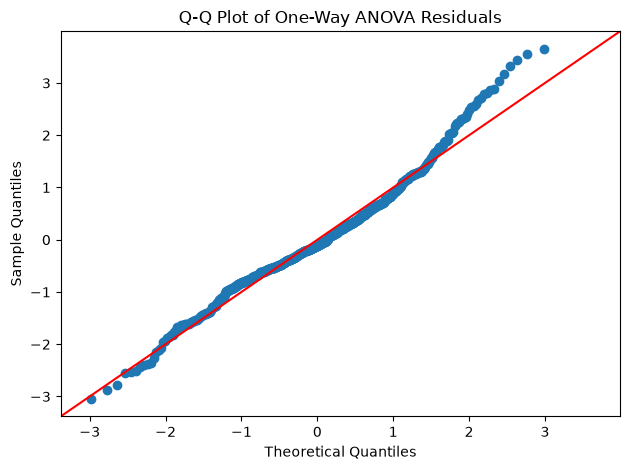

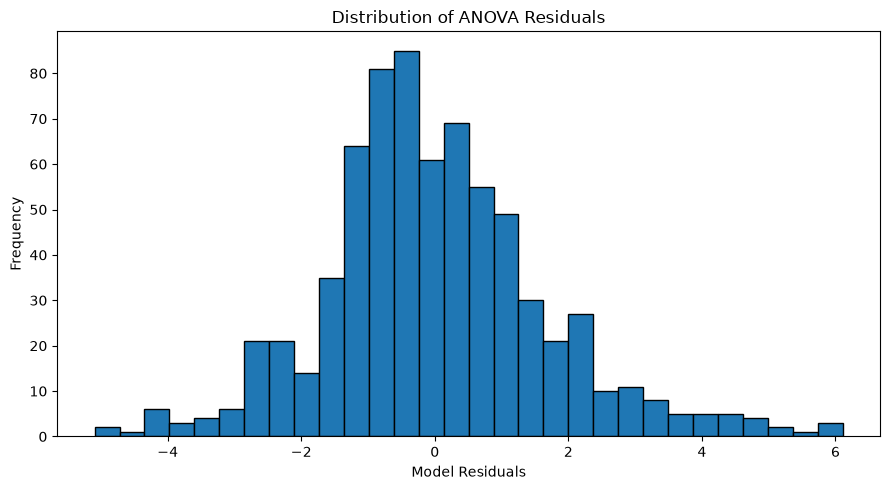

In [37]:
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Primary comparison: states with at least 5 districts
eligible_states = state_group_sizes.loc[
    state_group_sizes["District_Count"] >= 5, "State"
]

test_data = district_state_test[
    district_state_test["State"].isin(eligible_states)
].copy()

print("Eligible states:", test_data["State"].nunique())
print("District observations:", len(test_data))

# Fit one-way ANOVA model for residual diagnostics
model = smf.ols(
    "Mean_Daily_Rainfall ~ C(State)",
    data=test_data
).fit()

residuals = model.resid

# Shapiro-Wilk normality test
shapiro_stat, shapiro_p = stats.shapiro(residuals)

print("\nNORMALITY TEST: SHAPIRO-WILK")
print("W statistic:", round(shapiro_stat, 5))
print("p-value:", shapiro_p)

# Levene's test for equal variances
groups = [
    group["Mean_Daily_Rainfall"].values
    for _, group in test_data.groupby("State")
]

levene_stat, levene_p = stats.levene(*groups, center="median")

print("\nHOMOGENEITY OF VARIANCE: LEVENE TEST")
print("Statistic:", round(levene_stat, 5))
print("p-value:", levene_p)

# Residual Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of One-Way ANOVA Residuals")
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.xlabel("Model Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of ANOVA Residuals")
plt.tight_layout()
plt.show()

## Welch's ANOVA and Kruskal-Wallis Hypothesis Tests

### Test 1: Welch's ANOVA

H0: The mean district-level rainfall is equal across all selected states.

H1: At least one state's mean district-level rainfall differs.

Welch's ANOVA is used because the homogeneity of variance assumption is violated.

### Test 2: Kruskal-Wallis H-test

H0: The rainfall distributions are identical across the selected states.

H1: At least one state's rainfall distribution differs.

This provides a non-parametric comparison alongside Welch's ANOVA.

Significance level: 0.05.

In [38]:
from statsmodels.stats.oneway import anova_oneway
from scipy import stats
import numpy as np

# Prepare groups using the eligible states
groups = [
    group["Mean_Daily_Rainfall"].to_numpy()
    for _, group in test_data.groupby("State")
]

# --------------------------------------------------
# 1. WELCH'S ANOVA
# --------------------------------------------------

welch_result = anova_oneway(
    data=groups,
    use_var="unequal",
    welch_correction=True
)

print("=" * 70)
print("WELCH'S ANOVA")
print("=" * 70)

print("F-statistic:", round(welch_result.statistic, 5))
print("Numerator degrees of freedom:", round(welch_result.df_num, 3))
print("Denominator degrees of freedom:", round(welch_result.df_denom, 3))
print("p-value:", welch_result.pvalue)

if welch_result.pvalue < 0.05:
    print("Decision: Reject H0")
    print("Conclusion: Evidence of differences in mean rainfall across states.")
else:
    print("Decision: Fail to reject H0")
    print("Conclusion: Insufficient evidence of differences in mean rainfall.")


# --------------------------------------------------
# 2. KRUSKAL-WALLIS H-TEST
# --------------------------------------------------

kruskal_result = stats.kruskal(*groups)

print("\n" + "=" * 70)
print("KRUSKAL-WALLIS H-TEST")
print("=" * 70)

print("H-statistic:", round(kruskal_result.statistic, 5))
print("Degrees of freedom:", len(groups) - 1)
print("p-value:", kruskal_result.pvalue)

if kruskal_result.pvalue < 0.05:
    print("Decision: Reject H0")
    print("Conclusion: Evidence that rainfall distributions differ across states.")
else:
    print("Decision: Fail to reject H0")
    print("Conclusion: Insufficient evidence of distributional differences.")


# --------------------------------------------------
# 3. KRUSKAL-WALLIS EFFECT SIZE
# --------------------------------------------------

n = len(test_data)
k = len(groups)

epsilon_squared = (
    kruskal_result.statistic - k + 1
) / (n - k)

epsilon_squared = max(0, epsilon_squared)

print("\n" + "=" * 70)
print("KRUSKAL-WALLIS EFFECT SIZE")
print("=" * 70)

print("Epsilon-squared:", round(epsilon_squared, 5))

WELCH'S ANOVA
F-statistic: 44.12235
Numerator degrees of freedom: 27.0
Denominator degrees of freedom: 164.687
p-value: 1.117090183301085e-61
Decision: Reject H0
Conclusion: Evidence of differences in mean rainfall across states.

KRUSKAL-WALLIS H-TEST
H-statistic: 379.41923
Degrees of freedom: 27
p-value: 7.6309038743075e-64
Decision: Reject H0
Conclusion: Evidence that rainfall distributions differ across states.

KRUSKAL-WALLIS EFFECT SIZE
Epsilon-squared: 0.5175


## Post-Hoc Pairwise State Comparisons

Following significant results from Welch's ANOVA, pairwise comparisons are conducted to identify which states differ in mean district-level rainfall.

Pairwise Welch's t-tests are used because state groups have unequal variances and sample sizes.

The Holm correction is applied to control the family-wise error rate across all pairwise comparisons.

For each comparison, the following are reported:

1. State pair
2. Mean rainfall difference
3. Welch's t-statistic
4. Raw p-value
5. Holm-adjusted p-value
6. 95% confidence interval

Significance level: 0.05.

In [39]:
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests

# --------------------------------------------------
# PAIRWISE WELCH T-TESTS
# --------------------------------------------------

pairwise_results = []

state_groups = {
    state: group["Mean_Daily_Rainfall"].to_numpy()
    for state, group in test_data.groupby("State")
}

for state_a, state_b in combinations(state_groups.keys(), 2):

    a = state_groups[state_a]
    b = state_groups[state_b]

    # Welch's independent-samples t-test
    result = stats.ttest_ind(a, b, equal_var=False)

    mean_difference = np.mean(a) - np.mean(b)

    # Welch-Satterthwaite degrees of freedom
    va = np.var(a, ddof=1)
    vb = np.var(b, ddof=1)
    na, nb = len(a), len(b)

    se = np.sqrt(va / na + vb / nb)

    df = (va / na + vb / nb) ** 2 / (
        (va / na) ** 2 / (na - 1)
        + (vb / nb) ** 2 / (nb - 1)
    )

    critical_value = stats.t.ppf(0.975, df)

    ci_lower = mean_difference - critical_value * se
    ci_upper = mean_difference + critical_value * se

    pairwise_results.append({
        "State_A": state_a,
        "State_B": state_b,
        "Mean_Difference": mean_difference,
        "T_Statistic": result.statistic,
        "Raw_P_Value": result.pvalue,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper
    })

pairwise_df = pd.DataFrame(pairwise_results)

# --------------------------------------------------
# HOLM MULTIPLE-TESTING CORRECTION
# --------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    pairwise_df["Raw_P_Value"],
    alpha=0.05,
    method="holm"
)

pairwise_df["Holm_Adjusted_P"] = adjusted_p
pairwise_df["Significant"] = reject

pairwise_df = pairwise_df.sort_values(
    "Holm_Adjusted_P"
).reset_index(drop=True)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print("=" * 80)
print("PAIRWISE WELCH T-TESTS WITH HOLM CORRECTION")
print("=" * 80)

print("Total comparisons:", len(pairwise_df))
print("Significant comparisons:", pairwise_df["Significant"].sum())
print("Non-significant comparisons:", (~pairwise_df["Significant"]).sum())

print("\nTOP 20 SIGNIFICANT STATE DIFFERENCES:")

print(
    pairwise_df[pairwise_df["Significant"]]
    .head(20)
    .round(6)
    .to_string(index=False)
)

# Save complete results
pairwise_df.to_csv(
    os.path.join(
        table_dir,
        "statewise_pairwise_welch_holm_results.csv"
    ),
    index=False
)

print("\nComplete pairwise results saved successfully!")

PAIRWISE WELCH T-TESTS WITH HOLM CORRECTION
Total comparisons: 378
Significant comparisons: 159
Non-significant comparisons: 219

TOP 20 SIGNIFICANT STATE DIFFERENCES:
     State_A       State_B  Mean_Difference  T_Statistic  Raw_P_Value  CI_Lower  CI_Upper  Holm_Adjusted_P  Significant
       BIHAR       GUJARAT         2.157384    14.818362          0.0  1.866604  2.448165              0.0         True
     GUJARAT    TAMIL NADU        -2.851835   -14.979443          0.0 -3.233822 -2.469848              0.0         True
     GUJARAT UTTAR PRADESH        -3.024058   -11.058858          0.0 -3.567472 -2.480645              0.0         True
      KERALA     RAJASTHAN         4.954629    16.287827          0.0  4.335111  5.574148              0.0         True
   RAJASTHAN    TAMIL NADU        -2.962495   -11.329138          0.0 -3.484704 -2.440285              0.0         True
      KERALA   MAHARASHTRA         4.660019    14.778995          0.0  4.020163  5.299874              0.0      

## Dunn's Post-Hoc Test with Holm Correction

Following the significant Kruskal-Wallis result, Dunn's post-hoc test is conducted to identify differences between individual state groups.

The test compares average ranks between state groups.

Holm correction is applied to adjust for multiple pairwise comparisons.

Significance level: 0.05.

In [40]:
from scipy.stats import rankdata, norm
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

# --------------------------------------------------
# DUNN'S POST-HOC TEST
# --------------------------------------------------

# Rank all district-level rainfall observations together
values = test_data["Mean_Daily_Rainfall"].to_numpy()
ranks = rankdata(values)

rank_data = test_data[["State"]].copy()
rank_data["Rank"] = ranks

N = len(rank_data)

# Tie correction
_, tie_counts = np.unique(values, return_counts=True)

tie_sum = np.sum(tie_counts**3 - tie_counts)

tie_correction = 1 - tie_sum / (N**3 - N)

# State-wise rank summaries
rank_summary = (
    rank_data.groupby("State")["Rank"]
    .agg(["mean", "count"])
)

dunn_results = []

# Pairwise comparisons
for state_a, state_b in combinations(rank_summary.index, 2):

    mean_rank_a = rank_summary.loc[state_a, "mean"]
    mean_rank_b = rank_summary.loc[state_b, "mean"]

    n_a = rank_summary.loc[state_a, "count"]
    n_b = rank_summary.loc[state_b, "count"]

    se = np.sqrt(
        (N * (N + 1) / 12)
        * tie_correction
        * (1 / n_a + 1 / n_b)
    )

    z_stat = (mean_rank_a - mean_rank_b) / se

    p_value = 2 * norm.sf(abs(z_stat))

    dunn_results.append({
        "State_A": state_a,
        "State_B": state_b,
        "Mean_Rank_Difference": mean_rank_a - mean_rank_b,
        "Z_Statistic": z_stat,
        "Raw_P_Value": p_value
    })

dunn_df = pd.DataFrame(dunn_results)

# Holm correction
reject, adjusted_p, _, _ = multipletests(
    dunn_df["Raw_P_Value"],
    alpha=0.05,
    method="holm"
)

dunn_df["Holm_Adjusted_P"] = adjusted_p
dunn_df["Significant"] = reject

dunn_df = dunn_df.sort_values(
    "Holm_Adjusted_P"
).reset_index(drop=True)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print("=" * 80)
print("DUNN'S POST-HOC TEST WITH HOLM CORRECTION")
print("=" * 80)

print("Total comparisons:", len(dunn_df))
print("Significant comparisons:", dunn_df["Significant"].sum())
print("Non-significant comparisons:", (~dunn_df["Significant"]).sum())

print("\nTOP 20 SIGNIFICANT COMPARISONS:")

print(
    dunn_df[dunn_df["Significant"]]
    .head(20)
    .round(6)
    .to_string(index=False)
)

# Save results
dunn_df.to_csv(
    os.path.join(table_dir, "statewise_dunn_holm_results.csv"),
    index=False
)

print("\nDunn's post-hoc results saved successfully!")

DUNN'S POST-HOC TEST WITH HOLM CORRECTION
Total comparisons: 378
Significant comparisons: 122
Non-significant comparisons: 256

TOP 20 SIGNIFICANT COMPARISONS:
          State_A       State_B  Mean_Rank_Difference  Z_Statistic  Raw_P_Value  Holm_Adjusted_P  Significant
           ODISHA     RAJASTHAN            459.481818     8.893120          0.0              0.0         True
           ODISHA        PUNJAB            503.800000     8.763285          0.0              0.0         True
          GUJARAT        ODISHA           -447.118182    -8.653826          0.0              0.0         True
      MAHARASHTRA        ODISHA           -432.577778    -8.543633          0.0              0.0         True
          HARYANA        ODISHA           -458.436364    -7.974213          0.0              0.0         True
     CHHATTISGARH     RAJASTHAN            384.166193     7.560193          0.0              0.0         True
     CHHATTISGARH        PUNJAB            428.484375     7.553756    

### Post-Hoc Analysis of State-wise Rainfall Differences

Following significant omnibus test results, pairwise comparisons were conducted using Welch's t-tests and Dunn's test, with Holm correction for multiple comparisons.

The pairwise Welch analysis identified 159 statistically significant comparisons out of 378, whereas Dunn's test identified 122 significant comparisons.

The results indicate substantial differences in district-level rainfall across several state pairs. Odisha, Chhattisgarh and Kerala appeared frequently in significant comparisons involving higher rainfall ranks.

The difference in significant comparison counts reflects the different statistical properties of mean-based and rank-based methods. These findings support the presence of geographical heterogeneity in rainfall during the 85-day observation period.

## Paired Hypothesis Testing: Actual vs Normal Rainfall

This analysis compares observed rainfall with corresponding normal rainfall.

For each district, the mean actual rainfall and mean normal rainfall are calculated over the same 85 reporting dates.

The Wilcoxon signed-rank test is used to examine whether the paired differences are systematically different from zero.

Significance level: 0.05.

In [41]:
# Calculate paired district-level averages
district_actual_normal = (
    district_balanced.groupby(["State", "District"])
    .agg(
        Mean_Actual=("Daily Actual", "mean"),
        Mean_Normal=("Daily Normal", "mean")
    )
    .reset_index()
)

district_actual_normal["Rainfall_Difference"] = (
    district_actual_normal["Mean_Actual"]
    - district_actual_normal["Mean_Normal"]
)

# Remove any invalid values
paired_data = district_actual_normal.dropna(
    subset=["Mean_Actual", "Mean_Normal"]
).copy()

# Wilcoxon signed-rank test
wilcoxon_result = stats.wilcoxon(
    paired_data["Mean_Actual"],
    paired_data["Mean_Normal"],
    alternative="two-sided"
)

print("=" * 75)
print("WILCOXON SIGNED-RANK TEST: ACTUAL VS NORMAL RAINFALL")
print("=" * 75)

print("Number of paired districts:", len(paired_data))
print("Mean actual rainfall:",
      round(paired_data["Mean_Actual"].mean(), 4))
print("Mean normal rainfall:",
      round(paired_data["Mean_Normal"].mean(), 4))
print("Mean paired difference:",
      round(paired_data["Rainfall_Difference"].mean(), 4))
print("Median paired difference:",
      round(paired_data["Rainfall_Difference"].median(), 4))

print("\nWilcoxon statistic:", wilcoxon_result.statistic)
print("p-value:", wilcoxon_result.pvalue)

if wilcoxon_result.pvalue < 0.05:
    print("\nDecision: Reject H0")
    print("Conclusion: Evidence of a systematic difference between actual and normal rainfall.")
else:
    print("\nDecision: Fail to reject H0")
    print("Conclusion: Insufficient evidence of a systematic difference.")

# Save paired results
paired_data.to_csv(
    os.path.join(table_dir, "district_actual_vs_normal_paired_analysis.csv"),
    index=False
)

print("\nPaired rainfall analysis saved successfully!")

WILCOXON SIGNED-RANK TEST: ACTUAL VS NORMAL RAINFALL
Number of paired districts: 727
Mean actual rainfall: 3.8058
Mean normal rainfall: 4.6056
Mean paired difference: -0.7998
Median paired difference: -0.7894

Wilcoxon statistic: 80015.5
p-value: 2.6380198400866936e-20

Decision: Reject H0
Conclusion: Evidence of a systematic difference between actual and normal rainfall.

Paired rainfall analysis saved successfully!


### Paired Comparison of Actual and Normal Rainfall

A Wilcoxon signed-rank test was conducted using 727 paired district-level observations to examine differences between mean actual and mean normal rainfall over the study period.

The mean actual rainfall was 3.8058 mm/day, compared with a mean normal rainfall of 4.6056 mm/day. The mean paired difference was -0.7998 mm/day, while the median paired difference was -0.7894 mm/day.

The test indicated a statistically significant difference (W = 80,015.5, p = 2.638 × 10⁻²⁰). The null hypothesis was rejected, providing evidence that actual rainfall was systematically lower than normal rainfall across the analysed districts during the observation window.

These results describe the selected reporting period and should not be interpreted as evidence of a long-term rainfall deficit or climatic trend.

## State-wise Paired Comparison of Actual and Normal Rainfall

### Objective
Determine whether actual rainfall differed significantly from normal rainfall within individual states during the observation period.

### Methodology
1. Calculate the difference between mean actual and mean normal rainfall for each district.
2. Group district-level differences by state.
3. Apply the one-sample Wilcoxon signed-rank test against zero within each state.
4. Apply Holm correction to account for multiple hypothesis tests.

### Hypotheses

H0: The median district-level paired rainfall difference is zero for a given state.

H1: The median district-level paired rainfall difference is not zero for a given state.

Significance level: 0.05.

A negative difference indicates below-normal rainfall, while a positive difference indicates above-normal rainfall.

In [42]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

# Use the 28 states selected for the primary analysis
state_paired_data = paired_data[
    paired_data["State"].isin(eligible_states)
].copy()

state_test_results = []

# Perform one-sample Wilcoxon test for each state
for state, group in state_paired_data.groupby("State"):

    differences = group["Rainfall_Difference"].dropna().to_numpy()

    # Descriptive statistics
    mean_diff = np.mean(differences)
    median_diff = np.median(differences)

    # Test whether paired differences are centred at zero
    if np.allclose(differences, 0):
        statistic = np.nan
        p_value = 1.0
    else:
        result = stats.wilcoxon(
            differences,
            alternative="two-sided",
            zero_method="wilcox",
            method="approx"
        )

        statistic = result.statistic
        p_value = result.pvalue

    state_test_results.append({
        "State": state,
        "District_Count": len(differences),
        "Mean_Difference": mean_diff,
        "Median_Difference": median_diff,
        "Wilcoxon_Statistic": statistic,
        "Raw_P_Value": p_value
    })

state_wilcoxon_df = pd.DataFrame(state_test_results)

# Holm multiple-testing correction
reject, adjusted_p, _, _ = multipletests(
    state_wilcoxon_df["Raw_P_Value"],
    alpha=0.05,
    method="holm"
)

state_wilcoxon_df["Holm_Adjusted_P"] = adjusted_p
state_wilcoxon_df["Significant"] = reject

# Classify rainfall direction
state_wilcoxon_df["Rainfall_Status"] = np.select(
    [
        state_wilcoxon_df["Median_Difference"] < 0,
        state_wilcoxon_df["Median_Difference"] > 0
    ],
    [
        "Below Normal",
        "Above Normal"
    ],
    default="At Normal"
)

state_wilcoxon_df = state_wilcoxon_df.sort_values(
    "Holm_Adjusted_P"
).reset_index(drop=True)

# Display results
print("=" * 95)
print("STATE-WISE WILCOXON SIGNED-RANK TEST WITH HOLM CORRECTION")
print("=" * 95)

print("States tested:", len(state_wilcoxon_df))
print("Significant states:",
      state_wilcoxon_df["Significant"].sum())

print("\nCOMPLETE STATE-WISE RESULTS:\n")

print(
    state_wilcoxon_df.round(6).to_string(index=False)
)

print("\nSIGNIFICANT STATES BY RAINFALL STATUS:")

print(
    state_wilcoxon_df[
        state_wilcoxon_df["Significant"]
    ]["Rainfall_Status"].value_counts()
)

# Save results
state_wilcoxon_df.to_csv(
    os.path.join(
        table_dir,
        "statewise_actual_vs_normal_wilcoxon_holm.csv"
    ),
    index=False
)

print("\nState-wise hypothesis testing completed!")
print("Results saved successfully.")

STATE-WISE WILCOXON SIGNED-RANK TEST WITH HOLM CORRECTION
States tested: 28
Significant states: 10

COMPLETE STATE-WISE RESULTS:

            State  District_Count  Mean_Difference  Median_Difference  Wilcoxon_Statistic  Raw_P_Value  Holm_Adjusted_P  Significant Rainfall_Status
      MAHARASHTRA              36        -2.893725          -2.732353                 0.0     0.000000         0.000005         True    Below Normal
    UTTAR PRADESH              75         1.476784           1.323529               452.0     0.000000         0.000007         True    Above Normal
          GUJARAT              33        -1.521640          -1.305882                 0.0     0.000001         0.000014         True    Below Normal
            ASSAM              33        -2.885989          -2.669412                 0.0     0.000001         0.000014         True    Below Normal
        TELANGANA              33        -1.913583          -2.043529                 0.0     0.000001         0.000014      

## State-wise Rainfall Departure: Wilcoxon Signed-Rank Test

This visualization compares the median difference between actual and normal rainfall across states.

Positive values indicate above-normal rainfall, while negative values indicate below-normal rainfall. Statistical significance is determined using Holm-adjusted p-values at the 5% significance level.

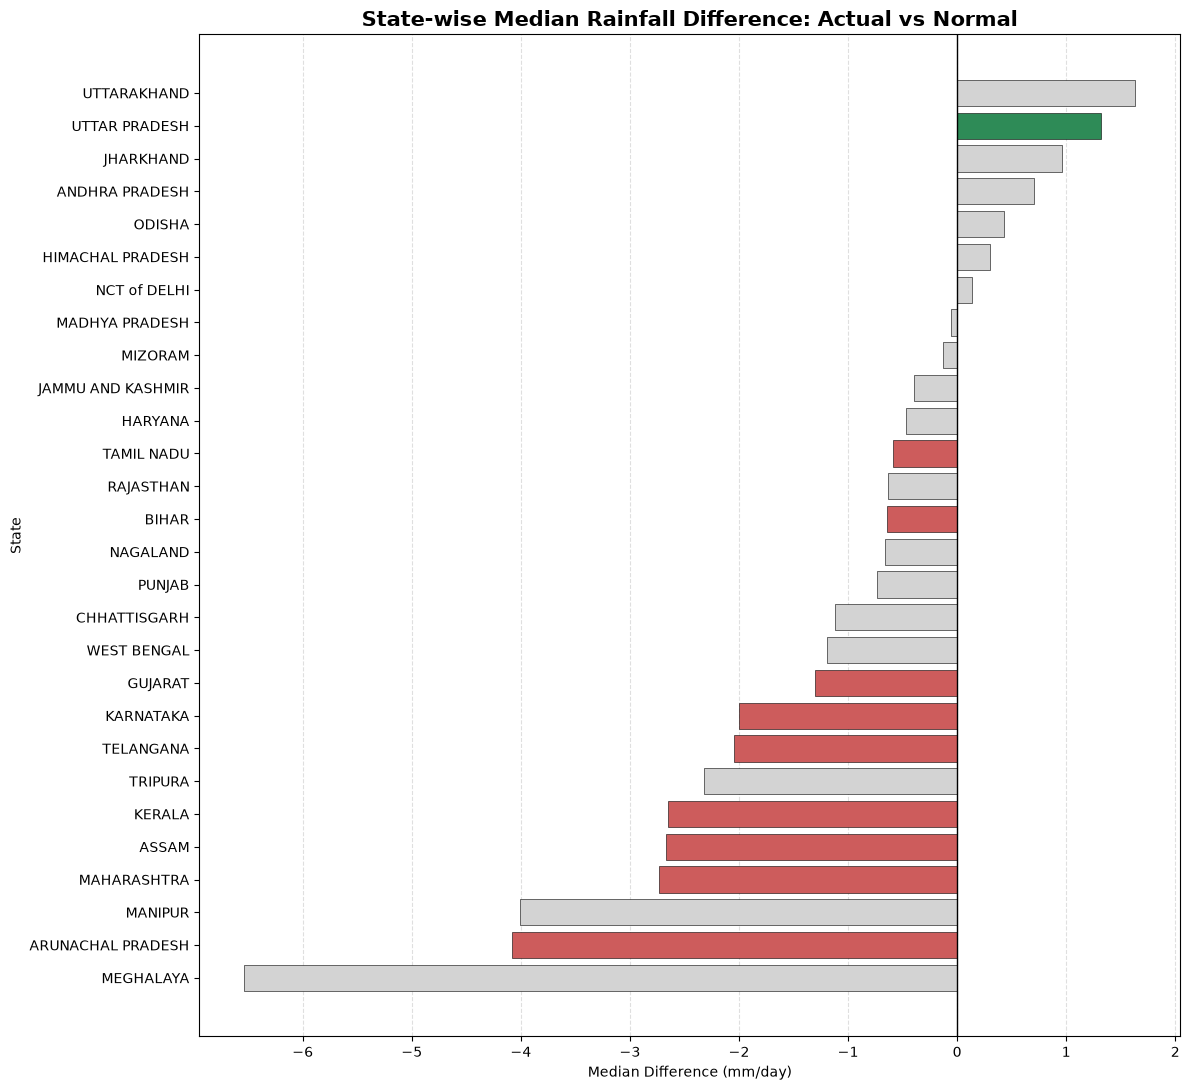

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import os

plot_data = state_wilcoxon_df.sort_values(
    "Median_Difference",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(12, 11))

colors = [
    "seagreen" if sig and diff > 0
    else "indianred" if sig and diff < 0
    else "lightgray"
    for sig, diff in zip(
        plot_data["Significant"],
        plot_data["Median_Difference"]
    )
]

ax.barh(
    plot_data["State"],
    plot_data["Median_Difference"],
    color=colors,
    edgecolor="black",
    linewidth=0.4
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "State-wise Median Rainfall Difference: Actual vs Normal",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Difference (mm/day)")
ax.set_ylabel("State")

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    os.path.join(figure_dir, "statewise_wilcoxon_rainfall_difference.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
print("1. Columns in state_paired_data:")
print(state_paired_data.columns.tolist())

print("\n2. Chhattisgarh in state_group_sizes:")
print(
    state_group_sizes[
        state_group_sizes["State"].str.contains(
            "CHHATTISGARH", case=False, na=False
        )
    ][["State", "District_Count"]]
)

print("\n3. Chhattisgarh in eligible_states:")
print([
    state for state in eligible_states
    if "CHHATTISGARH" in state.upper()
])

print("\n4. Chhattisgarh district records in state_paired_data:")
print(
    state_paired_data[
        state_paired_data["State"].str.contains(
            "CHHATTISGARH", case=False, na=False
        )
    ][["State", "District", "Rainfall_Difference"]].to_string(index=False)
)

print("\n5. Chhattisgarh result in state_wilcoxon_df:")
print(
    state_wilcoxon_df[
        state_wilcoxon_df["State"].str.contains(
            "CHHATTISGARH", case=False, na=False
        )
    ].to_string(index=False)
)

1. Columns in state_paired_data:
['State', 'District', 'Mean_Actual', 'Mean_Normal', 'Rainfall_Difference']

2. Chhattisgarh in state_group_sizes:
          State  District_Count
9  CHHATTISGARH              32

3. Chhattisgarh in eligible_states:
['CHHATTISGARH']

4. Chhattisgarh district records in state_paired_data:
       State District  Rainfall_Difference
CHHATTISGARH    SAKTI            -1.123529

5. Chhattisgarh result in state_wilcoxon_df:
       State  District_Count  Mean_Difference  Median_Difference  Wilcoxon_Statistic  Raw_P_Value  Holm_Adjusted_P  Significant Rainfall_Status
CHHATTISGARH               1        -1.123529          -1.123529                 0.0     0.317311              1.0        False    Below Normal


In [47]:
print("district_balanced shape:", district_balanced.shape)

print("\nAvailable columns:")
for col in district_balanced.columns:
    print(repr(col))

print("\nFirst 5 records:")
display(district_balanced.head())

district_balanced shape: (61795, 22)

Available columns:
'State'
'District'
'Date'
'Daily Actual'
'Daily Normal'
'Daily Departure Per'
'Daily Category'
'Week Date'
'Weekly Actual'
'Weekly Normal'
'Weekly Departure Per'
'Weekly Category'
'Cumulative Date'
'Cumulative Actual'
'Cumulative Normal'
'Cumulative Departue Per'
'Cumulative Category'
'Monthly Date'
'Monthly Acutual'
'Monthly Normal'
'Monthly Departure Per'
'Monthly Category'

First 5 records:


,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly Normal,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,-94.0,LD,13-08-2026 To 19-08-2026,0.5,7.4,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 19-08-2026,186.1,141.5,31.0,E
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,-94.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,432.3,696.3,-38.0,D,From 01-08-2026 To 20-08-2026,186.6,150.9,24.0,E
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,-76.0,LD,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,431.7,686.9,-37.0,D,From 01-08-2026 To 21-08-2026,189.0,160.8,18.0,N
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,31.0,E,13-08-2026 To 19-08-2026,17.5,45.2,...,2026-06-01,444.0,713.3,-38.0,D,From 01-08-2026 To 22-08-2026,198.3,167.9,18.0,N
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,-83.0,LD,13-08-2026 To 19-08-2026,1.3,7.9,...,2026-06-01,445.3,721.2,-38.0,D,From 01-08-2026 To 23-08-2026,199.7,175.8,14.0,N


In [48]:
# Rebuild district-level paired actual vs normal data

paired_data = (
    district_balanced
    .groupby(["State", "District"], as_index=False)
    .agg(
        Mean_Actual=("Daily Actual", "mean"),
        Mean_Normal=("Daily Normal", "mean")
    )
)

paired_data["Rainfall_Difference"] = (
    paired_data["Mean_Actual"] - paired_data["Mean_Normal"]
)

print("Rebuilt paired dataset shape:", paired_data.shape)
print("Unique state-district combinations:",
      paired_data[["State", "District"]].drop_duplicates().shape[0])

# Verify Chhattisgarh
chhattisgarh_check = paired_data[
    paired_data["State"].str.contains(
        "CHHATTISGARH", case=False, na=False
    )
]

print("\nChhattisgarh verification:")
print("District count:", len(chhattisgarh_check))

display(
    chhattisgarh_check[
        ["State", "District", "Mean_Actual",
         "Mean_Normal", "Rainfall_Difference"]
    ]
)

Rebuilt paired dataset shape: (727, 5)
Unique state-district combinations: 727

Chhattisgarh verification:
District count: 1


,State,District,Mean_Actual,Mean_Normal,Rainfall_Difference
148,CHHATTISGARH,SAKTI,3.494118,4.617647,-1.123529


In [49]:
# Compare Chhattisgarh district coverage across datasets

for name, df in [
    ("district_clean", district_clean),
    ("district_analysis", district_analysis),
    ("district_balanced", district_balanced)
]:
    temp = df[
        df["State"].str.contains(
            "CHHATTISGARH", case=False, na=False
        )
    ]

    print(f"\n{name}")
    print("Rows:", len(temp))
    print("Unique districts:", temp["District"].nunique())
    print("District names:")
    print(sorted(temp["District"].dropna().unique().tolist()))


district_clean
Rows: 85
Unique districts: 1
District names:
['SAKTI']

district_analysis
Rows: 85
Unique districts: 1
District names:
['SAKTI']

district_balanced
Rows: 85
Unique districts: 1
District names:
['SAKTI']


In [50]:
# Recalculate state-wise district counts from the current balanced panel

verified_state_counts = (
    district_balanced
    .groupby("State")["District"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="District_Count")
)

print("Total states:", len(verified_state_counts))
print("Total state-district combinations:",
      verified_state_counts["District_Count"].sum())

display(verified_state_counts.to_string(index=False))

print("\nStates with fewer than 5 districts:")
display(
    verified_state_counts[
        verified_state_counts["District_Count"] < 5
    ]
)

Total states: 39
Total state-district combinations: 727


'               State  District_Count\n       UTTAR PRADESH              75\n      MADHYA PRADESH              52\n               BIHAR              38\n         MAHARASHTRA              36\n          TAMIL NADU              36\n               ASSAM              33\n           TELANGANA              33\n             GUJARAT              33\n           RAJASTHAN              33\n         CHHATISGARH              31\n           KARNATAKA              31\n              ODISHA              30\n      ANDHRA PRADESH              26\n           JHARKHAND              24\n              PUNJAB              22\n             HARYANA              22\n   JAMMU AND KASHMIR              20\n         WEST BENGAL              20\n   ARUNACHAL PRADESH              16\n              KERALA              14\n         UTTARAKHAND              13\n    HIMACHAL PRADESH              12\n           MEGHALAYA              11\n            NAGALAND              11\n        NCT of DELHI              10\n           


States with fewer than 5 districts:


,State,District_Count
28,PUDUCHERRY,4
29,ANDAMAN & NICOBAR,3
30,DAMAN & DIU,2
31,SIKKIM,2
32,GOA,2
33,LADAKH,2
34,CHANDIGARH,1
35,LAKSHADWEEP,1
36,DADRA & NAGAR HAVELI,1
37,CHHATTISGARH,1


In [51]:
# Create a clean copy and standardize state names
district_balanced_clean = district_balanced.copy()

district_balanced_clean["State"] = (
    district_balanced_clean["State"]
    .str.strip()
    .str.upper()
    .replace({
        "CHHATISGARH": "CHHATTISGARH",
        "TAMILNADU": "TAMIL NADU"
    })
)

# Recalculate state-wise district counts
verified_state_counts = (
    district_balanced_clean
    .groupby("State")["District"]
    .nunique()
    .reset_index(name="District_Count")
    .sort_values("District_Count", ascending=False)
)

print("Total standardized states:", len(verified_state_counts))
print("Total state-district combinations:",
      verified_state_counts["District_Count"].sum())

print("\nChhattisgarh and Tamil Nadu verification:")
display(
    verified_state_counts[
        verified_state_counts["State"].isin(
            ["CHHATTISGARH", "TAMIL NADU"]
        )
    ]
)

# Rebuild district-level paired data
paired_data = (
    district_balanced_clean
    .groupby(["State", "District"], as_index=False)
    .agg(
        Mean_Actual=("Daily Actual", "mean"),
        Mean_Normal=("Daily Normal", "mean")
    )
)

paired_data["Rainfall_Difference"] = (
    paired_data["Mean_Actual"] - paired_data["Mean_Normal"]
)

print("\nRebuilt paired dataset:", paired_data.shape)

# Select states with at least 5 districts
eligible_states = verified_state_counts.loc[
    verified_state_counts["District_Count"] >= 5,
    "State"
].tolist()

print("\nEligible states:", len(eligible_states))
print("Excluded small groups:",
      len(verified_state_counts) - len(eligible_states))

print("\nChhattisgarh district count in paired data:",
      paired_data.loc[
          paired_data["State"] == "CHHATTISGARH", "District"
      ].nunique())

Total standardized states: 37
Total state-district combinations: 727

Chhattisgarh and Tamil Nadu verification:


,State,District_Count
31,TAMIL NADU,37
6,CHHATTISGARH,32



Rebuilt paired dataset: (727, 5)

Eligible states: 28
Excluded small groups: 9

Chhattisgarh district count in paired data: 32


In [52]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import os

state_paired_data = paired_data[
    paired_data["State"].isin(eligible_states)
].copy()

state_test_results = []

for state, group in state_paired_data.groupby("State"):

    differences = group["Rainfall_Difference"].dropna().to_numpy()

    result = stats.wilcoxon(
        differences,
        alternative="two-sided",
        zero_method="wilcox",
        method="approx"
    )

    state_test_results.append({
        "State": state,
        "District_Count": len(differences),
        "Mean_Difference": np.mean(differences),
        "Median_Difference": np.median(differences),
        "Wilcoxon_Statistic": result.statistic,
        "Raw_P_Value": result.pvalue
    })

state_wilcoxon_df = pd.DataFrame(state_test_results)

# Holm multiple-testing correction
reject, adjusted_p, _, _ = multipletests(
    state_wilcoxon_df["Raw_P_Value"],
    alpha=0.05,
    method="holm"
)

state_wilcoxon_df["Holm_Adjusted_P"] = adjusted_p
state_wilcoxon_df["Significant"] = reject

state_wilcoxon_df["Rainfall_Status"] = np.select(
    [
        state_wilcoxon_df["Median_Difference"] < 0,
        state_wilcoxon_df["Median_Difference"] > 0
    ],
    ["Below Normal", "Above Normal"],
    default="At Normal"
)

state_wilcoxon_df = state_wilcoxon_df.sort_values(
    "Holm_Adjusted_P"
).reset_index(drop=True)

print("=" * 95)
print("CORRECTED STATE-WISE WILCOXON TEST WITH HOLM CORRECTION")
print("=" * 95)

print("States tested:", len(state_wilcoxon_df))
print("Significant states:", state_wilcoxon_df["Significant"].sum())

print("\nCOMPLETE RESULTS:\n")
print(state_wilcoxon_df.round(6).to_string(index=False))

print("\nSIGNIFICANT STATES BY RAINFALL STATUS:")
print(
    state_wilcoxon_df[
        state_wilcoxon_df["Significant"]
    ]["Rainfall_Status"].value_counts()
)

state_wilcoxon_df.to_csv(
    os.path.join(
        table_dir,
        "statewise_actual_vs_normal_wilcoxon_holm_corrected.csv"
    ),
    index=False
)

print("\nCorrected results saved successfully.")

CORRECTED STATE-WISE WILCOXON TEST WITH HOLM CORRECTION
States tested: 28
Significant states: 10

COMPLETE RESULTS:

            State  District_Count  Mean_Difference  Median_Difference  Wilcoxon_Statistic  Raw_P_Value  Holm_Adjusted_P  Significant Rainfall_Status
      MAHARASHTRA              36        -2.893725          -2.732353                 0.0     0.000000         0.000005         True    Below Normal
    UTTAR PRADESH              75         1.476784           1.323529               452.0     0.000000         0.000007         True    Above Normal
          GUJARAT              33        -1.521640          -1.305882                 0.0     0.000001         0.000014         True    Below Normal
            ASSAM              33        -2.885989          -2.669412                 0.0     0.000001         0.000014         True    Below Normal
        TELANGANA              33        -1.913583          -2.043529                 0.0     0.000001         0.000014         True    Be

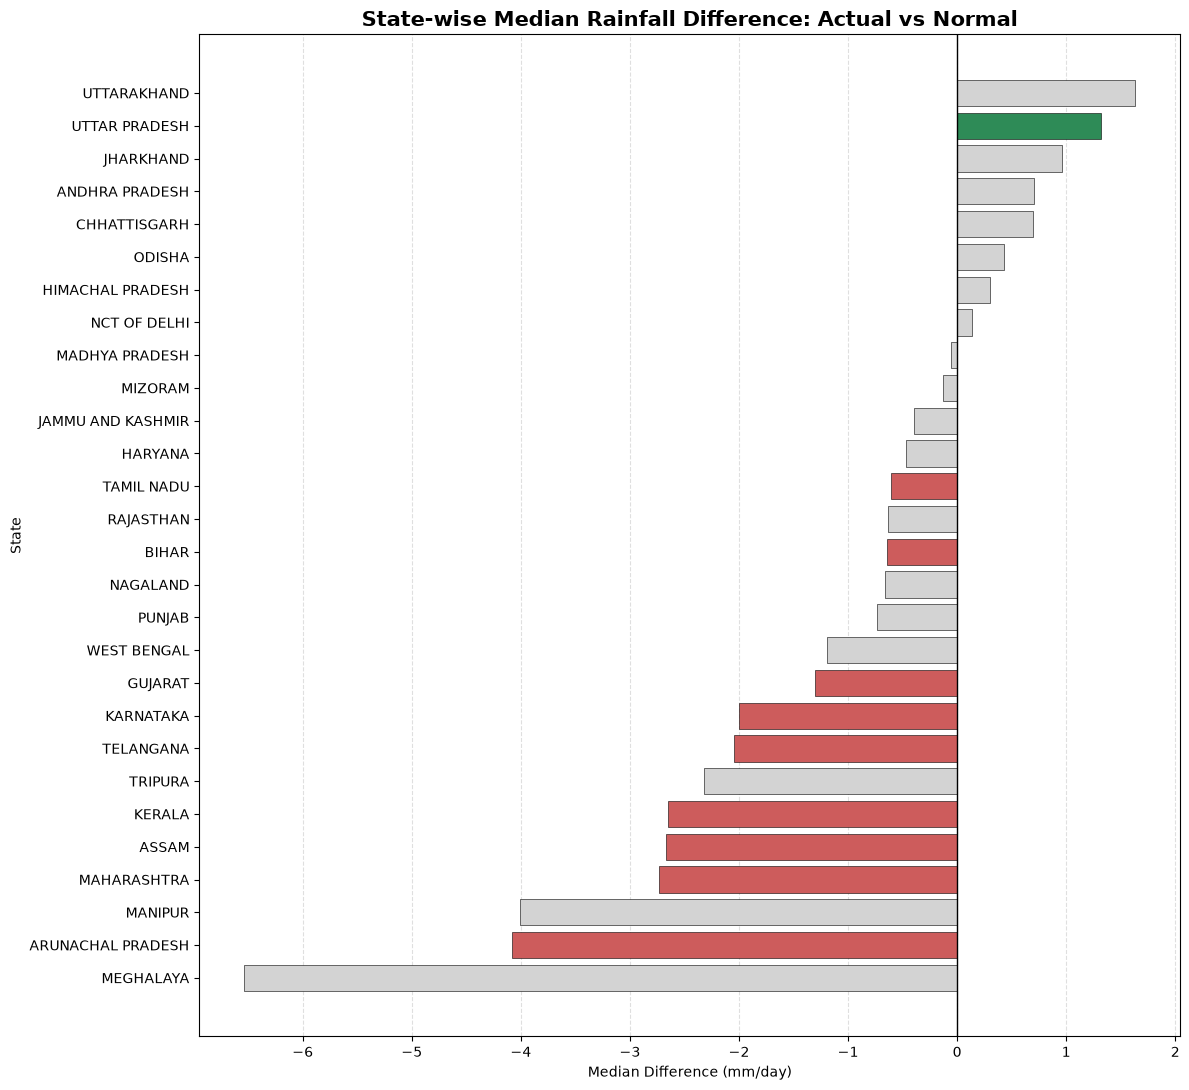

In [53]:
import matplotlib.pyplot as plt
import os

plot_data = state_wilcoxon_df.sort_values(
    "Median_Difference",
    ascending=True
).copy()

colors = [
    "seagreen" if sig and diff > 0
    else "indianred" if sig and diff < 0
    else "lightgray"
    for sig, diff in zip(
        plot_data["Significant"],
        plot_data["Median_Difference"]
    )
]

fig, ax = plt.subplots(figsize=(12, 11))

ax.barh(
    plot_data["State"],
    plot_data["Median_Difference"],
    color=colors,
    edgecolor="black",
    linewidth=0.4
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "State-wise Median Rainfall Difference: Actual vs Normal",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Difference (mm/day)")
ax.set_ylabel("State")

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "statewise_wilcoxon_rainfall_difference_corrected.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Conclusion – Dataset 2: State-wise Rainfall Analysis

The state-wise rainfall analysis provides insights into the spatial distribution and variability of daily rainfall across 36 Indian States and Union Territories during the observation period from **19 August 2026 to 12 November 2026**. The dataset contains 3,060 observations, with 85 reporting dates per state/UT and a common missing date of 31 October 2026.

The analysis revealed considerable differences in average daily rainfall across regions. Andaman & Nicobar Islands recorded the highest mean daily rainfall (13.73 mm), followed by Sikkim (8.66 mm), Mizoram (7.46 mm), Odisha (7.43 mm), and Kerala (6.37 mm). In contrast, Ladakh (0.04 mm), Rajasthan (0.95 mm), Punjab (1.00 mm), Haryana (1.24 mm), and Gujarat (1.49 mm) recorded the lowest mean daily rainfall during the study period.

The examination of rainfall variability and anomalies further highlighted substantial regional differences. Some states experienced higher rainfall variability, while others showed relatively lower rainfall levels throughout the observation window. Comparisons between actual rainfall and normal rainfall also provided useful insights into regional rainfall departures.

However, the analysis identified limitations in the reported percentage departures. Several observations had zero or very small normal rainfall values, resulting in unusually large percentage departures. Therefore, these percentages were not considered reliable as standalone indicators for ranking states.

Overall, Dataset 2 demonstrates that rainfall distribution across Indian States and Union Territories was highly heterogeneous during the selected reporting period. The findings provide a useful descriptive understanding of regional rainfall patterns and complement the long-term historical analysis conducted using Dataset 1. However, because the dataset covers only approximately 85 reporting observations rather than multiple years of climatological records, its findings should not be interpreted as evidence of long-term rainfall trends or climate change.

## Conclusion – Dataset 3: District-wise Rainfall Analysis

The district-wise rainfall analysis provided a detailed understanding of rainfall distribution, spatial variability, and extreme rainfall events across Indian districts during the observation period from **19 August 2026 to 12 November 2026**. The original dataset contained 61,831 records covering 728 districts. For consistent comparisons, a balanced panel of 727 districts with 85 reporting observations each was prepared. Nagapattinam district was excluded from the balanced analysis because it contained only 36 observations. Additionally, 31 October 2026 was missing across the 727 districts.

The descriptive analysis revealed substantial geographical variation in rainfall. North & Middle Andaman recorded the highest mean daily rainfall (19.78 mm), followed by Dr B. R. Ambedkar Konaseema (12.08 mm), Koraput (11.63 mm), and South Andaman (11.24 mm). In contrast, several districts in Rajasthan, Ladakh, and other relatively dry regions recorded very low average rainfall. The analysis of standard deviation and coefficient of variation further demonstrated that rainfall variability differed considerably between districts. Some districts exhibited high absolute variability, while others showed high relative variability due to their low average rainfall.

The temporal analysis of daily district rainfall identified notable rainfall concentration during September, particularly from 24–26 September 2026. The highest spatially averaged daily rainfall occurred on 26 September (13.83 mm), while 25 September recorded the highest individual district rainfall of 231.9 mm in Nabarangapur, Odisha. The analysis also demonstrated that days with high spatially averaged rainfall were not necessarily the days with the largest number of rainy districts, highlighting differences between rainfall intensity and geographical coverage.

The extreme rainfall investigation identified **99 district-day observations with rainfall of at least 100 mm**, including eight observations exceeding 200 mm. These extreme observations were geographically concentrated, with Uttar Pradesh, Andhra Pradesh, Chhattisgarh, Odisha, and Madhya Pradesh accounting for approximately 79.8% of the identified cases. All 99 observations were classified as Large Excess (LE) in the supplied dataset. These findings highlight the importance of examining localized extreme rainfall rather than relying exclusively on state-level or national averages.

The district-wise anomaly analysis also revealed substantial differences between actual and normal rainfall. The paired Wilcoxon signed-rank test identified a statistically significant overall difference between district-level mean actual and normal rainfall (p = 2.638 × 10⁻²⁰), with mean actual rainfall approximately 0.80 mm/day lower than mean normal rainfall across the 727 districts. However, the analysis of percentage departures highlighted reliability concerns where normal rainfall values were zero or very small, producing unusually large percentages.

Overall, Dataset 3 demonstrates that rainfall patterns during the selected observation period were highly heterogeneous across Indian districts, with considerable variation in average rainfall, temporal distribution, rainfall anomalies, and localized extreme events. It complements the

# Overall Conclusion – RainfallRisk India

The project **RainfallRisk India: A Statistical Investigation of Rainfall Variability, Trends and Extreme Precipitation Across India** was undertaken to investigate the spatial and temporal characteristics of rainfall across India using three complementary datasets: long-term gridded rainfall data, state-wise rainfall records, and district-wise rainfall observations.

The first dataset, consisting of daily gridded rainfall records from 2000 to 2025, provided the foundation for examining long-term rainfall variability and trends. The analysis revealed considerable seasonal variation, with the Southwest Monsoon contributing approximately 75.28% of the average annual rainfall over the analyzed spatial footprint. Various extreme precipitation indices, including Rx1day, Rx5day, R10mm, R20mm, CDD, CWD, PRCPTOT, and SDII, were calculated to investigate changes in rainfall intensity, frequency, and dry and wet spell characteristics. Although several grid cells exhibited statistically significant spatial trends, the overall temporal trend tests for the major indices did not remain statistically significant after multiple-testing correction. This indicates that rainfall behaviour varies geographically and that a uniform nationwide trend cannot be established from the analyzed data.

The second dataset provided state-wise rainfall observations for 36 Indian States and Union Territories during the reporting period from 19 August to 12 November 2026. The analysis highlighted substantial differences in average daily rainfall across regions. Andaman & Nicobar Islands, Sikkim, Mizoram, Odisha, and Kerala recorded comparatively higher average rainfall, whereas Ladakh, Rajasthan, Punjab, Haryana, and Gujarat recorded lower averages. The findings demonstrated considerable regional heterogeneity in rainfall distribution during the observation period. Percentage departure values also required careful interpretation because zero or very small normal rainfall values produced unusually large percentages.

The third dataset provided district-level rainfall observations, allowing a more detailed investigation of localized rainfall patterns. The balanced analysis covered 727 districts with 85 reporting observations each, excluding Nagapattinam because of incomplete coverage. The analysis identified substantial differences in average rainfall, variability, and rainfall anomalies across districts. A total of 99 district-day observations recorded rainfall of at least 100 mm, including eight observations exceeding 200 mm. These extreme observations were concentrated in a limited number of geographical regions, particularly Uttar Pradesh, Andhra Pradesh, Chhattisgarh, Odisha, and Madhya Pradesh. The paired Wilcoxon signed-rank test also identified a statistically significant overall difference between actual and normal district-level rainfall during the reporting period, with actual rainfall averaging approximately 0.80 mm/day below normal.

By combining these three datasets, the project demonstrates the importance of examining rainfall at multiple geographical and temporal scales. The historical gridded dataset provides a long-term perspective, the state-wise dataset highlights regional differences, and the district-wise dataset reveals localized rainfall variability and extreme precipitation events. Together, they provide a broader statistical understanding of rainfall behaviour across India than any individual dataset could provide independently.

However, the study has important limitations. The state-wise and district-wise datasets cover only a short reporting period in 2026 and therefore cannot establish long-term climatic trends. The gridded analysis is restricted to its common spatial footprint rather than representing complete geographical coverage of India. Additionally, spatial dependence between neighbouring districts and grid cells may influence statistical inference, and the identified extreme observations were not independently validated against external meteorological records.

In conclusion, **RainfallRisk India demonstrates that rainfall variability across India is geographically heterogeneous, seasonally dependent, and characterized by localized extreme precipitation events.** The study highlights the value of statistical methods, spatial analysis, and multiple rainfall indicators for understanding precipitation patterns. Rather than assuming a uniform increase or decrease in rainfall across the country, the findings emphasize the need to investigate regional differences, rainfall intensity, extreme events, and dry and wet spell behaviour separately.

The project establishes a statistical foundation for further research into rainfall variability and extreme precipitation across India and provides opportunities for future work using longer observational records, improved spatial statistical methods, and independently validated meteorological datasets.